# HealthConnect Rwanda: Healthcare Predictive Analytics & Population Health Intelligence
**AnalystLab Africa – Experience Lab, Week 6 · Data Science Track**

This notebook follows the Data Science track brief end-to-end:
1. Data loading & relationship verification
2. Data cleaning
3. Data validation (Data Quality Report)
4. Integration & feature engineering
5. Exploratory data analysis (patients, clinical, operations, finance, experience)
6. Statistical analysis (descriptives, correlation, hypothesis tests)
7. Predictive analytics (5 tasks), clustering and PCA
8. Evidence-backed business recommendations


**Reading guide – three things to keep in mind throughout**
* The brief lists tables that were **not supplied** (Health Facilities, Laboratory Tests, Prescriptions, Admissions, Referrals). Anything that depends on them is either replaced by a clearly-labelled proxy or marked *not computable*. Nothing is invented.
* Every finding is reported with its sample size and a statistical test where relevant. Where the data show **no** relationship, the notebook says so rather than forcing a story.

In [1]:
import os, re, json, warnings, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")


sns.set_theme(style="whitegrid", context="notebook")
PAL = {"teal":"#0F766E","blue":"#1D4ED8","amber":"#D97706","red":"#B91C1C","grey":"#6B7280","green":"#15803D","purple":"#7C3AED"}
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":150,"axes.titleweight":"bold","axes.titlesize":12,"axes.labelsize":10})

R = {}          # key results, exported to outputs/results.json for the reports
FIGS = []       # figure registry
def savefig(fig, name, title, interp):
    """Adds a one/two-sentence interpretation under every chart (brief requirement) and saves it."""
    fig.suptitle(title, fontsize=13, fontweight="bold", y=0.995)
    wrapped = "\n".join(textwrap.wrap("Interpretation: " + interp, 150))
    fig.text(0.01, -0.02, wrapped, ha="left", va="top", fontsize=8.5, style="italic", color="#374151")
    fig.tight_layout(rect=[0,0,1,0.97])
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight"); FIGS.append(dict(file=str(path), title=title, interpretation=interp))
    plt.show()

In [2]:
DATA_DIR = Path(os.environ.get("HC_DATA_DIR", "../data/raw"))
FIG_DIR, OUT_DIR = Path("../figures"), Path("../data/processed")
FIG_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)
AS_OF = pd.Timestamp("2026-10-24")      # analysis date
SEED = 42
rng = np.random.default_rng(SEED)

## 1. Data loading
All CSVs are loaded with `keep_default_na=False`. This matters: the patient column `ChronicCondition` contains the literal text **"None"** (meaning *no chronic condition*), which pandas would otherwise silently turn into a missing value for ~25% of patients.

In [4]:
def find(pattern):
    files = [f for f in DATA_DIR.glob("*.csv") if re.search(pattern, f.name, re.I)]
    assert len(files) == 1, (pattern, files)
    return files[0]
def load(pattern):
    return pd.read_csv(find(pattern), encoding="utf-8-sig", keep_default_na=False, na_values=[""])

SOURCES = {
 "countries":r"HCCountries", "provinces":r"HC_Provinces", "districts":r"HC_Districts", "sectors":r"HC_Sectors", "villages":r"HC_Villages",
 "ownership":r"Ownership", "departments":r"^HC_Departments", "departments_master":r"Facility_Master", "specialties":r"Specialties",
 "services":r"HC_Services", "equipment":r"Medical_Equipment", "rooms":r"HC_Rooms", "beds":r"HC_Beds",
 "doctors":r"HC_Doctor", "nurses":r"HC_Nurse", "pharmacists":r"^Pharmacist", "lab_scientists":r"Laboratory_Scientist",
 "radiographers":r"Radiographer", "admin_staff":r"Administrative", "patients":r"HC_Patients", "appointments":r"Appointments",
 "diagnoses":r"HC_Diagnoses", "billing":r"HC_Billing", "claims":r"Insurance_Claims", "payments":r"HC_Payments",
 "feedback":r"Patient_Feedback", "revenue_summary":r"Revenue_Summary"}
T = {k: load(v) for k, v in SOURCES.items()}

inventory = pd.DataFrame({"table":list(T), "rows":[len(d) for d in T.values()], "columns":[d.shape[1] for d in T.values()]})
print(f"{len(T)} CSV files loaded, {inventory.rows.sum():,} rows in total")
inventory

27 CSV files loaded, 273,602 rows in total


,table,rows,columns
0,countries,1,6
1,provinces,5,3
2,districts,30,3
3,sectors,120,3
4,villages,480,3
5,ownership,4,2
6,departments,200,3
7,departments_master,200,3
8,specialties,200,3
9,services,400,3


**Tables names not found:** Health Facilities (facility master), Laboratory Tests, Prescriptions, Admissions, Referrals. Facility IDs (HF001–HF020) can only be inferred from the Departments/Rooms tables, and the admission-, length-of-stay-, lab-, prescription- and referral-based analyses cannot be run directly.

In [5]:
MISSING_TABLES = ["Health Facilities (master)", "Laboratory Tests", "Prescriptions", "Admissions", "Referrals"]
R["missing_tables"] = MISSING_TABLES
R["inventory"] = inventory.to_dict("records")

### 1.1 Relationships between datasets
The model is a star-like hierarchy: **Geography** (Country → Province → District → Sector → Village → Patient), **Facility** (Facility → Department → Rooms/Beds/Equipment/Staff/Services) and **Transactions** (Appointment → Diagnosis / Billing → Payment / Claim, and Appointment → Feedback).

In [6]:
def fk(child, ccol, parent, pcol=None, parent_vals=None, label=None):
    c = T[child][ccol] if isinstance(child, str) else child[0]
    vals = set(T[parent][pcol]) if parent_vals is None else parent_vals
    ok = c.isin(vals)
    return dict(relationship=label or f"{child}.{ccol} -> {parent}.{pcol}", child_rows=len(c), valid=int(ok.sum()), orphans=int((~ok).sum()), pct_valid=round(100*ok.mean(),2))

FAC = set(T["departments"].FacilityID)           # facility master is missing -> inferred from Departments
staff_tables = ["doctors","nurses","pharmacists","lab_scientists","radiographers","admin_staff"]
rels = [
 fk("provinces","CountryID","countries","CountryID"), fk("districts","ProvinceID","provinces","ProvinceID"),
 fk("sectors","DistrictID","districts","DistrictID"), fk("villages","SectorID","sectors","SectorID"),
 fk("patients","VillageID","villages","VillageID"),
 fk("departments","FacilityID",None,parent_vals=FAC,label="departments.FacilityID -> facility set (inferred)"),
 fk("specialties","DepartmentID","departments","DepartmentID"), fk("services","DepartmentID","departments","DepartmentID"),
 fk("equipment","DepartmentID","departments","DepartmentID"), fk("rooms","DepartmentID","departments","DepartmentID"),
 fk("beds","RoomID","rooms","RoomID"),
]
for s in staff_tables:
    rels.append(fk(s,"DepartmentID","departments","DepartmentID"))
rels += [
 fk("appointments","PatientID","patients","PatientID"), fk("appointments","DoctorID","doctors","StaffID"),
 fk("appointments","DepartmentID","departments","DepartmentID"),
 fk("appointments","FacilityID",None,parent_vals=FAC,label="appointments.FacilityID -> facility set (inferred)"),
 fk("diagnoses","AppointmentID","appointments","AppointmentID"), fk("billing","AppointmentID","appointments","AppointmentID"),
 fk("payments","BillingID","billing","BillingID"), fk("claims","BillingID","billing","BillingID"),
 fk("feedback","AppointmentID","appointments","AppointmentID")]
rel_df = pd.DataFrame(rels)
R["fk_checks"] = rel_df.to_dict("records")
rel_df

,relationship,child_rows,valid,orphans,pct_valid
0,provinces.CountryID -> countries.CountryID,5,5,0,100.00
1,districts.ProvinceID -> provinces.ProvinceID,30,30,0,100.00
2,sectors.DistrictID -> districts.DistrictID,120,120,0,100.00
3,villages.SectorID -> sectors.SectorID,480,480,0,100.00
4,patients.VillageID -> villages.VillageID,20000,20000,0,100.00
5,departments.FacilityID -> facility set (inferred),200,200,0,100.00
6,specialties.DepartmentID -> departments.Depart...,200,200,0,100.00
7,services.DepartmentID -> departments.DepartmentID,400,400,0,100.00
8,equipment.DepartmentID -> departments.Departme...,200,200,0,100.00
9,rooms.DepartmentID -> departments.DepartmentID,400,400,0,100.00


**Finding - orphaned transactions.** Diagnoses, Billing and Payments each hold 60,000 rows, but only **5,000** appointments exist, so about 91.7% of those rows point to appointment IDs that are not in the Appointments table (APT005001–APT060000). The `HC_Revenue_Summary` appointment counts add to ~60.8k, which suggests the Appointments extract is a truncated sample of a ~60k-appointment system. All clinical analysis therefore runs on the **5,000 linked appointments**, while billing/payment/claim analysis that does not need appointment attributes uses the full 60,000 bills.

**Finding - hierarchy conflicts.** The *Departments*, *Rooms* and *Equipment* tables are internally consistent, but appointments are not: the facility recorded on an appointment matches the facility that owns the appointment's department in only ~5% of rows, and the same holds for the doctor's home facility/department.

In [7]:
dept_fac = T["departments"].set_index("DepartmentID").FacilityID
dept_name = T["departments"].set_index("DepartmentID").DepartmentName
doc = T["doctors"].set_index("StaffID")
a = T["appointments"]
hier = pd.DataFrame([
  dict(check="Appointment.FacilityID == facility owning Appointment.DepartmentID", match_pct=round(100*(a.FacilityID == a.DepartmentID.map(dept_fac)).mean(),2)),
  dict(check="Appointment.FacilityID == Doctor home facility",                     match_pct=round(100*(a.FacilityID == a.DoctorID.map(doc.FacilityID)).mean(),2)),
  dict(check="Appointment.DepartmentID == Doctor home department",                 match_pct=round(100*(a.DepartmentID == a.DoctorID.map(doc.DepartmentID)).mean(),2)),
  dict(check="Rooms.FacilityID == facility owning Rooms.DepartmentID",             match_pct=round(100*(T['rooms'].FacilityID == T['rooms'].DepartmentID.map(dept_fac)).mean(),2)),
  dict(check="Equipment.FacilityID == facility owning Equipment.DepartmentID",     match_pct=round(100*(T['equipment'].FacilityID == T['equipment'].DepartmentID.map(dept_fac)).mean(),2)),
  dict(check="Staff.FacilityID == facility owning Staff.DepartmentID (doctors)",   match_pct=round(100*(T['doctors'].FacilityID == T['doctors'].DepartmentID.map(dept_fac)).mean(),2))])
R["hierarchy_checks"] = hier.to_dict("records")
hier

,check,match_pct
0,Appointment.FacilityID == facility owning Appo...,5.12
1,Appointment.FacilityID == Doctor home facility,5.14
2,Appointment.DepartmentID == Doctor home depart...,0.64
3,Rooms.FacilityID == facility owning Rooms.Depa...,100.00
4,Equipment.FacilityID == facility owning Equipm...,100.00
5,Staff.FacilityID == facility owning Staff.Depa...,4.86


## 2. Data cleaning
Every issue found is recorded in a running **data-quality log** (`dq`) with its record count, the action taken and a severity. This log becomes the Data Quality Report.
Principle: **flag, don't delete** unless a record is provably invalid; deleting would silently change the population being studied.

In [ ]:
dq = []
def note(table, issue, n, action, severity="Info"):
    dq.append(dict(Table=table, Issue=issue, Records=int(n), Action=action, Severity=severity))

# 2.1 Missing values 
miss = {k: int(d.isna().sum().sum()) for k, d in T.items()}
tot_missing = sum(miss.values())
print("Missing cells across all 27 tables:", tot_missing)
note("patients","ChronicCondition contains the text 'None' (no chronic condition) - default parsers read it as missing",
     (T["patients"].ChronicCondition=="None").sum(),"Kept as a valid category 'None' (loaded with keep_default_na=False)","Medium")
note("ALL","True missing values (blank cells) across all 27 tables", tot_missing, "None required", "Info")

Missing cells across all 27 tables: 0


In [9]:
# 2.2 Duplicates 
keys = {"patients":"PatientID","appointments":"AppointmentID","diagnoses":"DiagnosisID","billing":"BillingID",
        "payments":"PaymentID","claims":"ClaimID","feedback":"FeedbackID","beds":"BedID","rooms":"RoomID"}
dup_rows = {k: int(T[k].duplicated().sum()) for k in T}
dup_keys = {k: int(T[k][c].duplicated().sum()) for k, c in keys.items()}
all_staff = pd.concat([T[s].assign(Source=s) for s in staff_tables], ignore_index=True)
dup_keys["staff (all 6 rosters)"] = int(all_staff.StaffID.duplicated().sum())
note("ALL","Fully duplicated rows", sum(dup_rows.values()), "None found - nothing removed", "Info")
note("ALL","Duplicate primary keys (patients, appointments, diagnoses, billing, payments, claims, feedback, beds, rooms, staff)", sum(dup_keys.values()), "None found - nothing removed", "Info")
note("departments","HC_Departments and HC_Facility_Master_Data (Departments) are identical copies", len(T["departments"]), "Used one copy" , "Low") if T["departments"].equals(T["departments_master"]) else None


In [10]:
# 2.3 Patients: types, dates, standardisation 
p = T["patients"].copy()
for c in ["Gender","MaritalStatus","Occupation","Education","BloodGroup","ChronicCondition","Status"]:
    p[c] = p[c].astype(str).str.strip().str.title() if c != "BloodGroup" else p[c].astype(str).str.strip().str.upper()
p["DateOfBirth"] = pd.to_datetime(p.DateOfBirth, format="%m/%d/%Y", errors="coerce")
note("patients","DateOfBirth stored as text 'm/d/yyyy' (and every DOB falls on 1 January)", p.DateOfBirth.dt.strftime("%m-%d").eq("01-01").sum(),
     "Converted to datetime; day/month carry no information so only birth YEAR is reliable","Medium")
_m, _d = p.DateOfBirth.dt.month, p.DateOfBirth.dt.day
p["Age_check"] = AS_OF.year - p.DateOfBirth.dt.year - ((_m > AS_OF.month) | ((_m == AS_OF.month) & (_d > AS_OF.day))).astype(int)
bad_age = (p.Age != p.Age_check) | (p.Age < 0) | (p.Age > 110)
note("patients","Impossible/inconsistent ages (Age outside 0-110 or inconsistent with DOB)", bad_age.sum(), "Age consistent with DOB for all patients - kept","Info")

In [11]:
# phone
p["Phone_clean"] = p.Phone.round().astype("Int64").astype(str)
note("patients","Phone saved in scientific notation (e.g. 2.50788E+11) -> only 6 significant digits survive; only %d distinct values in 20,000 rows" % p.Phone.nunique(),
     len(p),"Converted to text; Phone cannot identify duplicate patients or contact anyone - excluded from analysis","High")

In [12]:
# duplicates by demographics
loose = p.duplicated(["FirstName","LastName","Gender","DateOfBirth"], keep=False)
strict = p.duplicated(["FirstName","LastName","Gender","DateOfBirth","VillageID","BloodGroup","HeightCm","WeightKg"], keep=False)
note("patients","Possible duplicate patients on name+sex+DOB (name pool = %d first x %d last names; DOB always 1 Jan)" % (p.FirstName.nunique(), p.LastName.nunique()),
     loose.sum(),"Not treated as duplicates - identical by construction of a small name pool; PatientID is the only reliable key","Medium")
note("patients","Possible duplicates on name+sex+DOB+village+blood group+height+weight", strict.sum(), "Stricter key finds none/very few - nothing removed","Info" if strict.sum()<20 else "Medium")

In [13]:
# physiology
child = p.Age < 12
phys = child & ((p.HeightCm >= 130) | (p.WeightKg >= 35))
note("patients","Children under 12 with adult-range height/weight (height 140-190 cm, weight 40-120 kg recorded for all ages)", phys.sum(),
     "Height/weight/BMI treated as unreliable for under-18s: BMI_clean set to missing for Age<18","High")
p["BMI_clean"] = p.BMI.where(p.Age >= 18)
bmi_ext = (p.BMI_clean < 15) | (p.BMI_clean > 50)
note("patients","Adult BMI outside 15-50 (extreme but arithmetically correct: BMI = weight/height^2 matches in 100% of rows)", bmi_ext.sum(),
     "Kept and flagged (BMI_extreme); weight/height appear independently random","Medium")
p["BMI_extreme"] = bmi_ext.fillna(False)

In [14]:
# plausibility of social attributes for minors
minor = p.Age < 18
mar = minor & p.MaritalStatus.isin(["Married","Widowed"])
edu = ((p.Education=="Master") & (p.Age<22)) | ((p.Education=="Bachelor") & (p.Age<20)) | ((p.Education=="Diploma") & (p.Age<17))
occ = (p.Age < 16) & p.Occupation.isin(["Nurse","Engineer","Teacher","Civil Servant","Driver","Trader"])
note("patients","Under-18s recorded as Married/Widowed", mar.sum(), "Flagged (implausible_profile); MaritalStatus excluded from models","Medium")
note("patients","Education level impossible for age (e.g. Master's under 22)", edu.sum(), "Flagged; Education excluded from models","Medium")
note("patients","Skilled occupation recorded for children under 16", occ.sum(), "Flagged; Occupation excluded from models","Medium")
p["implausible_profile"] = mar | edu | occ
note("patients","Gender is not consistent with first name (e.g. 'Patrick' recorded Female; every name is ~50/50 male/female)", len(p),"Gender field used as recorded; names not used to infer sex","Low")
note("patients","Every patient (100%) has an InsuranceID (15 plans); there is no 'uninsured' category and no insurance master table", len(p),
     "Insurance coverage analysed through claims filed at billing level instead (see 4.2)","High")
note("patients","No registration date -> true patient-growth trend cannot be computed", len(p),"Proxy: cumulative unique patients by first appointment date","Medium")
note("patients","Blood group AB- never occurs (7 of 8 ABO/Rh groups) and group frequencies are uniform (O+ is normally most common)", len(p),"Used as recorded; flagged as a sign of simulated data","Low")
note("patients","Status = Active for 100% of patients (no variance)", len(p),"Column dropped from modelling","Low")

In [15]:
# geography
geo = (T["villages"].merge(T["sectors"], on="SectorID").merge(T["districts"], on="DistrictID").merge(T["provinces"], on="ProvinceID"))
p = p.merge(geo[["VillageID","SectorID","DistrictID","DistrictName","ProvinceID","ProvinceName"]], on="VillageID", how="left")
note("districts/sectors/villages","District, sector and village names are placeholders ('District 1', 'Sector 1', ...)", len(T["districts"]),
     "Province is the finest usable geographic level; no map geometry is possible","Medium")
age_bins = [-1,4,14,24,34,44,54,64,74,200]; age_lbl = ["0-4","5-14","15-24","25-34","35-44","45-54","55-64","65-74","75+"]
p["AgeGroup"] = pd.cut(p.Age, age_bins, labels=age_lbl)
p["AgeBand3"] = pd.cut(p.Age, [-1,17,59,200], labels=["Child (<18)","Adult (18-59)","Older (60+)"])
p["HasChronic"] = (p.ChronicCondition != "None").astype(int)

In [ ]:
# 2.4 Appointments 
ap = T["appointments"].copy()
ap["Date"] = pd.to_datetime(ap.Date, errors="coerce")
ap["VisitType"] = ap.VisitType.str.strip().str.title()
note("appointments","Unparseable dates", ap.Date.isna().sum(), "None - Date converted to datetime", "Info")
fut = ap.Date > AS_OF
note("appointments","Appointments dated AFTER the analysis date (24 Oct 2026) yet carrying diagnoses, bills and feedback", fut.sum(),
     "Flagged (future_dated); retained because they are indistinguishable from the rest of the 2026 series - results shown with and without them where it matters","High")
ap["future_dated"] = fut
ap["Month"] = ap.Date.dt.to_period("M"); ap["Weekday"] = ap.Date.dt.day_name(); ap["Quarter"] = ap.Date.dt.quarter
dfm = ap.FacilityID == ap.DepartmentID.map(dept_fac)
note("appointments","Appointment facility differs from the facility that owns the appointment's department", (~dfm).sum(),
     "Flagged. Facility-level analysis uses the recorded Appointment.FacilityID; department-level analysis uses department TYPE (10 types, identical across facilities). Ranking sensitivity tested in 5.3","Critical")
ap["dept_fac_match"] = dfm
ap["doc_fac_match"] = ap.FacilityID == ap.DoctorID.map(doc.FacilityID)
ap["doc_dept_match"] = ap.DepartmentID == ap.DoctorID.map(doc.DepartmentID)
note("appointments","Doctor's home department differs from the appointment's department", (~ap.doc_dept_match).sum(), "Flagged; doctor workload computed per DoctorID regardless of department","High")
note("appointments","Facility IDs not in HF001-HF020 / Department IDs not in master", (~ap.FacilityID.isin(FAC)).sum() + (~ap.DepartmentID.isin(dept_fac.index)).sum(), "None invalid","Info")
ap["DepartmentName"] = ap.DepartmentID.map(dept_name)

In [ ]:
# 2.5 Diagnoses / billing / payments / claims / feedback 
dx = T["diagnoses"].copy()
dx["Severity"] = pd.Categorical(dx.Severity.str.strip().str.title(), ["Mild","Moderate","Severe"], ordered=True)
dx["Diagnosis"] = dx.Diagnosis.str.strip()
bl = T["billing"].merge(T["payments"], on="BillingID", how="left", validate="1:1")
cl = T["claims"].copy()
bl = bl.merge(cl.rename(columns={"Status":"ClaimStatus"}), on="BillingID", how="left", validate="1:1")
bl["HasClaim"] = bl.ClaimID.notna()
bl["Outstanding"] = bl.Amount - bl.AmountPaid
bl["PaidRatio"] = bl.AmountPaid / bl.Amount
bl["LinkedToAppointment"] = bl.AppointmentID.isin(ap.AppointmentID)
note("billing","Bills whose AppointmentID is not in the Appointments table (orphans)", (~bl.LinkedToAppointment).sum(), "Retained in the 60k bill-level analysis; excluded from appointment-level modelling","Critical")
note("diagnoses","Diagnoses whose AppointmentID is not in Appointments", (~dx.AppointmentID.isin(ap.AppointmentID)).sum(), "Excluded from appointment-level analysis","Critical")
note("payments","Payment rows whose bill's appointment is missing", (~bl.LinkedToAppointment).sum(), "As billing","Critical")
note("feedback","Feedback rows whose AppointmentID is not in Appointments", (~T["feedback"].AppointmentID.isin(ap.AppointmentID)).sum(),
     "Used only for hospital-wide rating distribution; facility/department satisfaction uses the linked rows","Critical")
inv_bill = (bl.Amount <= 0) | bl.Amount.isna()
note("billing","Invalid billing amounts (<=0 or missing)", inv_bill.sum(), "None invalid (range 10,002 - 299,998 RWF)", "Info")
note("payments","Payments exceeding the billed amount", (bl.AmountPaid > bl.Amount).sum(), "None","Info")
note("claims","Claims exceeding the billed amount", (bl.ClaimAmount > bl.Amount).sum(), "None (claims are 50-100% of the bill)","Info")
st_paid_short = ((bl.Status=="Paid") & (bl.Outstanding > 0)).sum()
st_pend_full = ((bl.Status!="Paid") & (bl.Outstanding == 0)).sum()
note("billing","Bills marked 'Paid' whose payment is below the bill amount", st_paid_short, "Billing.Status treated as unreliable; Outstanding recomputed as Amount - AmountPaid","High")
note("billing","Bills marked 'Pending'/'Partially Paid' that are fully paid", st_pend_full, "As above","High")
nc_ins = ((bl.Method=="Insurance") & ~bl.HasClaim).sum()
note("payments","Payment method 'Insurance' but no insurance claim exists for the bill", nc_ins, "Flagged; claim presence (not payment method) defines insurance-backed bills","Medium")
fb = T["feedback"].copy()
fb["CommentScore"] = fb.Comment.map({"Poor":1,"Average":2,"Good":3,"Excellent":4})
contra = ((fb.Rating <= 2) & fb.Comment.isin(["Good","Excellent"])) | ((fb.Rating >= 4) & (fb.Comment == "Poor"))
rho_fb = stats.spearmanr(fb.Rating, fb.CommentScore)
note("feedback","Rating contradicts the text comment (e.g. rating 1 with 'Excellent', rating 5 with 'Poor')", contra.sum(),
     "Rating (numeric) used as the satisfaction measure; Comment ignored (Spearman rho Rating~Comment = %.3f)" % rho_fb.statistic, "High")
rs_rev, rs_app, bill_tot = T["revenue_summary"].Revenue.sum(), T["revenue_summary"].Appointments.sum(), T["billing"].Amount.sum()
note("revenue_summary","Revenue_Summary does not reconcile with Billing (summary total %.2fbn RWF vs %.2fbn billed across 60,000 bills; %s summary appointments vs 5,000 appointment records)" % (rs_rev/1e9, bill_tot/1e9, f"{rs_app:,}"), 12,
     "Treated as a separate management series; both are modelled and compared","High")
note("beds","All 2,000 beds have Status = 'Available' (no occupied beds recorded)", len(T["beds"]), "Bed occupancy/utilisation is NOT computable","High")
note("equipment","No status/availability or usage field on equipment - availability and utilisation not computable", len(T["equipment"]), "Only distribution analysed","Medium")
note("feedback/claims","Insurance claims have only Approved/Pending statuses (no Rejected); Billing has no payment dates", len(cl), "Claim-rejection prediction and days-to-pay analysis not possible","Medium")
note("ALL","No Admissions, Length-of-Stay, Laboratory, Prescription or Referral tables", 0, "Admission modelled through a labelled proxy (4.4); LOS, lab, prescription and referral analyses marked not computable","Critical")

## 3. Data validation 

In [18]:
val = pd.DataFrame([
 dict(Check="Foreign-key relationships", Result=f"{int((rel_df.orphans>0).sum())} of {len(rel_df)} relationships have orphans", Detail="All orphans sit in the transaction chain (Billing, Diagnoses, Payments, Feedback -> Appointments); reference tables are clean"),
 dict(Check="Duplicate Patient IDs", Result=int(dup_keys["patients"]), Detail="PatientID unique across 20,000 patients"),
 dict(Check="Duplicate Appointment IDs", Result=int(dup_keys["appointments"]), Detail="AppointmentID unique across 5,000 appointments"),
 dict(Check="Invalid Facility IDs (outside HF001-HF020)", Result=int((~ap.FacilityID.isin(FAC)).sum()), Detail="But facility on appointment disagrees with department's facility in %.1f%% of rows" % (100*(~ap.dept_fac_match).mean())),
 dict(Check="Invalid Department IDs", Result=int((~ap.DepartmentID.isin(dept_fac.index)).sum()), Detail="All 200 department IDs valid"),
 dict(Check="Impossible ages", Result=int(bad_age.sum()), Detail="Ages 0-90; consistent with DOB. But %d children <12 have adult-range height/weight" % phys.sum()),
 dict(Check="Invalid billing amounts", Result=int(inv_bill.sum()), Detail="All amounts positive; payments and claims never exceed bills; but Status labels contradict payments"),
])
R["validation"] = val.astype(str).to_dict("records")
val

,Check,Result,Detail
0,Foreign-key relationships,3 of 26 relationships have orphans,All orphans sit in the transaction chain (Bill...
1,Duplicate Patient IDs,0,"PatientID unique across 20,000 patients"
2,Duplicate Appointment IDs,0,"AppointmentID unique across 5,000 appointments"
3,Invalid Facility IDs (outside HF001-HF020),0,But facility on appointment disagrees with dep...
4,Invalid Department IDs,0,All 200 department IDs valid
5,Impossible ages,0,Ages 0-90; consistent with DOB. But 2594 child...
6,Invalid billing amounts,0,All amounts positive; payments and claims neve...


In [23]:
dq_df = pd.DataFrame(dq)
order = {"Critical":0,"High":1,"Medium":2,"Low":3,"Info":4}
dq_df = dq_df.sort_values("Severity", key=lambda s: s.map(order), kind="stable").reset_index(drop=True)
dq_df.to_csv(OUT_DIR/"data_quality_report.csv", index=False)

In [24]:
R["dq_log"] = dq_df.to_dict("records")
R["dq_counts"] = dq_df.Severity.value_counts().to_dict()
print(dq_df.Severity.value_counts().to_string())
dq_df

Severity
Medium      12
High        10
Info        10
Critical     6
Low          4


,Table,Issue,Records,Action,Severity
0,appointments,Appointment facility differs from the facility...,4744,Flagged. Facility-level analysis uses the reco...,Critical
1,billing,Bills whose AppointmentID is not in the Appoin...,55000,Retained in the 60k bill-level analysis; exclu...,Critical
2,diagnoses,Diagnoses whose AppointmentID is not in Appoin...,55000,Excluded from appointment-level analysis,Critical
3,payments,Payment rows whose bill's appointment is missing,55000,As billing,Critical
4,feedback,Feedback rows whose AppointmentID is not in Ap...,19308,Used only for hospital-wide rating distributio...,Critical
5,ALL,"No Admissions, Length-of-Stay, Laboratory, Pre...",0,Admission modelled through a labelled proxy (4...,Critical
6,patients,Phone saved in scientific notation (e.g. 2.507...,20000,Converted to text; Phone cannot identify dupli...,High
7,patients,Children under 12 with adult-range height/weig...,2594,Height/weight/BMI treated as unreliable for un...,High
8,patients,Every patient (100%) has an InsuranceID (15 pl...,20000,Insurance coverage analysed through claims fil...,High
9,appointments,Appointments dated AFTER the analysis date (24...,874,Flagged (future_dated); retained because they ...,High


## 4. Data integration & feature engineering
### 4.1 Integrated analytical dataset (one row per appointment)
Joins: Appointments ← Patients (+geography) ← Diagnoses ← Billing/Payments/Claims ← Feedback ← Doctor ← Department. Join cardinality is asserted so a bad key can't silently multiply rows.

In [25]:
doc_cols = T["doctors"][["StaffID","YearsExperience","Specialty","FacilityID","DepartmentID"]].rename(
    columns={"StaffID":"DoctorID","YearsExperience":"DoctorYears","Specialty":"DoctorSpecialty","FacilityID":"DoctorHomeFacility","DepartmentID":"DoctorHomeDept"})
pcols = ["PatientID","Gender","Age","AgeGroup","AgeBand3","DateOfBirth","MaritalStatus","Education","Occupation","BloodGroup","InsuranceID","ChronicCondition","HasChronic",
         "HeightCm","WeightKg","BMI","BMI_clean","BMI_extreme","implausible_profile","VillageID","DistrictID","ProvinceID","ProvinceName"]
bcols = ["AppointmentID","BillingID","Amount","Status","AmountPaid","Method","Outstanding","PaidRatio","HasClaim","ClaimID","Provider","ClaimAmount","ClaimStatus"]
df = (ap.merge(p[pcols], on="PatientID", how="left", validate="m:1")
        .merge(dx[["AppointmentID","Diagnosis","Severity"]], on="AppointmentID", how="left", validate="1:1")
        .merge(bl[bcols].rename(columns={"Status":"BillStatus","Amount":"BillAmount","Method":"PayMethod"}), on="AppointmentID", how="left", validate="1:1")
        .merge(fb[["AppointmentID","Rating","Comment"]], on="AppointmentID", how="left", validate="1:1")
        .merge(doc_cols, on="DoctorID", how="left", validate="m:1"))
assert len(df) == len(ap) == 5000
print("Integrated dataset:", df.shape, "| diagnosis linked:", df.Diagnosis.notna().mean().round(3), "| billing linked:", df.BillAmount.notna().mean().round(3), "| feedback linked:", df.Rating.notna().sum())

Integrated dataset: (5000, 57) | diagnosis linked: 1.0 | billing linked: 1.0 | feedback linked: 1756


### 4.2 Feature engineering
The ten features required by the brief (plus helpers). **Length-of-Stay Category cannot be built** because no admissions/discharge data exist; it is listed in the feature table as *not computable*.

In [27]:
df = df.sort_values(["PatientID","Date","AppointmentID"]).reset_index(drop=True)
df["PriorVisits"]    = df.groupby("PatientID").cumcount()
df["PatientVisits"]  = df.groupby("PatientID").AppointmentID.transform("count")
df["FrequentVisitor"] = (df.PatientVisits >= 2).astype(int)                          # (3) returning patients
df["SeverityScore"]  = df.Severity.cat.codes + 1                                       # (7) Mild=1 Moderate=2 Severe=3
df["HighAcuityEmergency"] = ((df.VisitType == "Emergency") & (df.Severity == "Severe")).astype(int)   # admission PROXY
df["InsuranceCoverageCat"] = np.select([df.ClaimStatus.eq("Approved"), df.ClaimStatus.eq("Pending")], ["Claim approved","Claim pending"], "Self-pay (no claim)")  # (5)
rev_bins = np.quantile(bl.Amount, [0,1/3,2/3,1]); rev_bins[0], rev_bins[-1] = 0, np.inf
df["RevenueCategory"] = pd.cut(df.BillAmount, rev_bins, labels=["Low","Medium","High"])                       # (6) tertiles of all 60k bills
df["SatisfactionCategory"] = pd.cut(df.Rating, [0,2,3,5], labels=["Low (1-2)","Medium (3)","High (4-5)"])         # (9)
df["Month"] = df.Date.dt.to_period("M"); df["MonthNum"] = df.Date.dt.month; df["WeekdayNum"] = df.Date.dt.dayofweek

In [ ]:
# (2) High-risk patient indicator: rule-based, documented, patient-level
sev_max = df.groupby("PatientID").SeverityScore.max()
p["MaxSeverity"] = p.PatientID.map(sev_max)
p["HighRisk"] = (((p.Age >= 65) & (p.HasChronic == 1)) | ((p.HasChronic == 1) & (p.MaxSeverity == 3))).astype(int)
df["HighRiskPatient"] = df.PatientID.map(p.set_index("PatientID").HighRisk)

In [28]:
# (10) Department workload index and staff
clin = all_staff[all_staff.Role != "Administrative Staff"]
dep = T["departments"].copy()
dep["ClinicalStaff"] = dep.DepartmentID.map(clin.groupby("DepartmentID").size()).fillna(0).astype(int)
dep["Doctors"] = dep.DepartmentID.map(T["doctors"].groupby("DepartmentID").size()).fillna(0).astype(int)
dep["Nurses"]  = dep.DepartmentID.map(T["nurses"].groupby("DepartmentID").size()).fillna(0).astype(int)
dep["Appointments"] = dep.DepartmentID.map(df.groupby("DepartmentID").size()).fillna(0).astype(int)
dep["ApptPerStaff"] = dep.Appointments / dep.ClinicalStaff.replace(0, np.nan)
dep["WorkloadIndex"] = 100 * dep.ApptPerStaff / dep.ApptPerStaff.mean()
df["DeptWorkloadIndex"] = df.DepartmentID.map(dep.set_index("DepartmentID").WorkloadIndex)

In [29]:
# (8) Facility performance score (equal-weight composite of 4 z-scores, T-score scaled)
fac = pd.DataFrame(index=sorted(FAC)); fac.index.name = "FacilityID"
g = df.groupby("FacilityID")
fac["Appointments"] = g.size(); fac["UniquePatients"] = g.PatientID.nunique()
fac["EmergencyShare"] = g.VisitType.apply(lambda s: (s=="Emergency").mean()); fac["SevereShare"] = g.Severity.apply(lambda s: (s=="Severe").mean())
fac["Billed"] = g.BillAmount.sum(); fac["Collected"] = g.AmountPaid.sum(); fac["CollectionRate"] = fac.Collected/fac.Billed
fac["ClaimApprovalRate"] = g.apply(lambda d: (d.ClaimStatus=="Approved").sum()/max(d.ClaimStatus.notna().sum(),1))
fac["MeanRating"] = g.Rating.mean(); fac["RatingN"] = g.Rating.count()
fac["Doctors"]  = T["doctors"].groupby("FacilityID").size(); fac["Nurses"] = T["nurses"].groupby("FacilityID").size()
fac["ClinicalStaff"] = clin.groupby("FacilityID").size(); fac["AllStaff"] = all_staff.groupby("FacilityID").size()
fac["Rooms"] = T["rooms"].groupby("FacilityID").size(); fac["Beds"] = T["beds"].merge(T["rooms"], on="RoomID").groupby("FacilityID").size()
fac["Equipment"] = T["equipment"].groupby("FacilityID").size()
fac["ApptPerDoctor"] = fac.Appointments/fac.Doctors; fac["ApptPerClinicalStaff"] = fac.Appointments/fac.ClinicalStaff
z = lambda s: (s - s.mean())/s.std(ddof=0)
fac["PerformanceScore"] = 50 + 10*pd.concat([z(fac.Appointments), z(fac.MeanRating), z(fac.CollectionRate), z(fac.ClaimApprovalRate)], axis=1).mean(axis=1)
fac["PerformanceRank"] = fac.PerformanceScore.rank(ascending=False).astype(int)
df["FacilityPerformanceScore"] = df.FacilityID.map(fac.PerformanceScore)

In [30]:
features = pd.DataFrame([
 ("Patient Age Group","AgeGroup / AgeBand3","Banded Age (9 bands; 3 broad bands)","Done"),
 ("High-Risk Patient Indicator","HighRiskPatient","Age>=65 with a chronic condition, OR a chronic condition with any Severe diagnosis (rule-based, patient-level)","Done"),
 ("Length of Stay Category","-","Requires admission/discharge dates (table not supplied)","NOT COMPUTABLE"),
 ("Frequent Visitor Indicator","FrequentVisitor","Patient with 2+ appointments in the data","Done"),
 ("Insurance Coverage Category","InsuranceCoverageCat","Claim approved / Claim pending / Self-pay (no claim) - all patients hold an InsuranceID so claim presence is the usable signal","Done"),
 ("Revenue Category","RevenueCategory","Tertiles of the 60,000 bill amounts (Low/Medium/High)","Done"),
 ("Disease Severity Score","SeverityScore","Mild=1, Moderate=2, Severe=3","Done"),
 ("Facility Performance Score","FacilityPerformanceScore","50 + 10 x mean z-score of volume, mean rating, collection rate, claim approval rate","Done"),
 ("Patient Satisfaction Category","SatisfactionCategory","Rating 1-2 Low, 3 Medium, 4-5 High (1,756 appointments with feedback)","Done"),
 ("Department Workload Index","DeptWorkloadIndex","Appointments per rostered clinical staff, scaled so the network mean = 100","Done"),
 ("(extra) Prior visits, Month, Weekday, BMI_clean, High-acuity emergency proxy","PriorVisits, MonthNum, WeekdayNum, BMI_clean, HighAcuityEmergency","Helper features for modelling","Done")],
 columns=["Required feature","Column","Definition","Status"])
R["features"] = features.to_dict("records")
features

,Required feature,Column,Definition,Status
0,Patient Age Group,AgeGroup / AgeBand3,Banded Age (9 bands; 3 broad bands),Done
1,High-Risk Patient Indicator,HighRiskPatient,"Age>=65 with a chronic condition, OR a chronic...",Done
2,Length of Stay Category,-,Requires admission/discharge dates (table not ...,NOT COMPUTABLE
3,Frequent Visitor Indicator,FrequentVisitor,Patient with 2+ appointments in the data,Done
4,Insurance Coverage Category,InsuranceCoverageCat,Claim approved / Claim pending / Self-pay (no ...,Done
5,Revenue Category,RevenueCategory,"Tertiles of the 60,000 bill amounts (Low/Mediu...",Done
6,Disease Severity Score,SeverityScore,"Mild=1, Moderate=2, Severe=3",Done
7,Facility Performance Score,FacilityPerformanceScore,"50 + 10 x mean z-score of volume, mean rating,...",Done
8,Patient Satisfaction Category,SatisfactionCategory,"Rating 1-2 Low, 3 Medium, 4-5 High (1,756 appo...",Done
9,Department Workload Index,DeptWorkloadIndex,"Appointments per rostered clinical staff, scal...",Done


In [31]:
# Save cleaned / integrated datasets
df_out = df.sort_values("AppointmentID").reset_index(drop=True)
df_out.assign(Month=df_out.Month.astype(str), DateOfBirth=df_out.DateOfBirth.dt.date).to_csv(OUT_DIR/"HC_Analytical_Dataset.csv", index=False)
p.assign(DateOfBirth=p.DateOfBirth.dt.date).drop(columns=["Phone"]).to_csv(OUT_DIR/"HC_Patients_Clean.csv", index=False)
bl.to_csv(OUT_DIR/"HC_Billing_Clean.csv", index=False)
fac.reset_index().to_csv(OUT_DIR/"HC_Facility_Summary.csv", index=False)
dep.to_csv(OUT_DIR/"HC_Department_Summary.csv", index=False)
R["dataset_shape"] = list(df_out.shape)
print("Saved:", [f.name for f in OUT_DIR.glob("*.csv")])
df = df_out

Saved: ['data_quality_report.csv', 'HC_Analytical_Dataset.csv', 'HC_Billing_Clean.csv', 'HC_Department_Summary.csv', 'HC_Facility_Summary.csv', 'HC_Patients_Clean.csv', 'HC_Patient_Segments.csv']


## 5. Exploratory data analysis (EDA)
Each chart carries a title, axis labels and an interpretation line generated from the data it shows.

### 5.1 Patient analysis

{'total': 20000, 'active': 20000, 'seen': 4443, 'seen_pct': 0.22215, 'male': 10090, 'female': 9910, 'age_mean': 45.0332, 'age_median': 45.0, 'chronic_pct': 0.74645, 'chronic_counts': {'None': 5071, 'Asthma': 4996, 'Hypertension': 4988, 'Diabetes': 4945}, 'under18': 0.1985, 'over65': 0.28505, 'high_risk_pct_seen': 0.3992797659239253, 'high_risk_n': 5028}


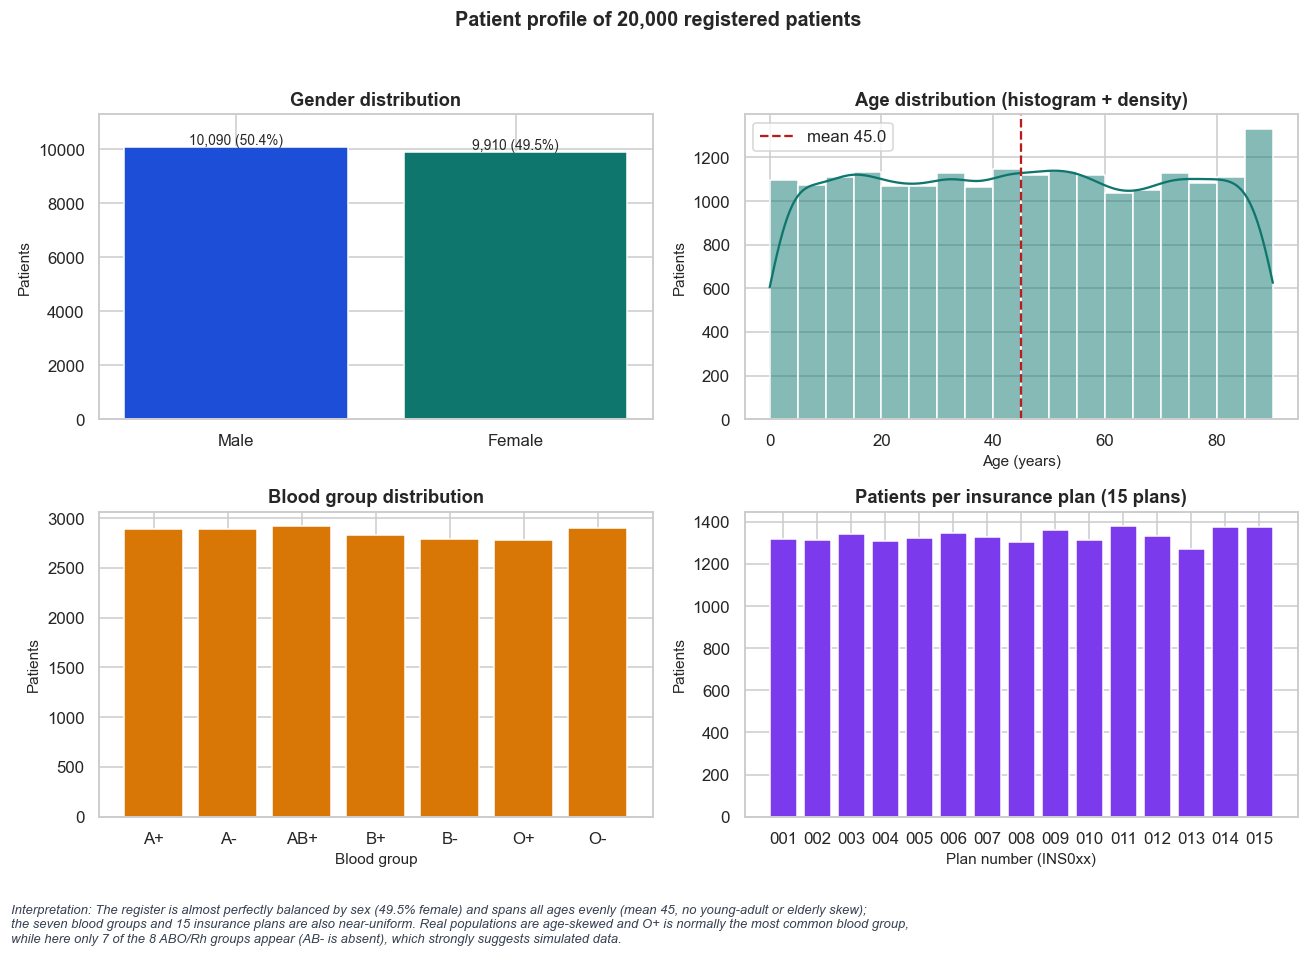

In [32]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    ph = k/n; d = 1+z*z/n; c = ph + z*z/(2*n); w = z*np.sqrt(ph*(1-ph)/n + z*z/(4*n*n))
    return ((c-w)/d, (c+w)/d)
pct = lambda x, d=1: f"{100*x:.{d}f}%"
fp = lambda v: "<0.001" if v < 0.001 else f"={v:.3f}"

n_pat = len(p); seen = df.PatientID.nunique()
R["patients"] = dict(total=n_pat, active=int((p.Status=="Active").sum()), seen=seen, seen_pct=seen/n_pat,
    male=int((p.Gender=="Male").sum()), female=int((p.Gender=="Female").sum()), age_mean=float(p.Age.mean()), age_median=float(p.Age.median()),
    chronic_pct=float(p.HasChronic.mean()), chronic_counts=p.ChronicCondition.value_counts().to_dict(),
    under18=float((p.Age<18).mean()), over65=float((p.Age>=65).mean()), high_risk_pct_seen=float(p[p.MaxSeverity.notna()].HighRisk.mean()), high_risk_n=int(p.HighRisk.sum()))
print(R["patients"])

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
gc = p.Gender.value_counts(); ax[0,0].bar(gc.index, gc.values, color=[PAL["blue"], PAL["teal"]])
for i, v in enumerate(gc.values): ax[0,0].text(i, v+100, f"{v:,} ({pct(v/n_pat)})", ha="center", fontsize=9)
ax[0,0].set(title="Gender distribution", ylabel="Patients", ylim=(0, gc.max()*1.12))
sns.histplot(p.Age, bins=18, kde=True, color=PAL["teal"], ax=ax[0,1]); ax[0,1].axvline(p.Age.mean(), color=PAL["red"], ls="--", label=f"mean {p.Age.mean():.1f}"); ax[0,1].legend()
ax[0,1].set(title="Age distribution (histogram + density)", xlabel="Age (years)", ylabel="Patients")
bg = p.BloodGroup.value_counts().sort_index(); ax[1,0].bar(bg.index, bg.values, color=PAL["amber"]); ax[1,0].set(title="Blood group distribution", xlabel="Blood group", ylabel="Patients")
ins = p.InsuranceID.value_counts().sort_index(); ax[1,1].bar(ins.index.str.replace("INS",""), ins.values, color=PAL["purple"]); ax[1,1].set(title="Patients per insurance plan (15 plans)", xlabel="Plan number (INS0xx)", ylabel="Patients")
savefig(fig, "fig01_patient_profile", "Patient profile of 20,000 registered patients",
    f"The register is almost perfectly balanced by sex ({pct(gc.get('Female',0)/n_pat)} female) and spans all ages evenly (mean {p.Age.mean():.0f}, no young-adult or elderly skew); the seven blood groups and 15 insurance plans are also near-uniform. Real populations are age-skewed and O+ is normally the most common blood group, while here only 7 of the 8 ABO/Rh groups appear (AB- is absent), which strongly suggests simulated data.")

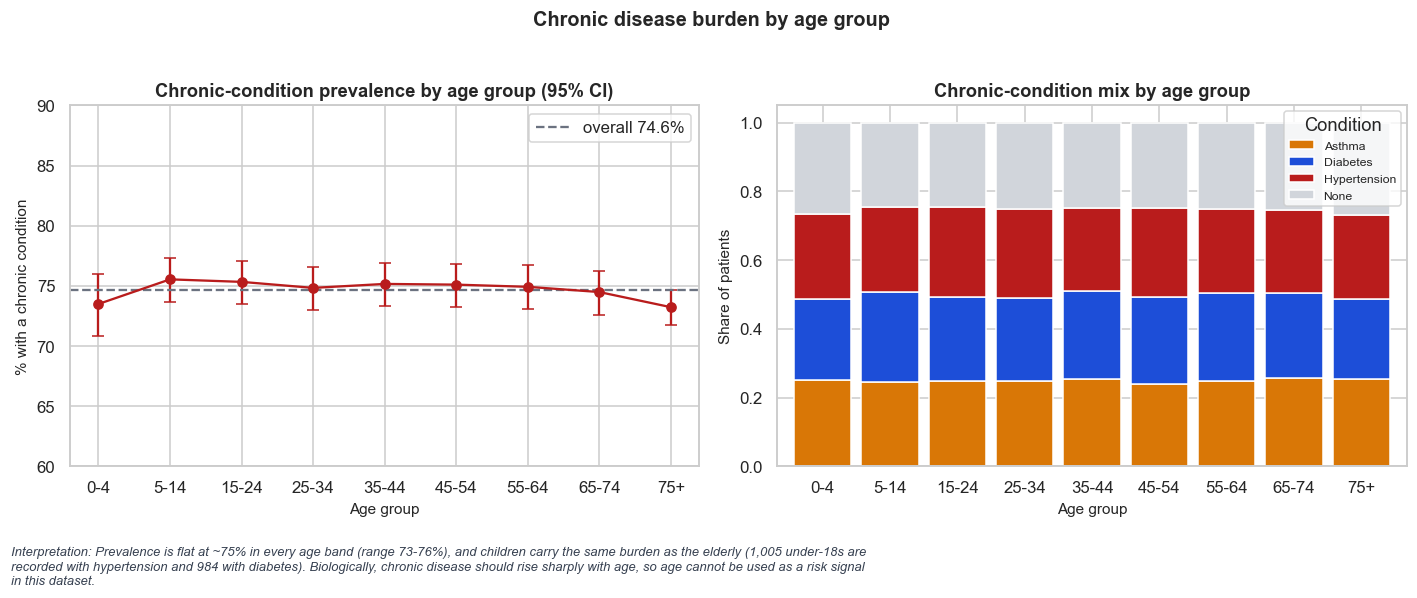

In [33]:
ag = p.groupby("AgeGroup", observed=True).HasChronic.agg(["sum","count"]); ag["rate"] = ag["sum"]/ag["count"]
ci = np.array([wilson(k, n) for k, n in zip(ag["sum"], ag["count"])])
chr_mix = pd.crosstab(p.AgeGroup, p.ChronicCondition, normalize="index")[["Asthma","Diabetes","Hypertension","None"]]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].errorbar(range(len(ag)), ag.rate*100, yerr=[(ag.rate-ci[:,0])*100, (ci[:,1]-ag.rate)*100], fmt="o-", color=PAL["red"], capsize=4)
ax[0].axhline(p.HasChronic.mean()*100, color=PAL["grey"], ls="--", label=f"overall {p.HasChronic.mean()*100:.1f}%")
ax[0].set_xticks(range(len(ag))); ax[0].set_xticklabels(ag.index); ax[0].set(title="Chronic-condition prevalence by age group (95% CI)", xlabel="Age group", ylabel="% with a chronic condition", ylim=(60, 90)); ax[0].legend()
chr_mix.plot(kind="bar", stacked=True, ax=ax[1], color=[PAL["amber"], PAL["blue"], PAL["red"], "#D1D5DB"], width=0.85)
ax[1].set(title="Chronic-condition mix by age group", xlabel="Age group", ylabel="Share of patients"); ax[1].legend(title="Condition", fontsize=8); ax[1].tick_params(axis="x", rotation=0)
R["chronic_by_age"] = {str(k): float(v) for k, v in ag.rate.items()}
kids_htn = int(((p.Age < 18) & (p.ChronicCondition == "Hypertension")).sum()); kids_dm = int(((p.Age < 18) & (p.ChronicCondition == "Diabetes")).sum())
R["child_chronic"] = dict(hypertension=kids_htn, diabetes=kids_dm)
savefig(fig, "fig02_chronic_by_age", "Chronic disease burden by age group",
    f"Prevalence is flat at ~{p.HasChronic.mean()*100:.0f}% in every age band (range {ag.rate.min()*100:.0f}-{ag.rate.max()*100:.0f}%), and children carry the same burden as the elderly ({kids_htn:,} under-18s are recorded with hypertension and {kids_dm:,} with diabetes). Biologically, chronic disease should rise sharply with age, so age cannot be used as a risk signal in this dataset.")

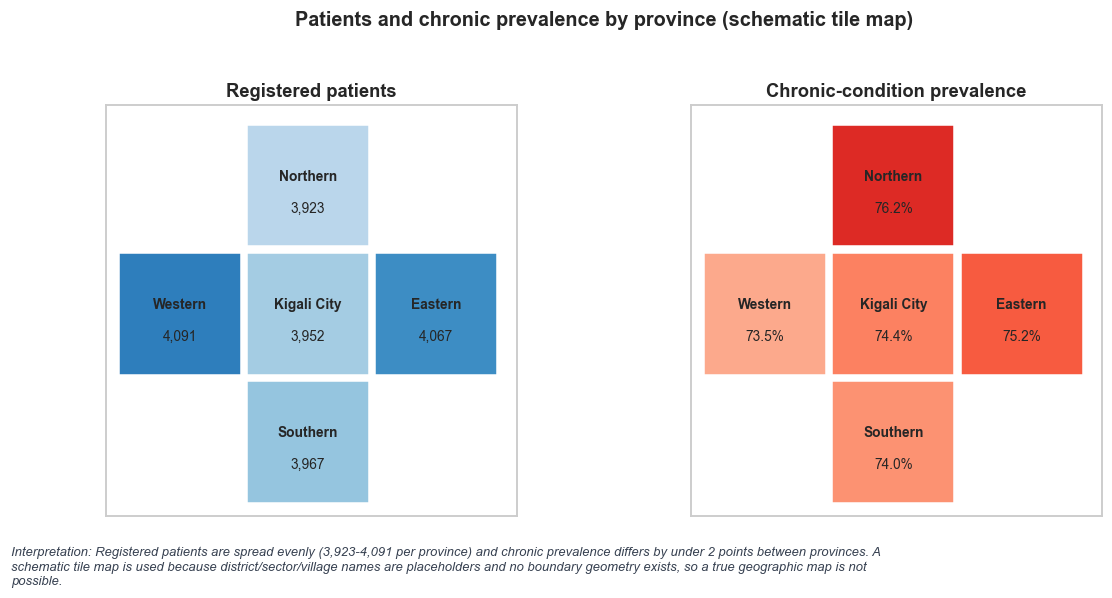

In [34]:
prov = p.groupby("ProvinceName").agg(Patients=("PatientID","size"), Chronic=("HasChronic","mean"), Age=("Age","mean")).reindex(["Northern","Western","Kigali City","Eastern","Southern"])
seen_prov = df.drop_duplicates("PatientID").groupby("ProvinceName").size()
prov["Seen"] = seen_prov
R["province"] = prov.round(4).reset_index().to_dict("records")
tile = {"Northern":(1,2), "Western":(0,1), "Kigali City":(1,1), "Eastern":(2,1), "Southern":(1,0)}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
for a_, col, ttl, cmap, fmt in [(ax[0], "Patients", "Registered patients", "Blues", "{:,.0f}"), (ax[1], "Chronic", "Chronic-condition prevalence", "Reds", "{:.1%}")]:
    vals = prov[col]; norm = plt.Normalize(vals.min()*0.97, vals.max()*1.03); cm = plt.get_cmap(cmap)
    for name, (x, y) in tile.items():
        a_.add_patch(plt.Rectangle((x, y), 0.95, 0.95, color=cm(norm(vals[name])), ec="white"))
        a_.text(x+0.475, y+0.55, name, ha="center", va="center", fontsize=9, fontweight="bold"); a_.text(x+0.475, y+0.3, fmt.format(vals[name]), ha="center", va="center", fontsize=9)
    a_.set(xlim=(-0.1, 3.1), ylim=(-0.1, 3.1), title=ttl, xticks=[], yticks=[]); a_.grid(False); a_.set_aspect("equal")
savefig(fig, "fig03_province_map", "Patients and chronic prevalence by province (schematic tile map)",
    f"Registered patients are spread evenly ({prov.Patients.min():,.0f}-{prov.Patients.max():,.0f} per province) and chronic prevalence differs by under 2 points between provinces. A schematic tile map is used because district/sector/village names are placeholders and no boundary geometry exists, so a true geographic map is not possible.")

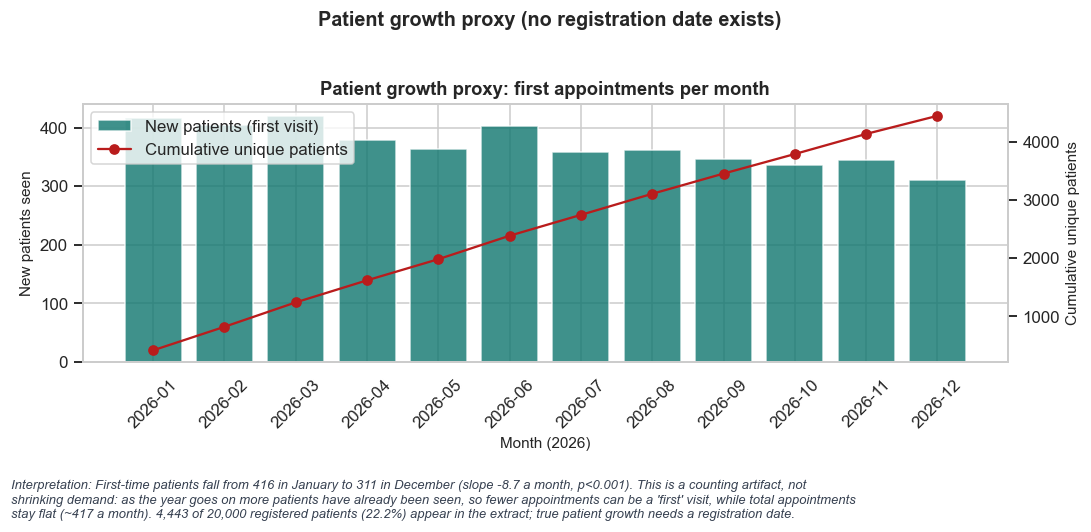

In [35]:
first = df.groupby("PatientID").Date.min().dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4.2)); ax.bar(first.index.astype(str), first.values, color=PAL["teal"], alpha=.8, label="New patients (first visit)")
ax2 = ax.twinx(); ax2.plot(first.index.astype(str), first.cumsum().values, color=PAL["red"], marker="o", label="Cumulative unique patients"); ax2.grid(False)
ax.set(title="Patient growth proxy: first appointments per month", xlabel="Month (2026)", ylabel="New patients seen"); ax2.set_ylabel("Cumulative unique patients"); ax.tick_params(axis="x", rotation=45)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1+h2, l1+l2, loc="upper left")
slope = stats.linregress(np.arange(len(first)), first.values)
R["patient_growth"] = dict(slope=float(slope.slope), p=float(slope.pvalue), monthly_mean=float(first.mean()), first_month=int(first.iloc[0]), last_month=int(first.iloc[-1]))
savefig(fig, "fig04_patient_growth", "Patient growth proxy (no registration date exists)",
    f"First-time patients fall from {first.iloc[0]} in January to {first.iloc[-1]} in December (slope {slope.slope:+.1f} a month, p{fp(slope.pvalue)}). This is a counting artifact, not shrinking demand: as the year goes on more patients have already been seen, so fewer appointments can be a 'first' visit, while total appointments stay flat (~{len(df)/12:.0f} a month). {seen:,} of 20,000 registered patients ({pct(seen/n_pat)}) appear in the extract; true patient growth needs a registration date.")

### 5.2 Clinical analysis
Only **five distinct diagnoses** exist, so "Top 20 diagnoses" reduces to five. Laboratory, prescription, admission and referral data were not supplied, so those analyses are *not computable*; visit type (Emergency / Consultation / Follow-up) is the only acuity indicator available.

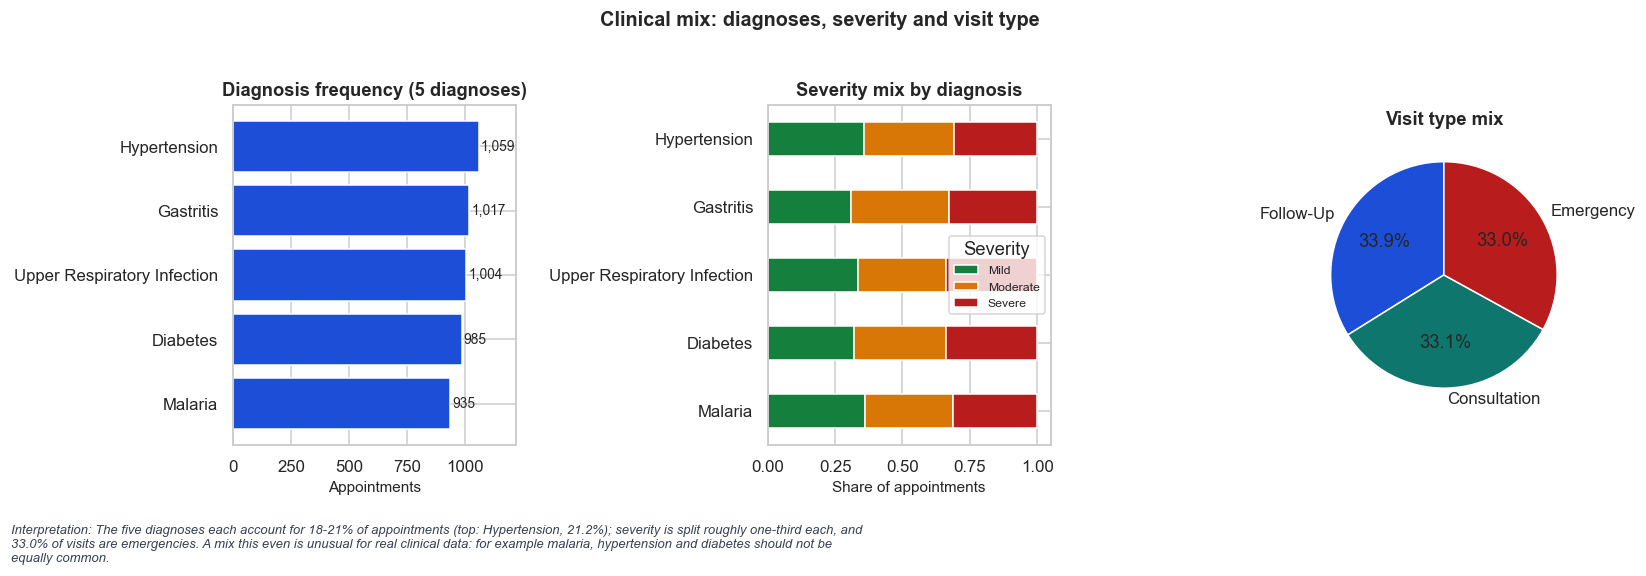

In [36]:
dxc = df.Diagnosis.value_counts(); sev = pd.crosstab(df.Diagnosis, df.Severity, normalize="index")[["Mild","Moderate","Severe"]]
vt = df.VisitType.value_counts()
R["clinical"] = dict(dx_counts=dxc.to_dict(), severity=df.Severity.value_counts().to_dict(), visit_types=vt.to_dict(), emergency_share=float((df.VisitType=="Emergency").mean()),
                     severe_share=float((df.Severity=="Severe").mean()), high_acuity_share=float(df.HighAcuityEmergency.mean()))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].barh(dxc.index[::-1], dxc.values[::-1], color=PAL["blue"]); ax[0].set(title="Diagnosis frequency (5 diagnoses)", xlabel="Appointments")
for i, v in enumerate(dxc.values[::-1]): ax[0].text(v+8, i, f"{v:,}", va="center", fontsize=9)
ax[0].set_xlim(0, dxc.max()*1.15)
sev.loc[dxc.index].plot(kind="barh", stacked=True, ax=ax[1], color=[PAL["green"], PAL["amber"], PAL["red"]]); ax[1].set(title="Severity mix by diagnosis", xlabel="Share of appointments", ylabel=""); ax[1].invert_yaxis(); ax[1].legend(title="Severity", fontsize=8)
ax[2].pie(vt.values, labels=vt.index, autopct="%1.1f%%", colors=[PAL["blue"], PAL["teal"], PAL["red"]], startangle=90, wedgeprops=dict(ec="white")); ax[2].set(title="Visit type mix")
savefig(fig, "fig05_clinical_mix", "Clinical mix: diagnoses, severity and visit type",
    f"The five diagnoses each account for 18-21% of appointments (top: {dxc.index[0]}, {pct(dxc.iloc[0]/len(df))}); severity is split roughly one-third each, and {pct((df.VisitType=='Emergency').mean())} of visits are emergencies. A mix this even is unusual for real clinical data: for example malaria, hypertension and diabetes should not be equally common.")

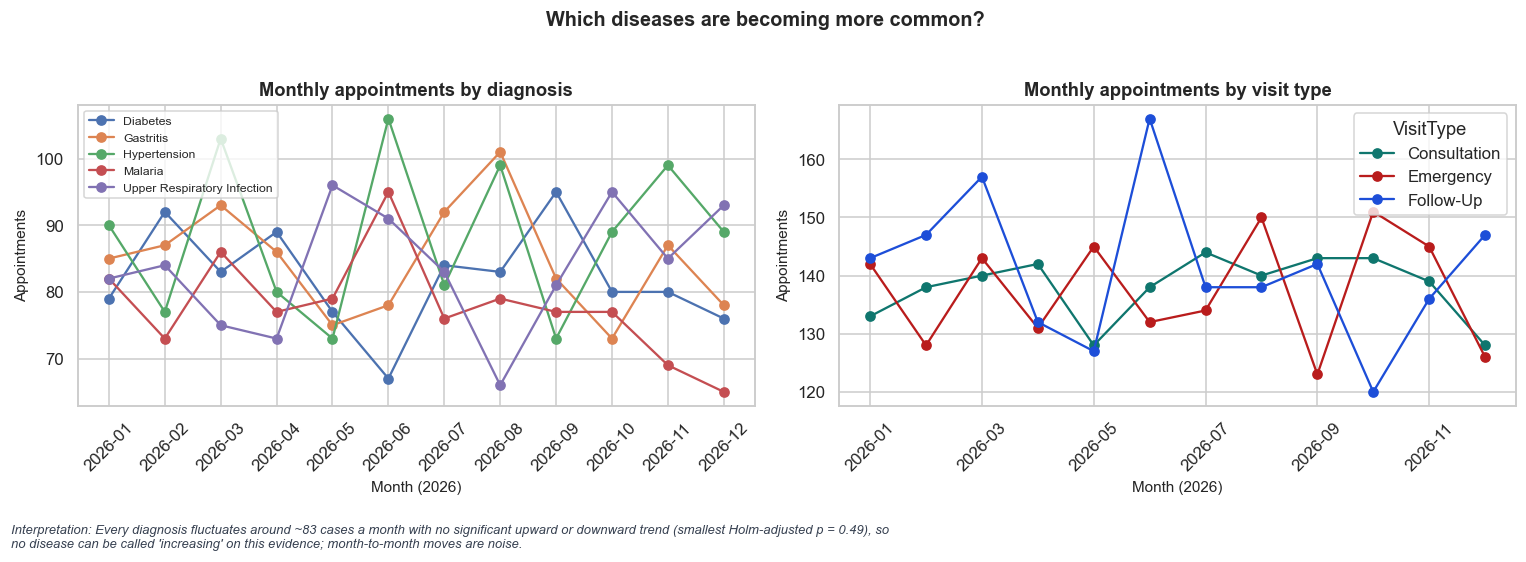

In [37]:
mdx = pd.crosstab(df.Month.astype(str), df.Diagnosis)
trend = []
for d_ in mdx.columns:
    lr = stats.linregress(np.arange(12), mdx[d_].values); trend.append(dict(Diagnosis=d_, slope_per_month=lr.slope, p=lr.pvalue))
trend = pd.DataFrame(trend); from statsmodels.stats.multitest import multipletests
trend["p_holm"] = multipletests(trend.p, method="holm")[1]
R["dx_trends"] = trend.round(4).to_dict("records")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for d_ in mdx.columns: ax[0].plot(mdx.index, mdx[d_], marker="o", label=d_)
ax[0].set(title="Monthly appointments by diagnosis", xlabel="Month (2026)", ylabel="Appointments"); ax[0].tick_params(axis="x", rotation=45); ax[0].legend(fontsize=8)
mv = pd.crosstab(df.Month.astype(str), df.VisitType)
mv.plot(ax=ax[1], marker="o", color=[PAL["teal"], PAL["red"], PAL["blue"]]); ax[1].set(title="Monthly appointments by visit type", xlabel="Month (2026)", ylabel="Appointments"); ax[1].tick_params(axis="x", rotation=45)
savefig(fig, "fig06_clinical_trends", "Which diseases are becoming more common?",
    f"Every diagnosis fluctuates around ~{mdx.values.mean():.0f} cases a month with no significant upward or downward trend (smallest Holm-adjusted p = {trend.p_holm.min():.2f}), so no disease can be called 'increasing' on this evidence; month-to-month moves are noise.")

### 5.3 Operational analysis

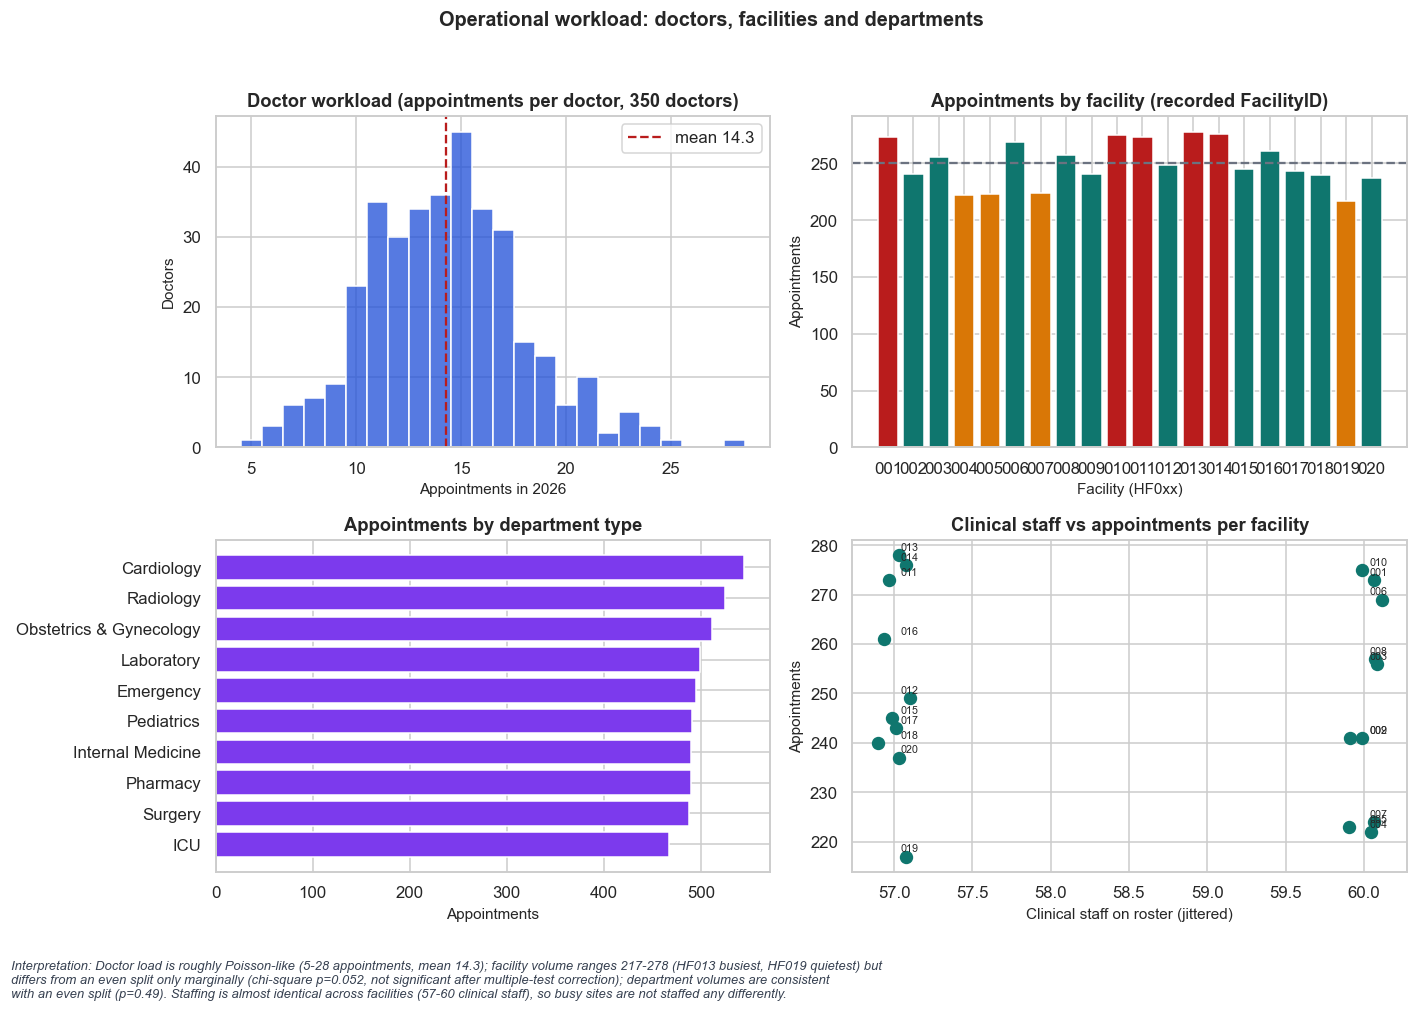

In [38]:
dw = df.groupby("DoctorID").size(); facv = df.FacilityID.value_counts().sort_index(); dtv = df.DepartmentName.value_counts()
# sensitivity: facility ranking when facility is taken from the department's owner instead of the recorded field
fac_alt = df.DepartmentID.map(dept_fac).value_counts().reindex(facv.index)
rho_fac = stats.spearmanr(facv, fac_alt)
chi_fac = stats.chisquare(facv); chi_dept = stats.chisquare(dtv)
R["operations"] = dict(doctor_appts_mean=float(dw.mean()), doctor_appts_min=int(dw.min()), doctor_appts_max=int(dw.max()), doctor_appts_sd=float(dw.std()),
    fac_min=int(facv.min()), fac_max=int(facv.max()), fac_top=facv.idxmax(), fac_bottom=facv.idxmin(), fac_chi_p=float(chi_fac.pvalue), dept_chi_p=float(chi_dept.pvalue),
    fac_rank_rho_alt=float(rho_fac.statistic), fac_rank_p_alt=float(rho_fac.pvalue),
    doctors=int(len(T['doctors'])), nurses=int(len(T['nurses'])), pharmacists=int(len(T['pharmacists'])), lab=int(len(T['lab_scientists'])), radiographers=int(len(T['radiographers'])), admin=int(len(T['admin_staff'])),
    beds=int(len(T['beds'])), rooms=int(len(T['rooms'])), equipment=int(len(T['equipment'])), patients_per_doctor=float(n_pat/len(T['doctors'])), patients_per_nurse=float(n_pat/len(T['nurses'])),
    exp_mean=float(all_staff.YearsExperience.mean()))
exp_by_role = all_staff.groupby("Role").YearsExperience.agg(["count","mean"]).round(2)
R["staff_by_role"] = exp_by_role.reset_index().to_dict("records")
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))
sns.histplot(dw, bins=range(int(dw.min()), int(dw.max())+2), color=PAL["blue"], ax=ax[0,0], discrete=True); ax[0,0].axvline(dw.mean(), color=PAL["red"], ls="--", label=f"mean {dw.mean():.1f}"); ax[0,0].legend()
ax[0,0].set(title="Doctor workload (appointments per doctor, 350 doctors)", xlabel="Appointments in 2026", ylabel="Doctors")
cols = [PAL["red"] if v > facv.mean()+facv.std() else (PAL["amber"] if v < facv.mean()-facv.std() else PAL["teal"]) for v in facv.values]
ax[0,1].bar(facv.index.str.replace("HF",""), facv.values, color=cols); ax[0,1].axhline(facv.mean(), color=PAL["grey"], ls="--"); ax[0,1].set(title="Appointments by facility (recorded FacilityID)", xlabel="Facility (HF0xx)", ylabel="Appointments")
ax[1,0].barh(dtv.index[::-1], dtv.values[::-1], color=PAL["purple"]); ax[1,0].set(title="Appointments by department type", xlabel="Appointments")
ax[1,1].scatter(fac.ClinicalStaff + rng.uniform(-.12,.12,len(fac)), fac.Appointments, s=60, color=PAL["teal"]); 
for fid, r_ in fac.iterrows(): ax[1,1].annotate(fid[2:], (r_.ClinicalStaff, r_.Appointments), fontsize=7, xytext=(4,3), textcoords="offset points")
ax[1,1].set(title="Clinical staff vs appointments per facility", xlabel="Clinical staff on roster (jittered)", ylabel="Appointments")
savefig(fig, "fig07_operations", "Operational workload: doctors, facilities and departments",
    f"Doctor load is roughly Poisson-like ({dw.min()}-{dw.max()} appointments, mean {dw.mean():.1f}); facility volume ranges {facv.min()}-{facv.max()} ({facv.idxmax()} busiest, {facv.idxmin()} quietest) but differs from an even split only marginally (chi-square p={chi_fac.pvalue:.3f}, not significant after multiple-test correction); department volumes are consistent with an even split (p={chi_dept.pvalue:.2f}). Staffing is almost identical across facilities (57-60 clinical staff), so busy sites are not staffed any differently.")

In [39]:
ops = pd.DataFrame([
 ("Doctors", len(T["doctors"]), f"{n_pat/len(T['doctors']):.0f} registered patients per doctor; {len(df)/len(T['doctors']):.1f} appointments per doctor in the extract"),
 ("Nurses", len(T["nurses"]), f"{n_pat/len(T['nurses']):.0f} registered patients per nurse; {len(df)/len(T['nurses']):.1f} appointments per nurse (appointments carry no nurse ID, so nurse workload is facility-level only)"),
 ("Pharmacists", len(T["pharmacists"]), f"{n_pat/len(T['pharmacists']):.0f} registered patients per pharmacist"),
 ("Laboratory scientists", len(T["lab_scientists"]), f"{n_pat/len(T['lab_scientists']):.0f} registered patients per scientist"),
 ("Radiographers", len(T["radiographers"]), f"{n_pat/len(T['radiographers']):.0f} registered patients per radiographer"),
 ("Administrative staff", len(T["admin_staff"]), f"average experience of all 1,250 staff: {all_staff.YearsExperience.mean():.1f} years (range 1-25)"),
 ("Rooms / Beds", f"{len(T['rooms'])} / {len(T['beds'])}", "20 rooms and 100 beds in every facility; bed occupancy NOT computable (all beds 'Available')"),
 ("Equipment items", len(T["equipment"]), "exactly 10 per facility (one per department type), regardless of volume; availability/utilisation NOT computable (no status field)"),
 ("Nurse and laboratory workload per case", "-", "NOT computable at individual level"),
], columns=["Resource","Count","Notes"])
ops

,Resource,Count,Notes
0,Doctors,350,57 registered patients per doctor; 14.3 appoin...
1,Nurses,700,29 registered patients per nurse; 7.1 appointm...
2,Pharmacists,50,400 registered patients per pharmacist
3,Laboratory scientists,40,500 registered patients per scientist
4,Radiographers,30,667 registered patients per radiographer
5,Administrative staff,80,"average experience of all 1,250 staff: 12.9 ye..."
6,Rooms / Beds,400 / 2000,20 rooms and 100 beds in every facility; bed o...
7,Equipment items,200,exactly 10 per facility (one per department ty...
8,Nurse and laboratory workload per case,-,NOT computable at individual level


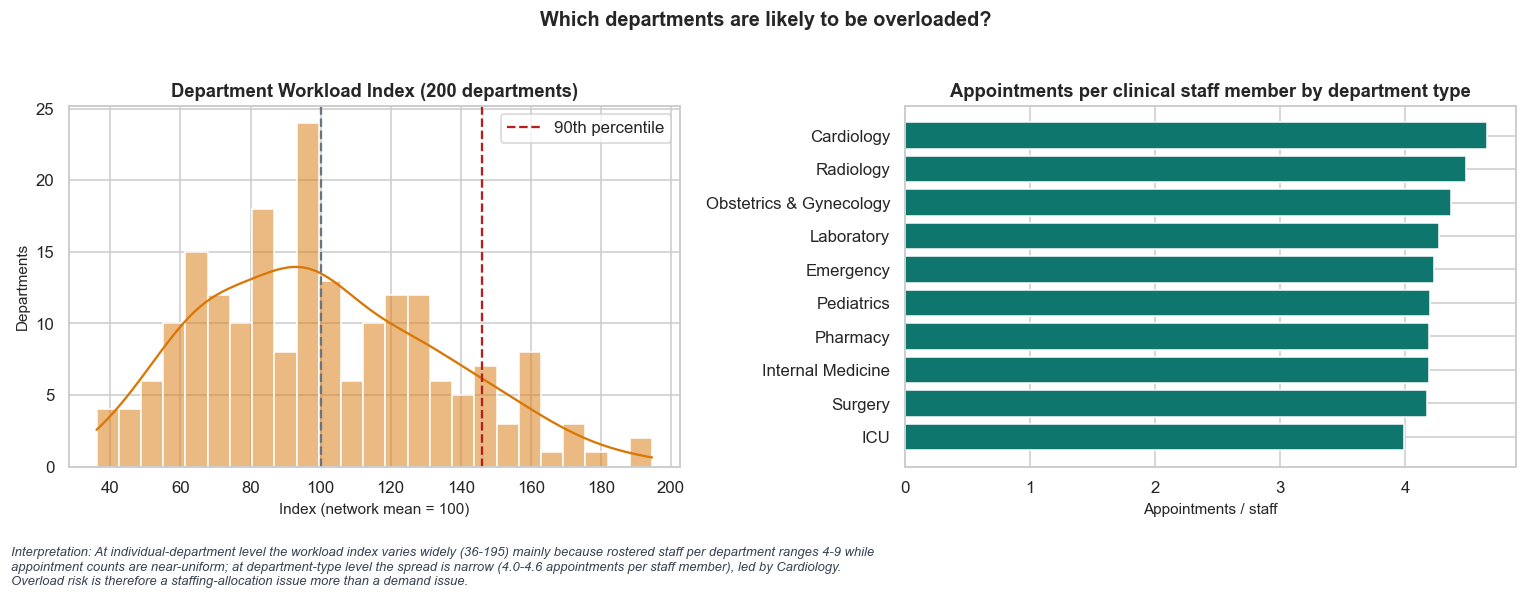

In [40]:
worst = dep.sort_values("WorkloadIndex", ascending=False).head(10)
dep["DeptType"] = dep.DepartmentName
dept_type = dep.groupby("DepartmentName").agg(Appointments=("Appointments","sum"), ClinicalStaff=("ClinicalStaff","sum"), Doctors=("Doctors","sum")).assign(ApptPerStaff=lambda d: d.Appointments/d.ClinicalStaff).sort_values("ApptPerStaff", ascending=False)
R["dept_type"] = dept_type.round(3).reset_index().to_dict("records")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(dep.WorkloadIndex.dropna(), bins=25, kde=True, color=PAL["amber"], ax=ax[0]); ax[0].axvline(100, color=PAL["grey"], ls="--"); ax[0].axvline(dep.WorkloadIndex.quantile(.9), color=PAL["red"], ls="--", label="90th percentile")
ax[0].set(title="Department Workload Index (200 departments)", xlabel="Index (network mean = 100)", ylabel="Departments"); ax[0].legend()
ax[1].barh(dept_type.index[::-1], dept_type.ApptPerStaff[::-1], color=PAL["teal"]); ax[1].set(title="Appointments per clinical staff member by department type", xlabel="Appointments / staff")
savefig(fig, "fig08_workload_index", "Which departments are likely to be overloaded?",
    f"At individual-department level the workload index varies widely ({dep.WorkloadIndex.min():.0f}-{dep.WorkloadIndex.max():.0f}) mainly because rostered staff per department ranges 4-9 while appointment counts are near-uniform; at department-type level the spread is narrow ({dept_type.ApptPerStaff.min():.1f}-{dept_type.ApptPerStaff.max():.1f} appointments per staff member), led by {dept_type.index[0]}. Overload risk is therefore a staffing-allocation issue more than a demand issue.")

### 5.4 Financial analysis

{'bills': 60000, 'billed': 9309401961.0, 'collected': 8389454556.0, 'outstanding': 919947405.0, 'collection_rate': 0.90118082677556, 'mean_bill': 155156.69935, 'median_bill': 155247.0, 'claim_share': 0.7006, 'claim_approved': 21008, 'claim_pending': 21028, 'claim_total_amt': 4881863293.879999, 'pending_claim_amt': 2438605768.02, 'approved_claim_amt': 2443257525.86, 'fully_paid_share': 0.8018833333333333, 'ks_uniform_p': 0.9205151707403395}


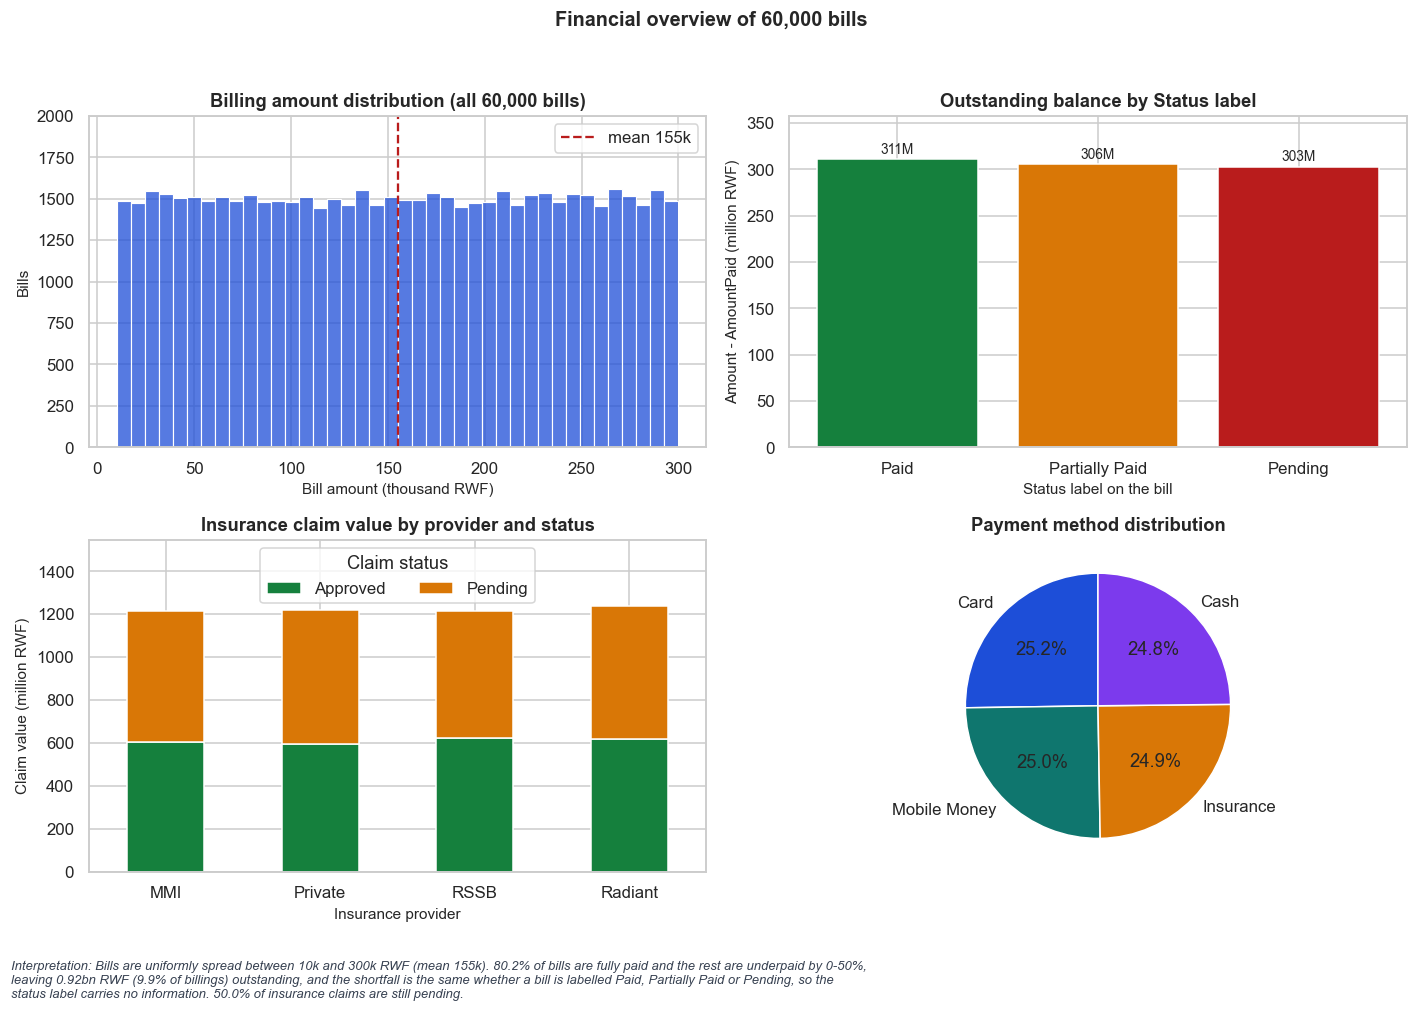

In [41]:
fin_all = dict(bills=len(bl), billed=float(bl.Amount.sum()), collected=float(bl.AmountPaid.sum()), outstanding=float(bl.Outstanding.sum()), collection_rate=float(bl.AmountPaid.sum()/bl.Amount.sum()),
    mean_bill=float(bl.Amount.mean()), median_bill=float(bl.Amount.median()), claim_share=float(bl.HasClaim.mean()),
    claim_approved=int((bl.ClaimStatus=="Approved").sum()), claim_pending=int((bl.ClaimStatus=="Pending").sum()), claim_total_amt=float(bl.ClaimAmount.sum()),
    pending_claim_amt=float(bl.loc[bl.ClaimStatus=="Pending","ClaimAmount"].sum()), approved_claim_amt=float(bl.loc[bl.ClaimStatus=="Approved","ClaimAmount"].sum()),
    by_status=bl.groupby("Status").agg(n=("BillingID","size"), billed=("Amount","sum"), outstanding=("Outstanding","sum"), paid_ratio=("PaidRatio","mean")).round(3).reset_index().to_dict("records"),
    method=bl.Method.value_counts(normalize=True).round(4).to_dict(), providers=bl.groupby("Provider").agg(claims=("ClaimID","count"), amount=("ClaimAmount","sum"), approved=("ClaimStatus", lambda s: (s=="Approved").sum())).reset_index().to_dict("records"),
    fully_paid_share=float((bl.Outstanding==0).mean()), ks_uniform_p=float(stats.kstest((bl.Amount-bl.Amount.min())/(bl.Amount.max()-bl.Amount.min()), "uniform").pvalue))
R["finance"] = fin_all
print({k: v for k, v in fin_all.items() if not isinstance(v, (list, dict))})

fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))
sns.histplot(bl.Amount/1000, bins=40, color=PAL["blue"], ax=ax[0,0]); ax[0,0].axvline(bl.Amount.mean()/1000, color=PAL["red"], ls="--", label=f"mean {bl.Amount.mean()/1000:.0f}k"); ax[0,0].legend()
ax[0,0].set(title="Billing amount distribution (all 60,000 bills)", xlabel="Bill amount (thousand RWF)", ylabel="Bills", ylim=(0, 2000))
stt = bl.groupby("Status").Outstanding.sum()/1e6; ax[0,1].bar(stt.index, stt.values, color=[PAL["green"], PAL["amber"], PAL["red"]]); 
for i, v in enumerate(stt.values): ax[0,1].text(i, v*1.02, f"{v:,.0f}M", ha="center", fontsize=9)
ax[0,1].set(title="Outstanding balance by Status label", xlabel="Status label on the bill", ylabel="Amount - AmountPaid (million RWF)", ylim=(0, stt.max()*1.15))
prv = bl[bl.HasClaim].groupby(["Provider","ClaimStatus"]).ClaimAmount.sum().unstack()/1e6; prv.plot(kind="bar", stacked=True, ax=ax[1,0], color=[PAL["green"], PAL["amber"]]); ax[1,0].tick_params(axis="x", rotation=0)
ax[1,0].set(title="Insurance claim value by provider and status", xlabel="Insurance provider", ylabel="Claim value (million RWF)", ylim=(0, prv.sum(axis=1).max()*1.25)); ax[1,0].legend(title="Claim status", ncol=2, loc="upper center")
pm = bl.Method.value_counts(); ax[1,1].pie(pm.values, labels=pm.index, autopct="%1.1f%%", colors=[PAL["blue"], PAL["teal"], PAL["amber"], PAL["purple"]], startangle=90, wedgeprops=dict(ec="white")); ax[1,1].set(title="Payment method distribution")
savefig(fig, "fig09_finance", "Financial overview of 60,000 bills",
    f"Bills are uniformly spread between 10k and 300k RWF (mean {bl.Amount.mean()/1000:.0f}k). {pct(fin_all['fully_paid_share'])} of bills are fully paid and the rest are underpaid by 0-50%, leaving {fin_all['outstanding']/1e9:.2f}bn RWF ({pct(1-fin_all['collection_rate'])} of billings) outstanding, and the shortfall is the same whether a bill is labelled Paid, Partially Paid or Pending, so the status label carries no information. {pct(fin_all['claim_pending']/max(fin_all['claim_pending']+fin_all['claim_approved'],1))} of insurance claims are still pending.")

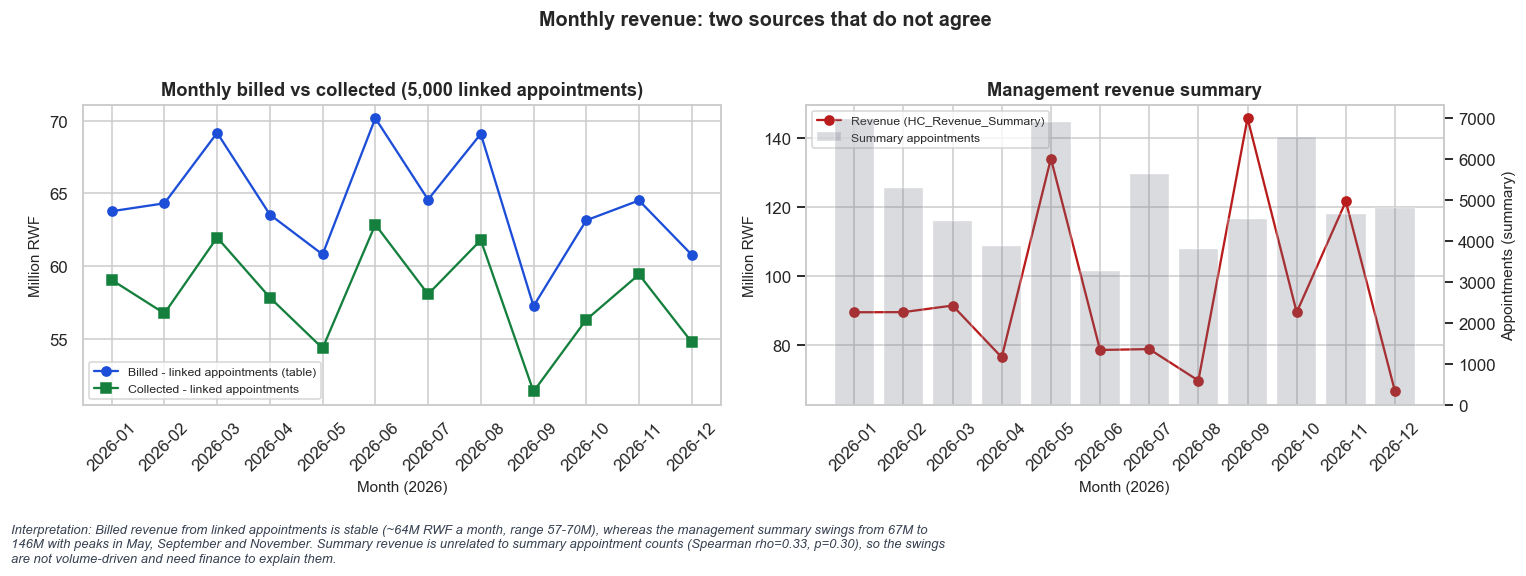

In [42]:
mon = df.groupby(df.Month.astype(str)).agg(Appointments=("AppointmentID","size"), Billed=("BillAmount","sum"), Collected=("AmountPaid","sum"), MeanRating=("Rating","mean"), RatingN=("Rating","count"))
rs = T["revenue_summary"].set_index("Month")
mon = mon.join(rs.rename(columns={"Revenue":"SummaryRevenue","Appointments":"SummaryAppointments"}))
mon["MonthlyGrowth"] = mon.Billed.pct_change()
R["monthly"] = mon.reset_index().round(3).to_dict("records")
r_rev_appt = stats.spearmanr(mon.SummaryRevenue, mon.SummaryAppointments); r_bill_appt = stats.spearmanr(mon.Billed, mon.Appointments)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].plot(mon.index, mon.Billed/1e6, marker="o", color=PAL["blue"], label="Billed - linked appointments (table)"); ax[0].plot(mon.index, mon.Collected/1e6, marker="s", color=PAL["green"], label="Collected - linked appointments")
ax[0].set(title="Monthly billed vs collected (5,000 linked appointments)", xlabel="Month (2026)", ylabel="Million RWF"); ax[0].tick_params(axis="x", rotation=45); ax[0].legend(fontsize=8)
ax[1].plot(mon.index, mon.SummaryRevenue/1e6, marker="o", color=PAL["red"], label="Revenue (HC_Revenue_Summary)"); ax[1].set(title="Management revenue summary", xlabel="Month (2026)", ylabel="Million RWF"); ax[1].tick_params(axis="x", rotation=45)
ax3 = ax[1].twinx(); ax3.bar(mon.index, mon.SummaryAppointments, alpha=.25, color=PAL["grey"], label="Summary appointments"); ax3.grid(False); ax3.set_ylabel("Appointments (summary)")
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels(); ax[1].legend(h1+h2, l1+l2, fontsize=8, loc="upper left")
savefig(fig, "fig10_revenue_trend", "Monthly revenue: two sources that do not agree",
    f"Billed revenue from linked appointments is stable (~{mon.Billed.mean()/1e6:.0f}M RWF a month, range {mon.Billed.min()/1e6:.0f}-{mon.Billed.max()/1e6:.0f}M), whereas the management summary swings from {mon.SummaryRevenue.min()/1e6:.0f}M to {mon.SummaryRevenue.max()/1e6:.0f}M with peaks in May, September and November. Summary revenue is unrelated to summary appointment counts (Spearman rho={r_rev_appt.statistic:.2f}, p={r_rev_appt.pvalue:.2f}), so the swings are not volume-driven and need finance to explain them.")

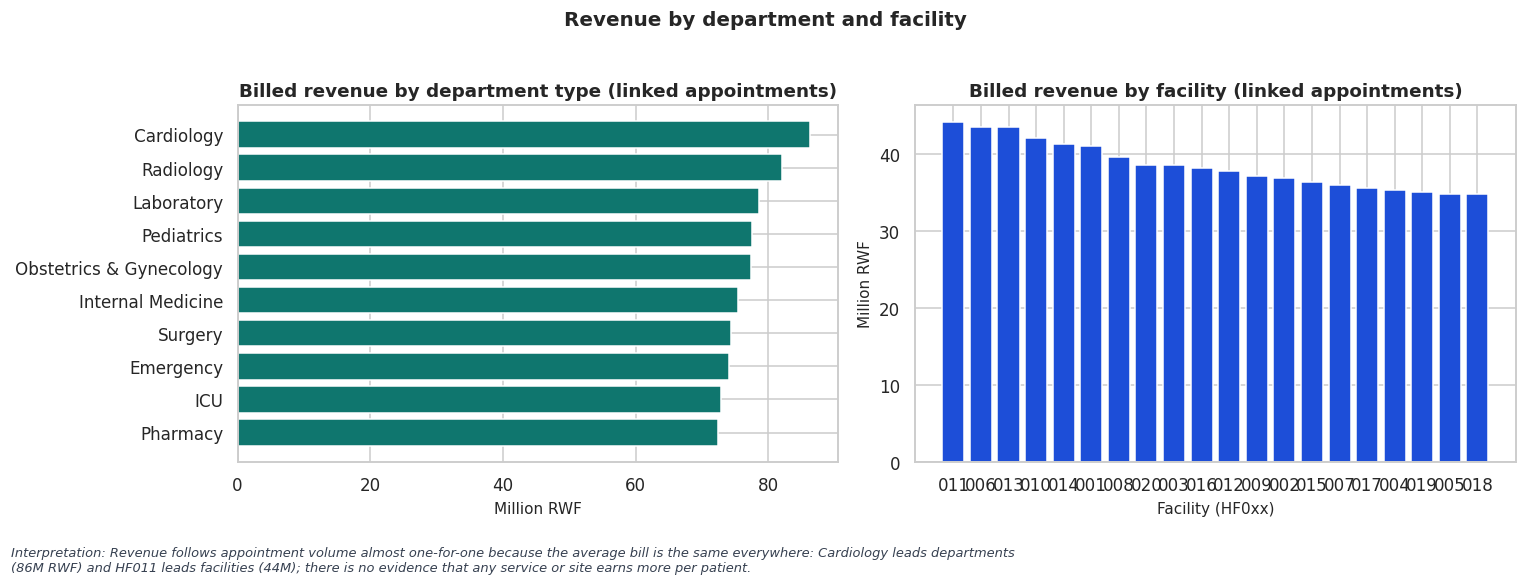

In [23]:
rv_dept = df.groupby("DepartmentName").agg(Billed=("BillAmount","sum"), Mean=("BillAmount","mean"), n=("BillAmount","size")).sort_values("Billed", ascending=False)
rv_fac = df.groupby("FacilityID").BillAmount.sum().sort_values(ascending=False)
R["revenue_dept"] = rv_dept.round(0).reset_index().to_dict("records"); R["revenue_fac"] = (rv_fac).round(0).to_dict()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].barh(rv_dept.index[::-1], rv_dept.Billed[::-1]/1e6, color=PAL["teal"]); ax[0].set(title="Billed revenue by department type (linked appointments)", xlabel="Million RWF")
ax[1].bar(rv_fac.index.str.replace("HF",""), rv_fac.values/1e6, color=PAL["blue"]); ax[1].set(title="Billed revenue by facility (linked appointments)", xlabel="Facility (HF0xx)", ylabel="Million RWF")
savefig(fig, "fig11_revenue_split", "Revenue by department and facility",
    f"Revenue follows appointment volume almost one-for-one because the average bill is the same everywhere: {rv_dept.index[0]} leads departments ({rv_dept.Billed.iloc[0]/1e6:.0f}M RWF) and {rv_fac.index[0]} leads facilities ({rv_fac.iloc[0]/1e6:.0f}M); there is no evidence that any service or site earns more per patient.")

### 5.5 Patient experience

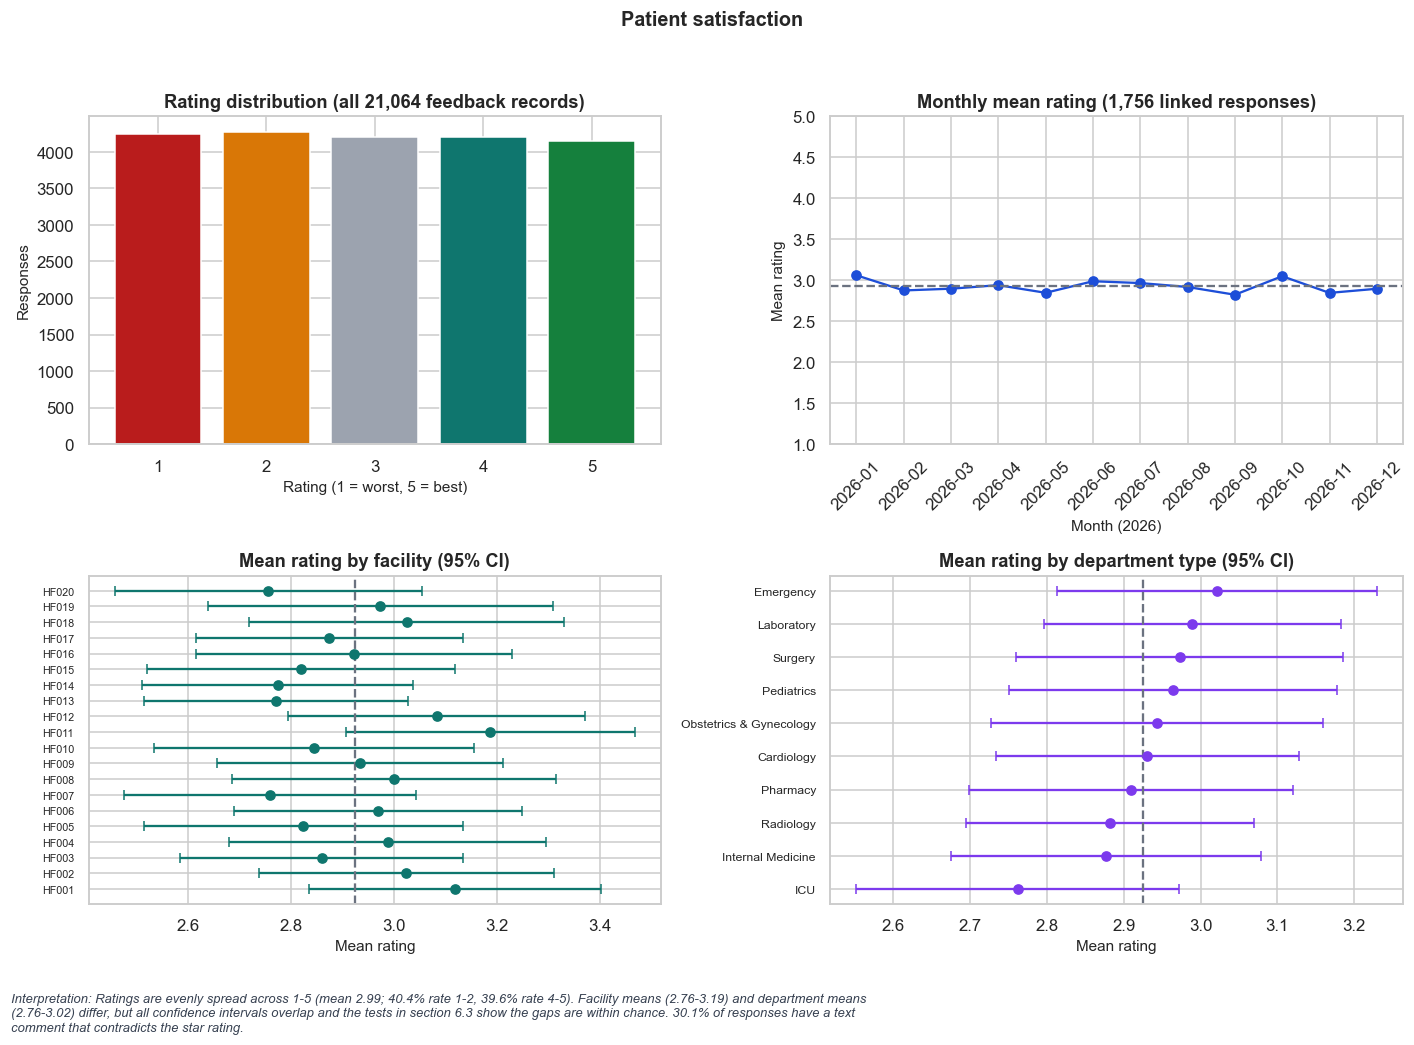

In [43]:
fa = T["feedback"]; rt_all = fa.Rating.value_counts().sort_index()
lk = df.dropna(subset=["Rating"])
fac_r = lk.groupby("FacilityID").Rating.agg(["mean","std","count"]); fac_r["ci"] = 1.96*fac_r["std"]/np.sqrt(fac_r["count"])
dep_r = lk.groupby("DepartmentName").Rating.agg(["mean","std","count"]); dep_r["ci"] = 1.96*dep_r["std"]/np.sqrt(dep_r["count"]); dep_r = dep_r.sort_values("mean")
R["experience"] = dict(all_n=len(fa), all_mean=float(fa.Rating.mean()), all_low_share=float((fa.Rating<=2).mean()), all_high_share=float((fa.Rating>=4).mean()), linked_n=len(lk), linked_mean=float(lk.Rating.mean()),
    rating_dist=rt_all.to_dict(), comment_dist=fa.Comment.value_counts().to_dict(), contradiction_share=float(contra.mean()), rho_rating_comment=float(rho_fb.statistic),
    best_fac=fac_r["mean"].idxmax(), worst_fac=fac_r["mean"].idxmin(), best_fac_val=float(fac_r["mean"].max()), worst_fac_val=float(fac_r["mean"].min()),
    best_dept=dep_r["mean"].idxmax(), worst_dept=dep_r["mean"].idxmin(), best_dept_val=float(dep_r["mean"].max()), worst_dept_val=float(dep_r["mean"].min()))
fig, ax = plt.subplots(2, 2, figsize=(13, 8.8))
ax[0,0].bar(rt_all.index.astype(str), rt_all.values, color=[PAL["red"], PAL["amber"], "#9CA3AF", PAL["teal"], PAL["green"]]); ax[0,0].set(title="Rating distribution (all 21,064 feedback records)", xlabel="Rating (1 = worst, 5 = best)", ylabel="Responses")
mm = lk.groupby(lk.Month.astype(str)).Rating.agg(["mean","count"]); ax[0,1].plot(mm.index, mm["mean"], marker="o", color=PAL["blue"]); ax[0,1].axhline(lk.Rating.mean(), color=PAL["grey"], ls="--")
ax[0,1].set(title="Monthly mean rating (1,756 linked responses)", xlabel="Month (2026)", ylabel="Mean rating", ylim=(1, 5)); ax[0,1].tick_params(axis="x", rotation=45)
ax[1,0].errorbar(fac_r["mean"], range(len(fac_r)), xerr=fac_r["ci"], fmt="o", color=PAL["teal"], capsize=3); ax[1,0].set_yticks(range(len(fac_r))); ax[1,0].set_yticklabels(fac_r.index, fontsize=7)
ax[1,0].axvline(lk.Rating.mean(), color=PAL["grey"], ls="--"); ax[1,0].set(title="Mean rating by facility (95% CI)", xlabel="Mean rating")
ax[1,1].errorbar(dep_r["mean"], range(len(dep_r)), xerr=dep_r["ci"], fmt="o", color=PAL["purple"], capsize=3); ax[1,1].set_yticks(range(len(dep_r))); ax[1,1].set_yticklabels(dep_r.index, fontsize=8)
ax[1,1].axvline(lk.Rating.mean(), color=PAL["grey"], ls="--"); ax[1,1].set(title="Mean rating by department type (95% CI)", xlabel="Mean rating")
savefig(fig, "fig12_satisfaction", "Patient satisfaction",
    f"Ratings are evenly spread across 1-5 (mean {fa.Rating.mean():.2f}; {pct((fa.Rating<=2).mean())} rate 1-2, {pct((fa.Rating>=4).mean())} rate 4-5). Facility means ({fac_r['mean'].min():.2f}-{fac_r['mean'].max():.2f}) and department means ({dep_r['mean'].min():.2f}-{dep_r['mean'].max():.2f}) differ, but all confidence intervals overlap and the tests in section 6.3 show the gaps are within chance. {pct(contra.mean())} of responses have a text comment that contradicts the star rating.")

## 6. Statistical analysis
### 6.1 Descriptive statistics
Computed on the largest valid base for each variable (e.g. all 20,000 patients for Age, all 60,000 bills for amounts).

In [44]:
def describe(s, name):
    s = pd.Series(s).dropna().astype(float)
    mode = s.round(0).mode().iloc[0] if len(s) else np.nan
    q = s.quantile([.05,.10,.25,.5,.75,.90,.95])
    return dict(Variable=name, n=len(s), Mean=s.mean(), Median=s.median(), Mode=mode, StdDev=s.std(), Variance=s.var(), Min=s.min(), P5=q[.05], P10=q[.10], Q1=q[.25], Q3=q[.75], P90=q[.90], P95=q[.95], Max=s.max(), IQR=q[.75]-q[.25], Skew=stats.skew(s), Kurtosis=stats.kurtosis(s))
desc = pd.DataFrame([
  describe(p.Age, "Patient age (years)"), describe(p.BMI_clean, "BMI (adults 18+)"), describe(bl.Amount, "Bill amount (RWF)"), describe(bl.AmountPaid, "Amount paid (RWF)"),
  describe(bl.Outstanding, "Outstanding per bill (RWF)"), describe(bl.ClaimAmount, "Insurance claim amount (RWF)"), describe(T["feedback"].Rating, "Satisfaction rating (1-5)"),
  describe(all_staff.YearsExperience, "Staff years of experience"), describe(df.groupby("DoctorID").size(), "Appointments per doctor"), describe(df.PriorVisits, "Prior visits (per appointment)"), describe(df.SeverityScore, "Severity score (1-3)")])
R["descriptive"] = desc.round(3).to_dict("records")
desc.round(2)

,Variable,n,Mean,Median,Mode,StdDev,Variance,Min,P5,P10,Q1,Q3,P90,P95,Max,IQR,Skew,Kurtosis
0,Patient age (years),20000,45.03,45.00,90.0,26.26,6.896400e+02,0.00,4.00,9.00,22.00,68.00,82.0,86.00,90.00,46.00,0.01,-1.19
1,BMI (adults 18+),16030,30.04,29.20,32.0,10.42,1.086300e+02,11.10,15.00,17.10,21.70,37.00,44.5,49.10,61.20,15.30,0.45,-0.40
2,Bill amount (RWF),60000,155156.70,155247.00,36833.0,83840.37,7.029207e+09,10002.00,24717.85,38803.80,82275.25,227907.75,271134.2,285651.70,299998.00,145632.50,-0.00,-1.21
3,Amount paid (RWF),60000,139824.24,129821.50,129528.0,83370.19,6.950589e+09,5002.00,20555.95,32340.60,68694.25,210240.00,264198.6,282129.45,299998.00,141545.75,0.26,-1.11
4,Outstanding per bill (RWF),60000,15332.46,0.00,0.0,36038.07,1.298743e+09,0.00,0.00,0.00,0.00,0.00,76387.4,113261.25,149991.00,0.00,2.33,4.19
5,Insurance claim amount (RWF),42036,116135.30,111421.64,42625.0,67812.49,4.598533e+09,5172.54,17900.12,28055.92,59153.72,165174.94,211879.4,236446.78,298532.88,106021.22,0.33,-0.76
6,Satisfaction rating (1-5),21064,2.99,3.00,2.0,1.41,2.000000e+00,1.00,1.00,1.00,2.00,4.00,5.0,5.00,5.00,2.00,0.01,-1.30
7,Staff years of experience,1250,12.93,13.00,3.0,7.17,5.145000e+01,1.00,2.00,3.00,6.00,19.00,23.0,24.00,25.00,13.00,0.02,-1.20
8,Appointments per doctor,350,14.29,14.00,15.0,3.68,1.356000e+01,5.00,9.00,10.00,12.00,16.00,19.0,21.00,28.00,4.00,0.37,0.41
9,Prior visits (per appointment),5000,0.12,0.00,0.0,0.36,1.300000e-01,0.00,0.00,0.00,0.00,0.00,1.0,1.00,3.00,0.00,3.07,9.95


**Reading the table:** age, bill amount and rating have skewness ≈ 0 and kurtosis ≈ -1.2, the signature of a **uniform** distribution, not the bell-shaped or right-skewed shapes real ages and charges follow. Because of this, rank-based (non-parametric) tests are used as the primary tests below.

### 6.2 Correlation analysis
The six relationships required by the brief. Where the required variable does not exist (length of stay) the closest available substitute is used and labelled.

In [45]:
def sp(x, y):
    m = pd.concat([pd.Series(x).reset_index(drop=True), pd.Series(y).reset_index(drop=True)], axis=1).dropna()
    r_ = stats.spearmanr(m.iloc[:,0], m.iloc[:,1]); return len(m), float(r_.statistic), float(r_.pvalue)
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum(); return float(np.sqrt(chi2/(n*(min(ct.shape)-1))))
corr_rows = []
n_, r_, p_ = sp(df.Age, df.HighAcuityEmergency); corr_rows.append(("Age vs admission proxy (high-acuity emergency)", "Spearman", n_, r_, p_))
n_, r_, p_ = sp(df.Age, df.BillAmount);          corr_rows.append(("Age vs billing amount", "Spearman", n_, r_, p_))
ct_ds = pd.crosstab(df.Diagnosis, df.Severity); corr_rows.append(("Diagnosis vs severity (substitute for 'diagnosis vs length of stay')", "Cramer's V", len(df), cramers_v(ct_ds), float(stats.chi2_contingency(ct_ds)[1])))
kw = stats.kruskal(*[g.BillAmount.values for _, g in df.groupby("Diagnosis")]); corr_rows.append(("Diagnosis vs billing amount", "Kruskal-Wallis (H)", len(df), float(kw.statistic), float(kw.pvalue)))
dtm = df.groupby("DepartmentName").agg(w=("DeptWorkloadIndex","mean"), r=("Rating","mean"), a=("AppointmentID","size")); n_, r_, p_ = sp(dtm.w, dtm.r); corr_rows.append(("Department workload index vs mean satisfaction (10 department types)", "Spearman", n_, r_, p_))
n_, r_, p_ = sp(fac.ApptPerClinicalStaff, fac.MeanRating); corr_rows.append(("Facility appointments per clinical staff vs mean satisfaction (20 facilities)", "Spearman", n_, r_, p_))
n_, r_, p_ = sp(mon.SummaryRevenue, mon.SummaryAppointments); corr_rows.append(("Revenue vs patient volume - management summary (12 months)", "Spearman", n_, r_, p_))
n_, r_, p_ = sp(mon.Billed, mon.Appointments); corr_rows.append(("Billed revenue vs appointments - linked data (12 months)", "Spearman", n_, r_, p_))
n_, r_, p_ = sp(fac.Billed, fac.Appointments); corr_rows.append(("Billed revenue vs appointments by facility (20 facilities)", "Spearman", n_, r_, p_))
vis_pp = p.PatientID.map(df.groupby("PatientID").size()).fillna(0)
kw2 = stats.kruskal(*[vis_pp[p.InsuranceID == k].values for k in sorted(p.InsuranceID.unique())]); corr_rows.append(("Insurance plan (15) vs visits per patient (utilisation)", "Kruskal-Wallis (H)", len(p), float(kw2.statistic), float(kw2.pvalue)))
cs = df.dropna(subset=["Rating"]); kw3 = stats.kruskal(*[g.Rating.values for _, g in cs.groupby("InsuranceCoverageCat")]); corr_rows.append(("Coverage category (approved/pending/self-pay) vs satisfaction", "Kruskal-Wallis (H)", len(cs), float(kw3.statistic), float(kw3.pvalue)))
corr_tbl = pd.DataFrame(corr_rows, columns=["Relationship","Method","n","Statistic","p_value"]); corr_tbl["Significant (p<0.05)"] = corr_tbl.p_value < 0.05
R["correlations"] = corr_tbl.round(4).to_dict("records")
corr_tbl.round(4)

,Relationship,Method,n,Statistic,p_value,Significant (p<0.05)
0,Age vs admission proxy (high-acuity emergency),Spearman,5000,-0.0169,0.2320,False
1,Age vs billing amount,Spearman,5000,-0.0028,0.8424,False
2,Diagnosis vs severity (substitute for 'diagnos...,Cramer's V,5000,0.0328,0.2139,False
3,Diagnosis vs billing amount,Kruskal-Wallis (H),5000,3.0184,0.5548,False
4,Department workload index vs mean satisfaction...,Spearman,10,0.3818,0.2763,False
5,Facility appointments per clinical staff vs me...,Spearman,20,0.0278,0.9073,False
6,Revenue vs patient volume - management summary...,Spearman,12,0.3287,0.2969,False
7,Billed revenue vs appointments - linked data (...,Spearman,12,0.8741,0.0002,True
8,Billed revenue vs appointments by facility (20...,Spearman,20,0.8608,0.0000,True
9,Insurance plan (15) vs visits per patient (uti...,Kruskal-Wallis (H),20000,10.9311,0.6914,False


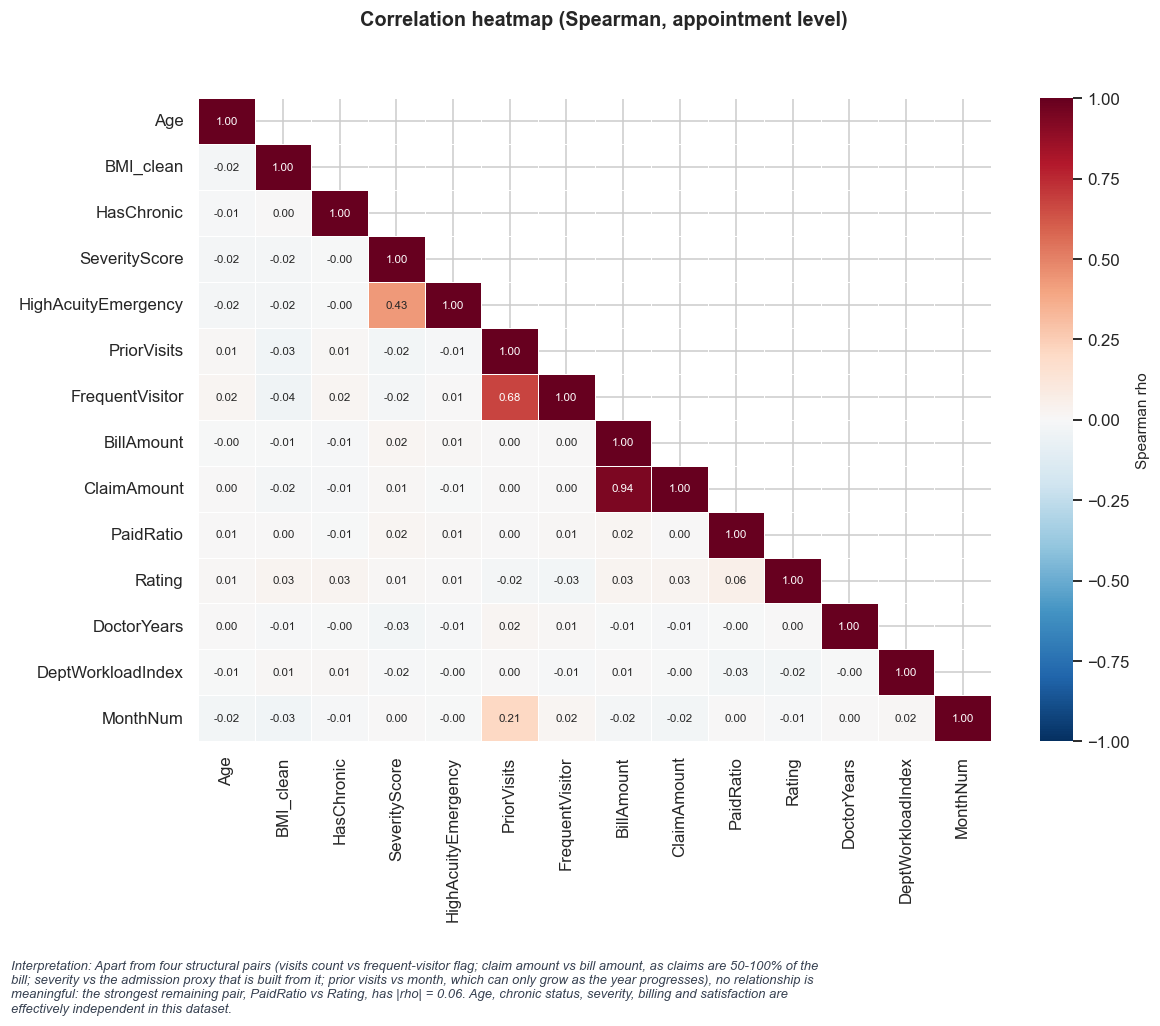

In [46]:
hm_cols = ["Age","BMI_clean","HasChronic","SeverityScore","HighAcuityEmergency","PriorVisits","FrequentVisitor","BillAmount","ClaimAmount","PaidRatio","Rating","DoctorYears","DeptWorkloadIndex","MonthNum"]
cm = df[hm_cols].corr(method="spearman")
mask = np.triu(np.ones_like(cm, dtype=bool), k=1)
off = cm.where(~np.eye(len(cm), dtype=bool)).abs().stack()
structural = {frozenset(x) for x in [("PriorVisits","FrequentVisitor"), ("BillAmount","ClaimAmount"), ("SeverityScore","HighAcuityEmergency"), ("PriorVisits","MonthNum")]}
non_struct = off[[frozenset(i) not in structural for i in off.index]]
top_pair = non_struct.idxmax(); top_val = float(cm.loc[top_pair])
R["heatmap"] = dict(max_nonstructural_pair=list(top_pair), max_nonstructural_rho=top_val, n_vars=len(hm_cols))
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(cm, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=.5, cbar_kws=dict(label="Spearman rho"), ax=ax, annot_kws=dict(size=7.5))
ax.set(title="", xlabel="", ylabel="")
savefig(fig, "fig13_correlation_heatmap", "Correlation heatmap (Spearman, appointment level)",
    f"Apart from four structural pairs (visits count vs frequent-visitor flag; claim amount vs bill amount, as claims are 50-100% of the bill; severity vs the admission proxy that is built from it; prior visits vs month, which can only grow as the year progresses), no relationship is meaningful: the strongest remaining pair, {top_pair[0]} vs {top_pair[1]}, has |rho| = {abs(top_val):.2f}. Age, chronic status, severity, billing and satisfaction are effectively independent in this dataset.")

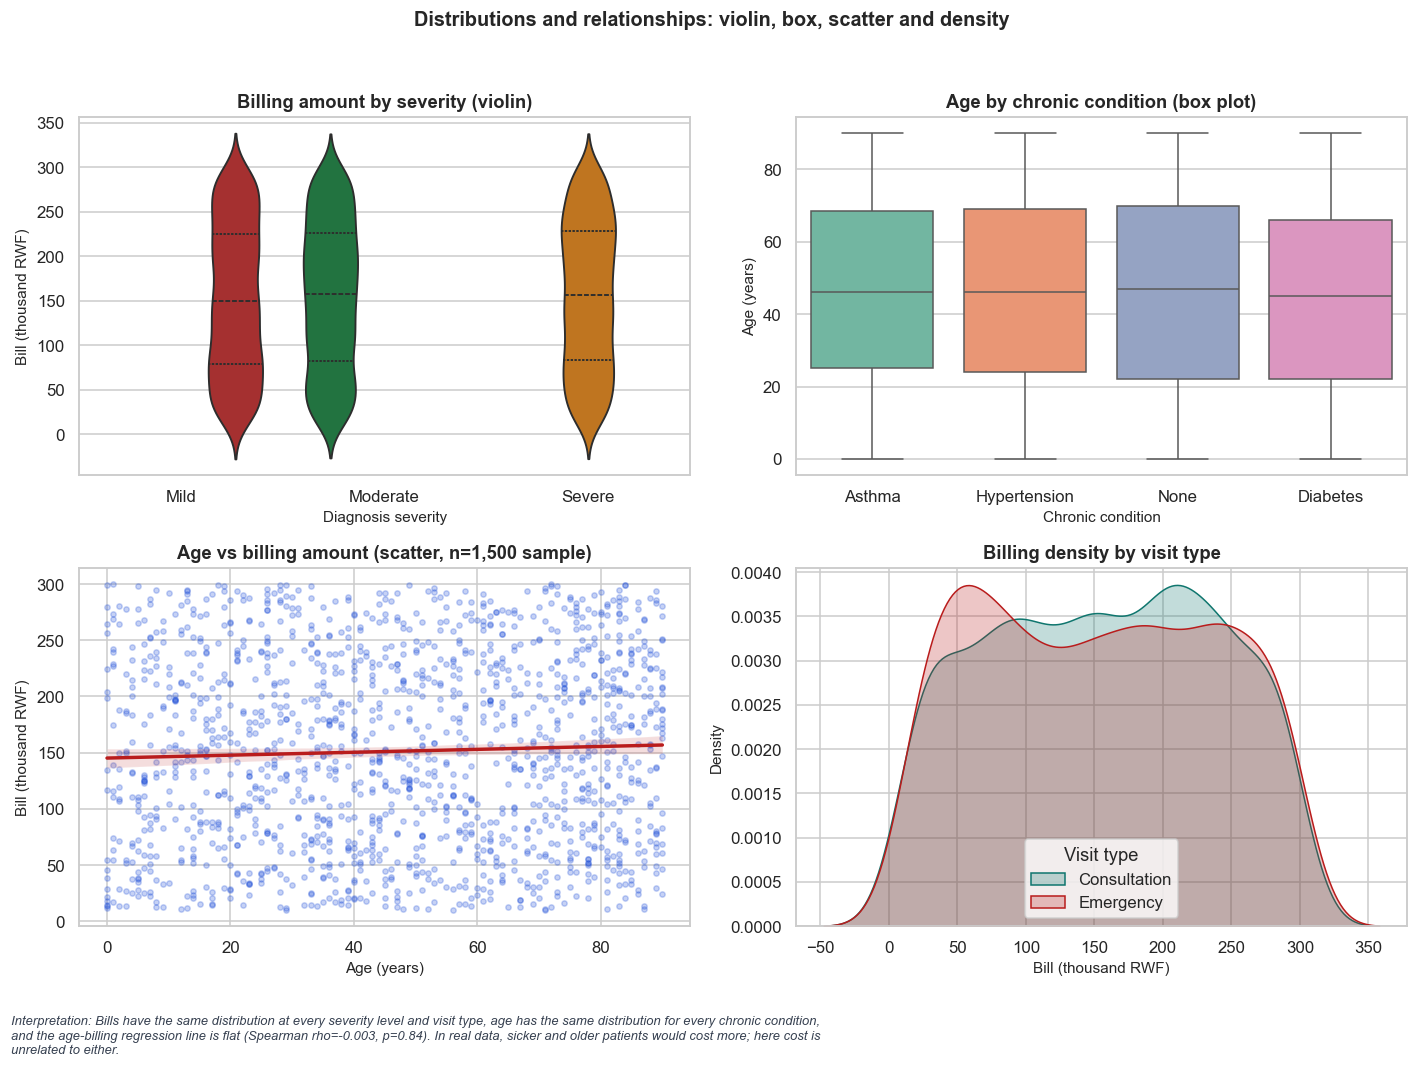

In [47]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.violinplot(data=df, x="Severity", y=df.BillAmount/1000, hue="Severity", palette=[PAL["green"], PAL["amber"], PAL["red"]], inner="quartile", legend=False, ax=ax[0,0]); ax[0,0].set(title="Billing amount by severity (violin)", xlabel="Diagnosis severity", ylabel="Bill (thousand RWF)")
sns.boxplot(data=df, x="ChronicCondition", y="Age", hue="ChronicCondition", palette="Set2", legend=False, ax=ax[0,1]); ax[0,1].set(title="Age by chronic condition (box plot)", xlabel="Chronic condition", ylabel="Age (years)")
sns.regplot(data=df.sample(1500, random_state=SEED), x="Age", y=df.sample(1500, random_state=SEED).BillAmount/1000, scatter_kws=dict(alpha=.25, s=12, color=PAL["blue"]), line_kws=dict(color=PAL["red"]), ax=ax[1,0]); ax[1,0].set(title="Age vs billing amount (scatter, n=1,500 sample)", xlabel="Age (years)", ylabel="Bill (thousand RWF)")
for k_, c_ in zip(["Consultation","Emergency","Follow-up"], [PAL["teal"], PAL["red"], PAL["blue"]]): sns.kdeplot(df.loc[df.VisitType==k_, "BillAmount"]/1000, fill=True, alpha=.25, color=c_, label=k_, ax=ax[1,1])
ax[1,1].set(title="Billing density by visit type", xlabel="Bill (thousand RWF)", ylabel="Density"); ax[1,1].legend(title="Visit type")
savefig(fig, "fig14_distributions", "Distributions and relationships: violin, box, scatter and density",
    f"Bills have the same distribution at every severity level and visit type, age has the same distribution for every chronic condition, and the age-billing regression line is flat (Spearman rho={corr_rows[1][3]:.3f}, p={corr_rows[1][4]:.2f}). In real data, sicker and older patients would cost more; here cost is unrelated to either.")

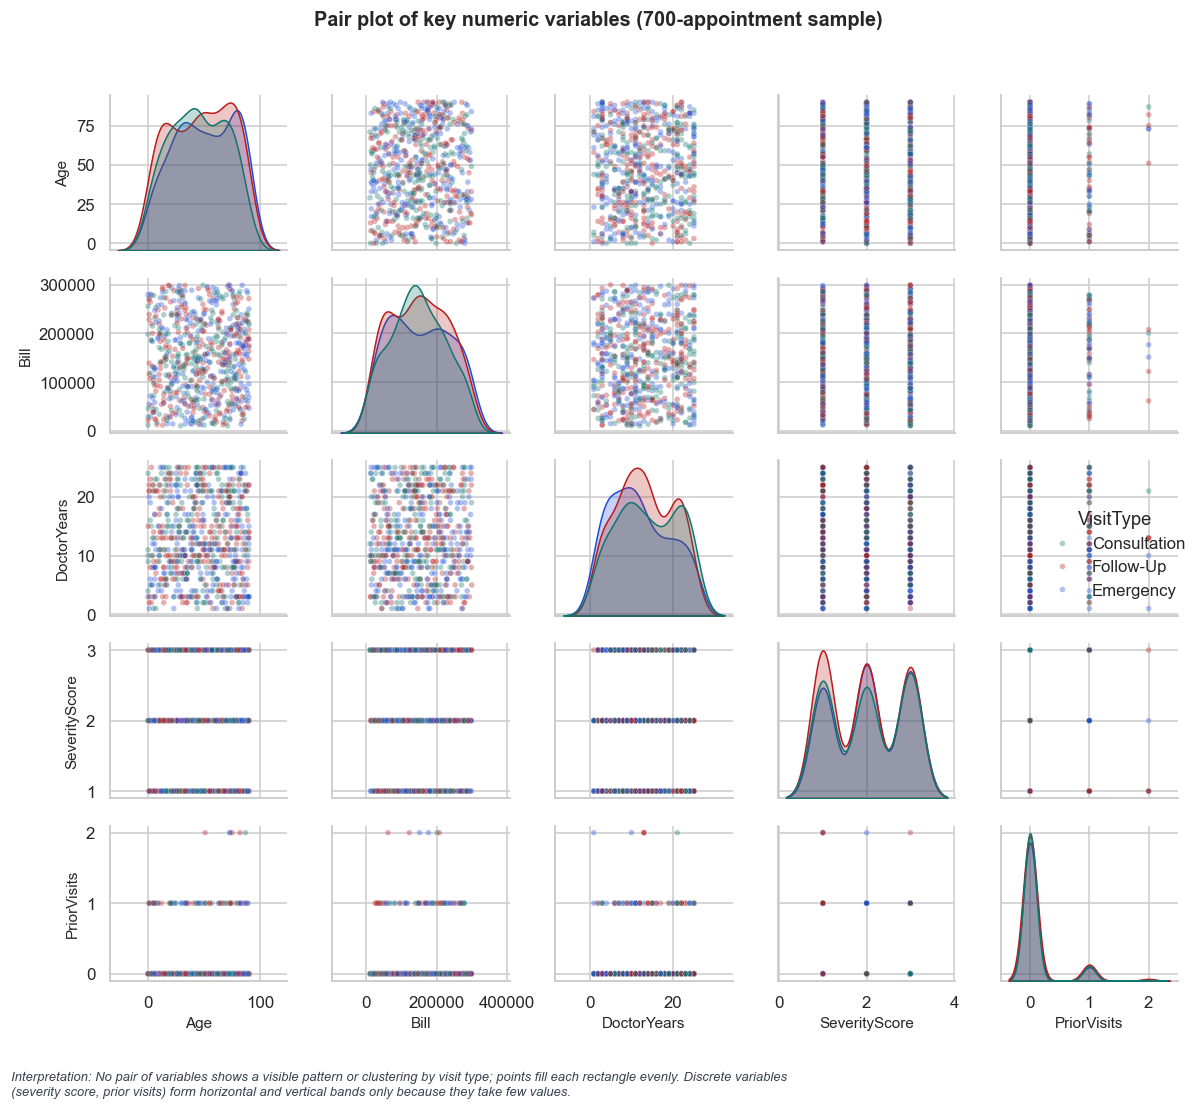

In [48]:
pp_cols = ["Age","BillAmount","DoctorYears","SeverityScore","PriorVisits"]
ppdat = df[pp_cols + ["VisitType"]].sample(700, random_state=SEED).rename(columns={"BillAmount":"Bill"}); 
g = sns.pairplot(ppdat, hue="VisitType", palette=[PAL["teal"], PAL["red"], PAL["blue"]], plot_kws=dict(alpha=.35, s=14), diag_kind="kde", height=1.9)
savefig(g.figure, "fig15_pair_plot", "Pair plot of key numeric variables (700-appointment sample)",
    "No pair of variables shows a visible pattern or clustering by visit type; points fill each rectangle evenly. Discrete variables (severity score, prior visits) form horizontal and vertical bands only because they take few values.")

### 6.3 Hypothesis testing
Significance level **α = 0.05**. Because 11 tests are run together, a **Holm** correction is applied; a result is called significant only if its Holm-adjusted p is below 0.05. Effect sizes are reported because with large n even trivial differences can reach p<0.05.
The brief's example "insured vs uninsured" is adapted: every patient holds an InsuranceID, so *insured* = bill has an insurance claim, *uninsured/self-pay* = bill has none (60,000 bills).

In [49]:
from statsmodels.stats.multitest import multipletests
tests = []
def add(name, H0, H1, test, stat, p_, effect, n):
    tests.append(dict(Test=name, H0=H0, H1=H1, Method=test, Statistic=float(stat), p_value=float(p_), Effect=effect, n=int(n)))

# H1 billing: claim vs no claim (all 60k bills)
a1, b1 = bl.loc[bl.HasClaim, "Amount"], bl.loc[~bl.HasClaim, "Amount"]
mw = stats.mannwhitneyu(a1, b1); wt = stats.ttest_ind(a1, b1, equal_var=False)
auc = mw.statistic/(len(a1)*len(b1)); diff = a1.mean()-b1.mean(); se = np.sqrt(a1.var()/len(a1)+b1.var()/len(b1))
add("1. Billing: insurance-backed vs self-pay bills", "Bill amounts have the same distribution for insured and self-pay bills", "Distributions differ", "Mann-Whitney U (Welch t as check)", mw.statistic, mw.pvalue,
    f"mean diff {diff:,.0f} RWF (95% CI {diff-1.96*se:,.0f} to {diff+1.96*se:,.0f}); AUC={auc:.3f}; Welch p={wt.pvalue:.3f}", len(bl))
# H2 satisfaction across facilities
groups = [g_.Rating.values for _, g_ in lk.groupby("FacilityID")]; kwf = stats.kruskal(*groups); anf = stats.f_oneway(*groups)
add("2. Satisfaction differs across the 20 facilities", "Median rating is equal in all facilities", "At least one facility differs", "Kruskal-Wallis (ANOVA as check)", kwf.statistic, kwf.pvalue,
    f"epsilon^2={max(0, (kwf.statistic-19)/(len(lk)-20)):.4f}; ANOVA p={anf.pvalue:.3f}", len(lk))
# H3 high-acuity emergency (admission proxy) across age groups
ag4 = pd.cut(df.Age, [-1,17,39,59,200], labels=["<18","18-39","40-59","60+"]); ct = pd.crosstab(ag4, df.HighAcuityEmergency); c3 = stats.chi2_contingency(ct)
add("3. Admission proxy rate differs between age groups", "Proportion of high-acuity emergency visits is equal across age groups", "Proportions differ", "Chi-square test of independence", c3[0], c3[1], f"Cramer's V={cramers_v(ct):.3f}; rates " + ", ".join(f"{i}: {100*v:.1f}%" for i, v in (ct[1]/ct.sum(axis=1)).items()), len(df))
# H4 satisfaction across departments
groups = [g_.Rating.values for _, g_ in lk.groupby("DepartmentName")]; kwd = stats.kruskal(*groups)
add("4. Satisfaction differs across department types", "Median rating is equal in all 10 department types", "At least one department differs", "Kruskal-Wallis", kwd.statistic, kwd.pvalue, f"epsilon^2={max(0, (kwd.statistic-9)/(len(lk)-10)):.4f}", len(lk))
# H5 chronic prevalence by age group
ct5 = pd.crosstab(p.AgeGroup, p.HasChronic); c5 = stats.chi2_contingency(ct5)
add("5. Chronic-condition prevalence differs by age group", "Prevalence is the same in all 9 age groups", "Prevalence differs", "Chi-square test of independence", c5[0], c5[1], f"Cramer's V={cramers_v(ct5):.3f}", len(p))
# H6 chronic by gender
ct6 = pd.crosstab(p.Gender, p.HasChronic); c6 = stats.chi2_contingency(ct6)
add("6. Chronic-condition prevalence differs by sex", "Prevalence is equal for males and females", "Prevalence differs", "Chi-square test of independence", c6[0], c6[1], f"male {100*ct6.loc['Male',1]/ct6.loc['Male'].sum():.1f}% vs female {100*ct6.loc['Female',1]/ct6.loc['Female'].sum():.1f}%", len(p))
# H7 chronic by province
ct7 = pd.crosstab(p.ProvinceName, p.HasChronic); c7 = stats.chi2_contingency(ct7)
add("7. Chronic-condition prevalence differs by province", "Prevalence is equal in all 5 provinces", "Prevalence differs", "Chi-square test of independence", c7[0], c7[1], f"Cramer's V={cramers_v(ct7):.3f}", len(p))
# H8 billing by severity
kws = stats.kruskal(*[g_.BillAmount.values for _, g_ in df.groupby("Severity", observed=True)])
add("8. Billing differs by diagnosis severity", "Bill distribution is the same for Mild, Moderate and Severe", "At least one differs", "Kruskal-Wallis", kws.statistic, kws.pvalue, f"epsilon^2={max(0, (kws.statistic-2)/(len(df)-3)):.4f}", len(df))
# H9 paid ratio by billing status label
kwp = stats.kruskal(*[g_.PaidRatio.values for _, g_ in bl.groupby("Status")])
add("9. Payment completeness differs by Billing.Status label", "Share of the bill paid is the same for Paid / Partially Paid / Pending bills", "Status labels differ in share paid", "Kruskal-Wallis", kwp.statistic, kwp.pvalue, f"mean paid share: " + ", ".join(f"{k}: {100*v:.1f}%" for k, v in bl.groupby('Status').PaidRatio.mean().items()), len(bl))
# H10/H11 volume uniformity
add("10. Appointment volume is uneven across facilities", "Appointments are spread equally over the 20 facilities", "Volume differs by facility", "Chi-square goodness of fit", chi_fac.statistic, chi_fac.pvalue, f"range {facv.min()}-{facv.max()} (expected {len(df)/20:.0f})", len(df))
add("11. Appointment volume is uneven across department types", "Appointments are spread equally over the 10 department types", "Volume differs by department", "Chi-square goodness of fit", chi_dept.statistic, chi_dept.pvalue, f"range {dtv.min()}-{dtv.max()} (expected {len(df)/10:.0f})", len(df))
ht = pd.DataFrame(tests); ht["p_holm"] = multipletests(ht.p_value, method="holm")[1]
ht["Conclusion (alpha=0.05, Holm)"] = np.where(ht.p_holm < 0.05, "Reject H0", "Fail to reject H0")
R["hypothesis_tests"] = ht.round(5).to_dict("records")
pd.set_option("display.max_colwidth", 90); ht[["Test","Method","n","Statistic","p_value","p_holm","Conclusion (alpha=0.05, Holm)","Effect"]].round(4)

,Test,Method,n,Statistic,p_value,p_holm,"Conclusion (alpha=0.05, Holm)",Effect
0,1. Billing: insurance-backed vs self-pay bills,Mann-Whitney U (Welch t as check),60000,3.748030e+08,0.1548,1.0000,Fail to reject H0,"mean diff -1,065 RWF (95% CI -2,531 to 401); AUC=0.496; Welch p=0.154"
1,2. Satisfaction differs across the 20 facilities,Kruskal-Wallis (ANOVA as check),1756,1.379990e+01,0.7952,1.0000,Fail to reject H0,epsilon^2=0.0000; ANOVA p=0.785
2,3. Admission proxy rate differs between age groups,Chi-square test of independence,5000,6.163200e+00,0.1039,0.9354,Fail to reject H0,"Cramer's V=0.035; rates <18: 10.5%, 18-39: 12.8%, 40-59: 10.8%, 60+: 9.9%"
3,4. Satisfaction differs across department types,Kruskal-Wallis,1756,4.467300e+00,0.8781,1.0000,Fail to reject H0,epsilon^2=0.0000
4,5. Chronic-condition prevalence differs by age group,Chi-square test of independence,20000,6.692700e+00,0.5701,1.0000,Fail to reject H0,Cramer's V=0.018
5,6. Chronic-condition prevalence differs by sex,Chi-square test of independence,20000,2.018000e-01,0.6532,1.0000,Fail to reject H0,male 74.8% vs female 74.5%
6,7. Chronic-condition prevalence differs by province,Chi-square test of independence,20000,9.709400e+00,0.0456,0.5018,Fail to reject H0,Cramer's V=0.022
7,8. Billing differs by diagnosis severity,Kruskal-Wallis,5000,1.860900e+00,0.3944,1.0000,Fail to reject H0,epsilon^2=0.0000
8,9. Payment completeness differs by Billing.Status label,Kruskal-Wallis,60000,8.846000e-01,0.6426,1.0000,Fail to reject H0,"mean paid share: Paid: 90.0%, Partially Paid: 90.1%, Pending: 90.2%"
9,10. Appointment volume is uneven across facilities,Chi-square goodness of fit,5000,2.997600e+01,0.0521,0.5210,Fail to reject H0,range 217-278 (expected 250)


**Interpretation.** Test 9 is the important one for finance: the share of the bill actually paid is statistically the same for bills labelled *Paid*, *Partially Paid* and *Pending*, so the status field cannot be used to chase debts; outstanding amounts must be computed from payments. Across the clinical, demographic and experience questions, the results show no statistically reliable differences: age does not change admission-proxy rates or billing, facilities and departments do not differ in satisfaction, and being insured (claim filed) does not change the bill.

## 7. Predictive analytics
### 7.1 Time-series forecasting 
**Constraint:** each series has only **12 monthly observations (Jan-Dec 2026)**. That is not enough to estimate seasonality (needs ≥2 full cycles) and barely enough to estimate a trend, so the method is chosen empirically: four simple models (historical mean, naive last value, linear trend, simple exponential smoothing) are compared by **rolling-origin back-testing** (train on the first 6-11 months, forecast the next 1-3, average the absolute errors) and the lowest-error model forecasts Jan-Dec 2027 (with a parsimony rule: the plain historical mean is kept unless another model is at least 2% more accurate). Prediction intervals are approximate 95% intervals.

In [50]:
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
MODELS = ["Mean","Naive (last value)","Linear trend","Exp. smoothing (SES)"]
def fc_models(y, h):
    y = np.asarray(y, float); n = len(y); t = np.arange(n); hh = np.arange(1, h+1); out = {}
    s = y.std(ddof=1); out[MODELS[0]] = (np.repeat(y.mean(), h), np.repeat(s*np.sqrt(1+1/n), h))
    out[MODELS[1]] = (np.repeat(y[-1], h), np.std(np.diff(y), ddof=1)*np.sqrt(hh))
    ols = sm.OLS(y, sm.add_constant(t)).fit(); pr = ols.get_prediction(sm.add_constant(np.arange(n, n+h), has_constant="add")).summary_frame(alpha=.05)
    out[MODELS[2]] = (pr["mean"].values, (pr["obs_ci_upper"].values-pr["mean"].values)/1.96)
    ses = SimpleExpSmoothing(y, initialization_method="estimated").fit(); a_ = ses.params["smoothing_level"]
    out[MODELS[3]] = (np.asarray(ses.forecast(h)), np.std(ses.resid, ddof=1)*np.sqrt(1+(hh-1)*a_**2))
    return out
def backtest(y, h=3, start=6):
    y = np.asarray(y, float); ae = {m: [] for m in MODELS}; pe = {m: [] for m in MODELS}
    for o in range(start, len(y)-h+1):
        f = fc_models(y[:o], h)
        for m, (pred, _) in f.items(): ae[m] += list(np.abs(y[o:o+h]-pred)); pe[m] += list(np.abs(y[o:o+h]-pred)/np.abs(y[o:o+h]))
    return pd.Series({m: np.mean(v) for m, v in ae.items()}), pd.Series({m: np.mean(v) for m, v in pe.items()})
fut_idx = pd.period_range("2027-01", periods=12, freq="M").astype(str)

def run_forecast(y, label):
    y = np.asarray(y, float); mae, mape = backtest(y); best = mae.idxmin()
    if mae[best] > 0.98*mae["Mean"]: best = "Mean"      # parsimony: keep the simplest model unless another is >2% better
    pred, se = fc_models(y, 12)[best]; lo, hi = pred-1.96*se, pred+1.96*se
    lr = stats.linregress(np.arange(len(y)), y)
    res = dict(label=label, best=best, mae=mae.round(2).to_dict(), mape=mape.round(4).to_dict(), mae_vs_mean=float(mae[best]/mae["Mean"]), trend_slope=float(lr.slope), trend_p=float(lr.pvalue),
               cv=float(y.std(ddof=1)/y.mean()), history_mean=float(y.mean()), forecast_total=float(np.sum(pred)), forecast_mean=float(np.mean(pred)),
               forecast_lo_total=float(np.sum(np.maximum(lo, 0))), forecast_hi_total=float(np.sum(hi)), pred=[float(v) for v in pred], lo=[float(v) for v in lo], hi=[float(v) for v in hi])
    return res
months = list(mon.index)
series = {"Monthly appointments (Appointments table)": mon.Appointments.values, "Monthly appointments (management summary)": mon.SummaryAppointments.values,
          "Monthly revenue (management summary, RWF)": mon.SummaryRevenue.values, "Monthly billed revenue (linked bills, RWF)": mon.Billed.values}
FC = {k: run_forecast(v, k) for k, v in series.items()}
bt_tbl = pd.DataFrame({k: v["mae"] for k, v in FC.items()}).T; bt_tbl["Best"] = [v["best"] for v in FC.values()]; bt_tbl["Best MAE / Mean MAE"] = [v["mae_vs_mean"] for v in FC.values()]
bt_tbl["Trend p-value"] = [v["trend_p"] for v in FC.values()]; bt_tbl["Coef. of variation"] = [v["cv"] for v in FC.values()]
R["forecasts"] = {k: {kk: vv for kk, vv in v.items()} for k, v in FC.items()}
R["poisson_dispersion_monthly_appts"] = float(mon.Appointments.var()/mon.Appointments.mean())
bt_tbl.round(3)

d:\datascience_env\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
d:\datascience_env\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


,Mean,Naive (last value),Linear trend,Exp. smoothing (SES),Best,Best MAE / Mean MAE,Trend p-value,Coef. of variation
Monthly appointments (Appointments table),7.35,12.33,8.63,7.35,Mean,1.000,0.489,0.031
Monthly appointments (management summary),855.85,1222.00,1430.92,855.85,Mean,1.000,0.541,0.243
"Monthly revenue (management summary, RWF)",26624127.71,39130795.00,30970070.85,25736039.19,Exp. smoothing (SES),0.967,0.789,0.271
"Monthly billed revenue (linked bills, RWF)",3697162.67,5993867.75,4463839.63,3635561.76,Mean,1.000,0.370,0.059


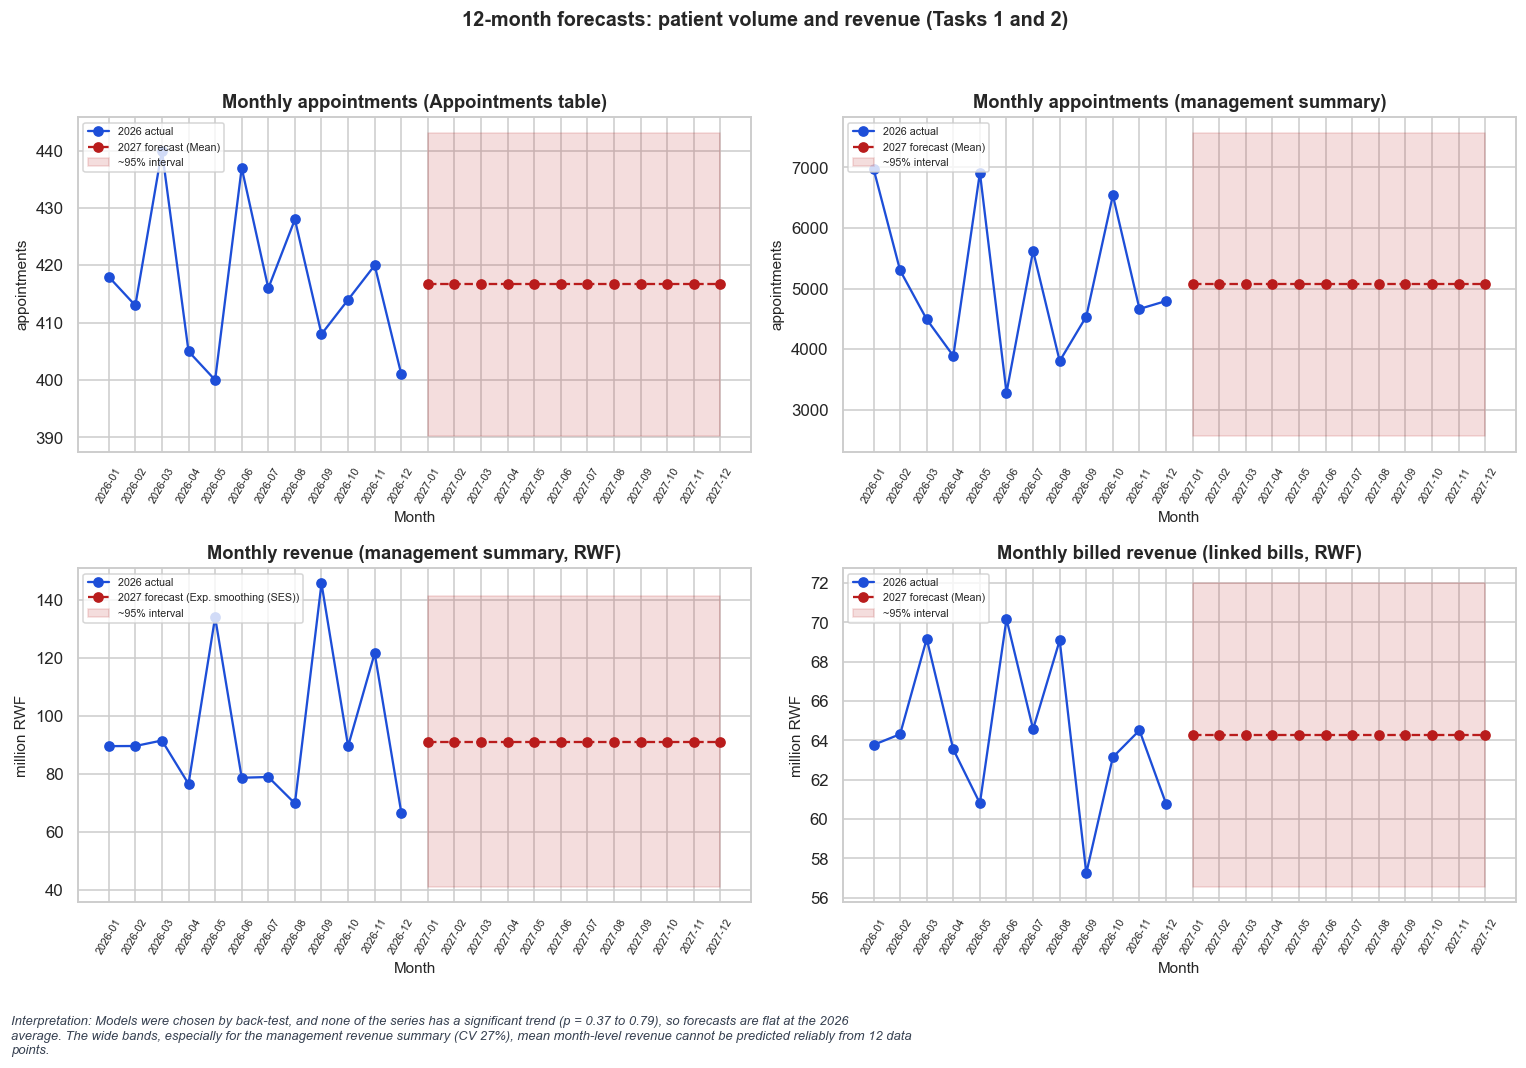

In [51]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9)); ax = ax.ravel()
for a_, (k, v) in zip(ax, FC.items()):
    y = series[k]; scale = 1e6 if "revenue" in k else 1; unit = "million RWF" if scale > 1 else "appointments"
    a_.plot(months, y/scale, marker="o", color=PAL["blue"], label="2026 actual")
    a_.plot(fut_idx, np.array(v["pred"])/scale, marker="o", ls="--", color=PAL["red"], label=f"2027 forecast ({v['best']})")
    a_.fill_between(fut_idx, np.maximum(np.array(v["lo"]), 0)/scale, np.array(v["hi"])/scale, color=PAL["red"], alpha=.15, label="~95% interval")
    a_.set(title=k, xlabel="Month", ylabel=unit); a_.tick_params(axis="x", rotation=60, labelsize=7); a_.legend(fontsize=7, loc="upper left")
savefig(fig, "fig16_forecasts", "12-month forecasts: patient volume and revenue (Tasks 1 and 2)",
    f"{'Back-testing found no model more than 2% more accurate than the plain historical mean for any of the four series' if all(v['best']=='Mean' for v in FC.values()) else 'Models were chosen by back-test'}, and none of the series has a significant trend (p = {min(v['trend_p'] for v in FC.values()):.2f} to {max(v['trend_p'] for v in FC.values()):.2f}), so forecasts are flat at the 2026 average. The wide bands, especially for the management revenue summary (CV {FC['Monthly revenue (management summary, RWF)']['cv']:.0%}), mean month-level revenue cannot be predicted reliably from 12 data points.")

### 7.2 Department workload forecast 
Ten department types × 12 months. The model with the lowest pooled back-test error across all departments is applied to each department; the **overload probability** is the chance that a department-month exceeds the network's 90th-percentile department-month volume.

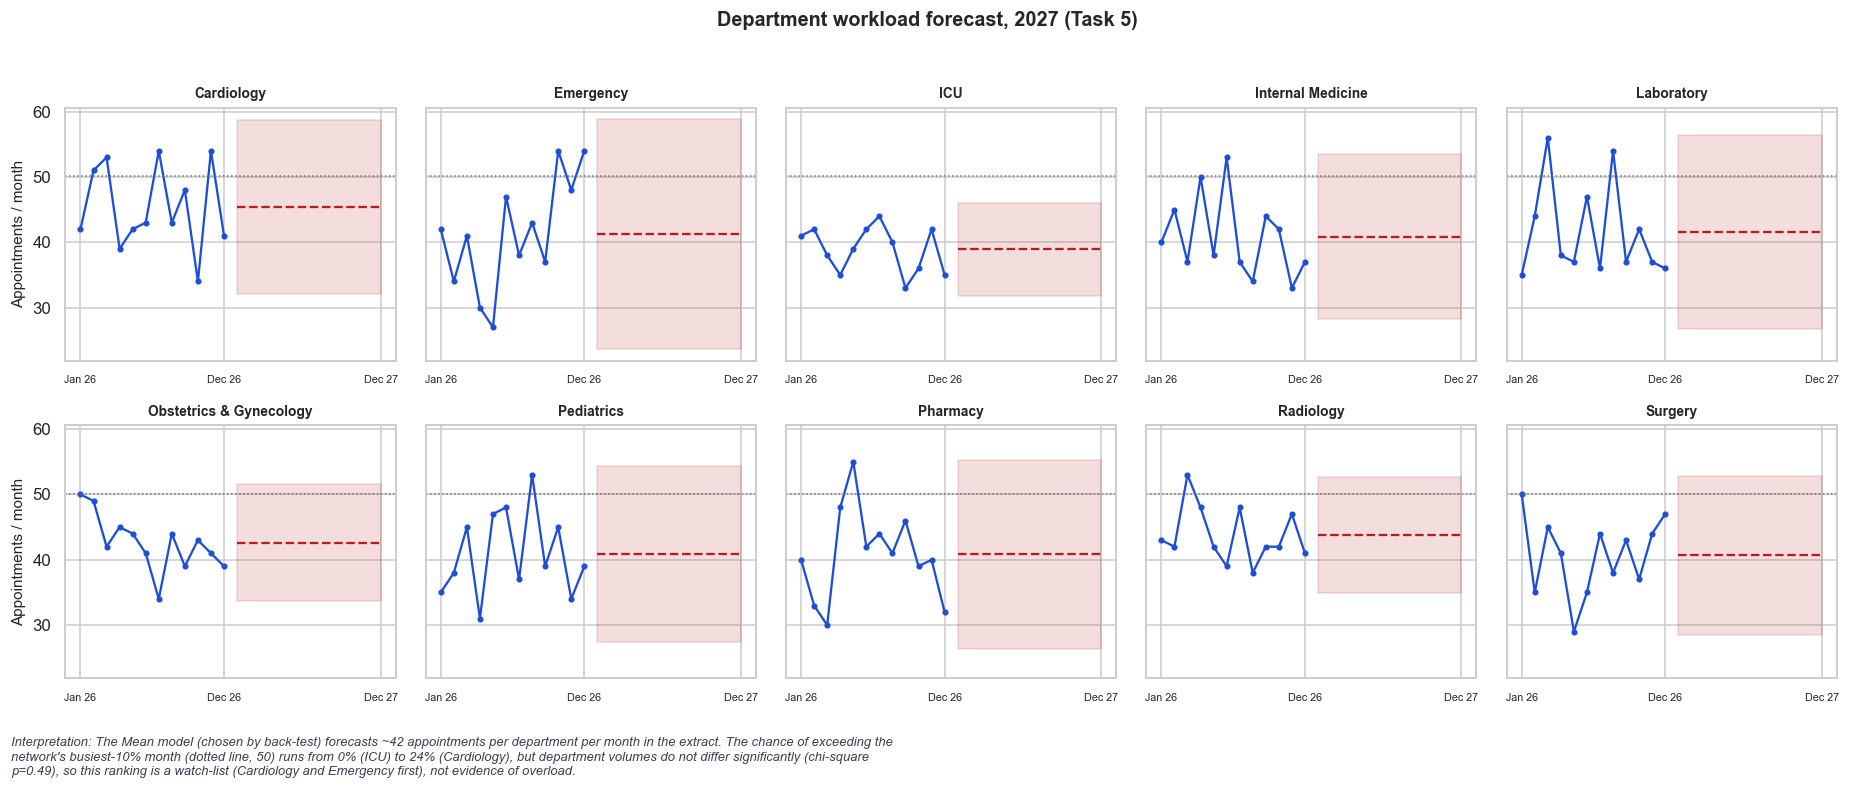

In [52]:
dm = pd.crosstab(df.Month.astype(str), df.DepartmentName)
pooled = sum(backtest(dm[c].values)[0] for c in dm.columns)/dm.shape[1]
best_d = pooled.idxmin()
if pooled[best_d] > 0.98*pooled["Mean"]: best_d = "Mean"
thr = np.quantile(dm.values.flatten(), .90)
rows = []; dept_fc = {}
from scipy.stats import norm
for c in dm.columns:
    pred, se = fc_models(dm[c].values, 12)[best_d]; dept_fc[c] = (pred, se)
    rows.append(dict(Department=c, Hist_monthly_mean=dm[c].mean(), Forecast_monthly_mean=pred.mean(), Lo=np.mean(np.maximum(pred-1.96*se, 0)), Hi=np.mean(pred+1.96*se),
                     Clinical_staff=int(dept_type.loc[c, "ClinicalStaff"]), P_exceed_P90=float(np.mean(1-norm.cdf((thr-pred)/se)))))
dfc = pd.DataFrame(rows); dfc["Fcst_workload_index"] = 100*(dfc.Forecast_monthly_mean/dfc.Clinical_staff)/(dfc.Forecast_monthly_mean/dfc.Clinical_staff).mean(); dfc = dfc.sort_values("P_exceed_P90", ascending=False)
R["dept_forecast"] = dict(best_model=best_d, pooled_mae=pooled.round(3).to_dict(), p90_threshold=float(thr), table=dfc.round(4).to_dict("records"))
fig, axs = plt.subplots(2, 5, figsize=(17, 6.5), sharey=True)
for a_, c in zip(axs.ravel(), dm.columns):
    pred, se = dept_fc[c]; a_.plot(range(12), dm[c].values, marker="o", ms=3, color=PAL["blue"]); a_.plot(range(12, 24), pred, ls="--", color=PAL["red"])
    a_.fill_between(range(12, 24), np.maximum(pred-1.96*se, 0), pred+1.96*se, color=PAL["red"], alpha=.15); a_.axhline(thr, color=PAL["grey"], ls=":", lw=1); a_.set_title(c, fontsize=9); a_.set_xticks([0, 11, 23]); a_.set_xticklabels(["Jan 26","Dec 26","Dec 27"], fontsize=7)
axs[0,0].set_ylabel("Appointments / month"); axs[1,0].set_ylabel("Appointments / month")
savefig(fig, "fig17_dept_forecast", "Department workload forecast, 2027 (Task 5)",
    f"The {best_d} model (chosen by back-test) forecasts ~{dfc.Forecast_monthly_mean.mean():.0f} appointments per department per month in the extract. The chance of exceeding the network's busiest-10% month (dotted line, {thr:.0f}) runs from {dfc.P_exceed_P90.min():.0%} ({dfc.Department.iloc[-1]}) to {dfc.P_exceed_P90.max():.0%} ({dfc.Department.iloc[0]}), but department volumes do not differ significantly (chi-square p={chi_dept.pvalue:.2f}), so this ranking is a watch-list ({dfc.Department.iloc[0]} and {dfc.Department.iloc[1]} first), not evidence of overload.")

### 7.3 Hospital admission prediction 
**There is no Admissions table**, so true admission cannot be modelled. As an explicit *proxy* for "needs admission" the target is **`HighAcuityEmergency` = Emergency visit AND Severe diagnosis** (10.9% of appointments). Visit type and severity are removed from the predictors (otherwise the answer is handed to the model). Features known at the time of the visit: age, sex, chronic condition, BMI (adults), diagnosis, department, facility, province, prior visits, month, weekday, doctor experience, department workload.
Validation: 5-fold **GroupKFold by patient** (a patient never appears in both train and test), out-of-fold predictions, bootstrap 95% CI on AUC.

In [53]:
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve,
                             r2_score, mean_absolute_error, mean_squared_error, balanced_accuracy_score)
from sklearn.inspection import permutation_importance

def make_prep(num, cat):
    return ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False), cat)])
num_adm = ["Age","BMI_clean","PriorVisits","MonthNum","WeekdayNum","DoctorYears","DeptWorkloadIndex","HasChronic"]
cat_adm = ["Gender","ChronicCondition","Diagnosis","DepartmentName","ProvinceName","FacilityID"]
Xa, ya, ga = df[num_adm+cat_adm].copy(), df.HighAcuityEmergency.values, df.PatientID.values
cands = {"Baseline (prevalence)": DummyClassifier(strategy="prior"),
         "Logistic regression": LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced"),
         "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=25, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
         "Gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.04, max_iter=120, l2_regularization=5, random_state=SEED)}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {}
for name, est in cands.items():
    pipe = Pipeline([("prep", make_prep(num_adm, cat_adm)), ("m", est)])
    oof[name] = cross_val_predict(pipe, Xa, ya, groups=ga, cv=cv, method="predict_proba")[:, 1]
def boot_auc(y, s, B=500):
    r_ = np.random.default_rng(SEED); idx = np.arange(len(y)); v = []
    for _ in range(B):
        b = r_.choice(idx, len(idx)); 
        if y[b].min() != y[b].max(): v.append(roc_auc_score(y[b], s[b]))
    return np.percentile(v, [2.5, 97.5])
adm_rows = []
for name, s in oof.items():
    prec_, rec_, thr_ = __import__("sklearn.metrics", fromlist=["x"]).precision_recall_curve(ya, s); f1s = 2*prec_*rec_/np.maximum(prec_+rec_, 1e-9); k = np.nanargmax(f1s[:-1]) if len(thr_) else 0
    t_ = thr_[k] if len(thr_) else 0.5; yh = (s >= t_).astype(int); ci_ = boot_auc(ya, s) if name != "Baseline (prevalence)" else (0.5, 0.5)
    adm_rows.append(dict(Model=name, AUC=roc_auc_score(ya, s), AUC_lo=ci_[0], AUC_hi=ci_[1], PR_AUC=average_precision_score(ya, s), Accuracy=accuracy_score(ya, yh), Precision=precision_score(ya, yh, zero_division=0),
                         Recall=recall_score(ya, yh), F1=f1_score(ya, yh), Threshold=t_))
adm = pd.DataFrame(adm_rows); best_adm = adm.loc[adm.Model != "Baseline (prevalence)"].sort_values("AUC", ascending=False).iloc[0]
prev = ya.mean(); R["admission"] = dict(prevalence=float(prev), n=len(ya), positives=int(ya.sum()), table=adm.round(4).to_dict("records"), best=best_adm.Model, best_auc=float(best_adm.AUC), best_ci=[float(best_adm.AUC_lo), float(best_adm.AUC_hi)],
                                        f1_all_positive=float(2*prev/(1+prev)))
adm.round(3)

,Model,AUC,AUC_lo,AUC_hi,PR_AUC,Accuracy,Precision,Recall,F1,Threshold
0,Baseline (prevalence),0.499,0.500,0.500,0.109,0.109,0.109,1.000,0.196,0.109
1,Logistic regression,0.495,0.471,0.519,0.112,0.224,0.112,0.884,0.199,0.395
2,Random forest,0.496,0.471,0.524,0.111,0.111,0.109,1.000,0.197,0.295
3,Gradient boosting,0.501,0.477,0.527,0.112,0.148,0.110,0.965,0.198,0.073


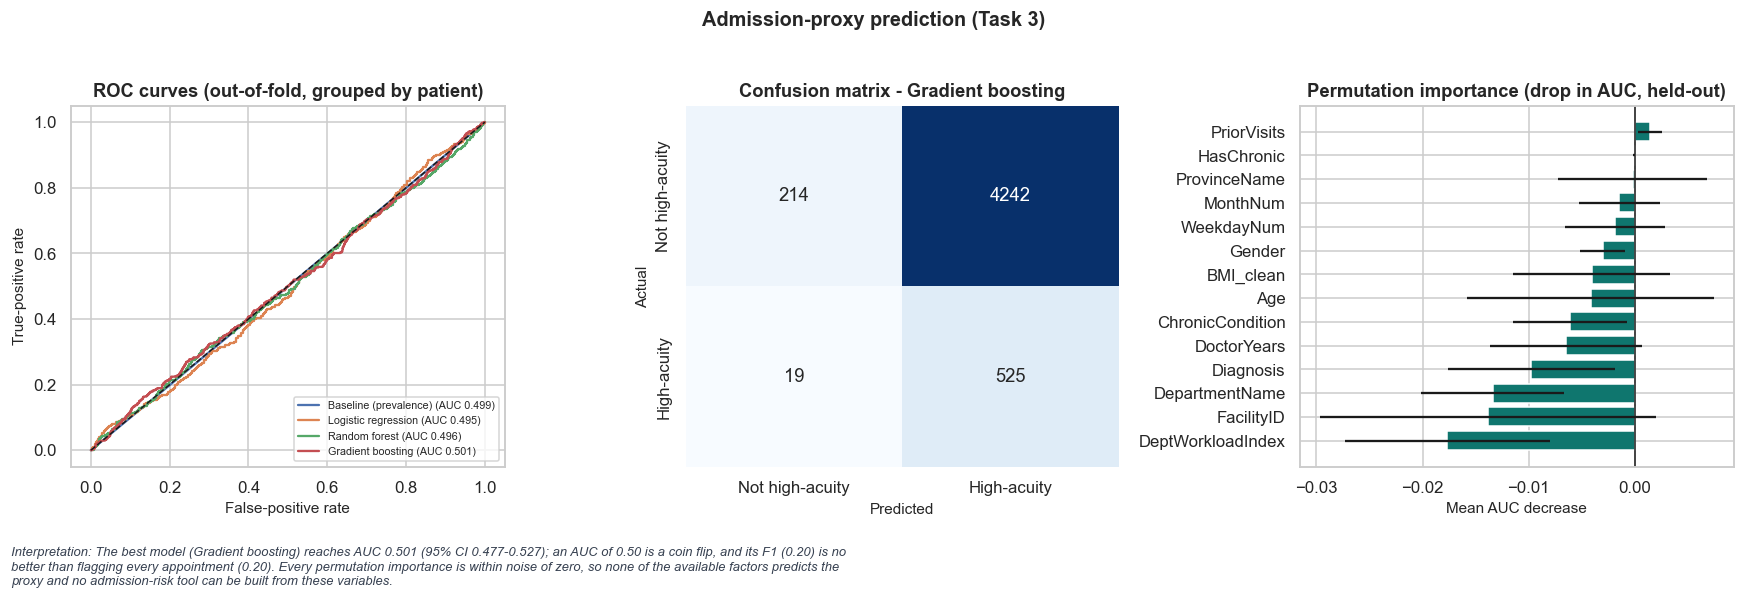

In [54]:
# Permutation importance of the best model on a held-out patient-grouped split + confusion matrix + ROC
tr, te = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED).split(Xa, ya, ga))
best_pipe = Pipeline([("prep", make_prep(num_adm, cat_adm)), ("m", cands[best_adm.Model])]).fit(Xa.iloc[tr], ya[tr])
pi = permutation_importance(best_pipe, Xa.iloc[te], ya[te], scoring="roc_auc", n_repeats=15, random_state=SEED)
imp = pd.DataFrame({"feature": Xa.columns, "mean": pi.importances_mean, "sd": pi.importances_std}).sort_values("mean")
cmx = confusion_matrix(ya, (oof[best_adm.Model] >= best_adm.Threshold).astype(int))
R["admission"]["confusion"] = cmx.tolist(); R["admission"]["perm_importance"] = imp.sort_values("mean", ascending=False).round(4).to_dict("records")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for name, s in oof.items():
    fpr, tpr, _ = roc_curve(ya, s); ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(ya, s):.3f})")
ax[0].plot([0,1], [0,1], "k--", lw=1); ax[0].set(title="ROC curves (out-of-fold, grouped by patient)", xlabel="False-positive rate", ylabel="True-positive rate"); ax[0].legend(fontsize=7, loc="lower right")
sns.heatmap(cmx, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1], xticklabels=["Not high-acuity","High-acuity"], yticklabels=["Not high-acuity","High-acuity"]); ax[1].set(title=f"Confusion matrix - {best_adm.Model}", xlabel="Predicted", ylabel="Actual")
ax[2].barh(imp.feature, imp["mean"], xerr=imp.sd, color=PAL["teal"]); ax[2].axvline(0, color="k", lw=1); ax[2].set(title="Permutation importance (drop in AUC, held-out)", xlabel="Mean AUC decrease")
savefig(fig, "fig18_admission_model", "Admission-proxy prediction (Task 3)",
    f"The best model ({best_adm.Model}) reaches AUC {best_adm.AUC:.3f} (95% CI {best_adm.AUC_lo:.3f}-{best_adm.AUC_hi:.3f}); an AUC of 0.50 is a coin flip, and its F1 ({best_adm.F1:.2f}) is no better than flagging every appointment ({2*prev/(1+prev):.2f}). Every permutation importance is within noise of zero, so none of the available factors predicts the proxy and no admission-risk tool can be built from these variables.")

### 7.4 Patient satisfaction prediction 
Only the **1,756 appointments with feedback** can be used. Two framings: regression on the 1-5 rating, and 3-class classification (Low 1-2 / Medium 3 / High 4-5). Predictors include clinical, operational and financial variables. 5-fold patient-grouped CV.

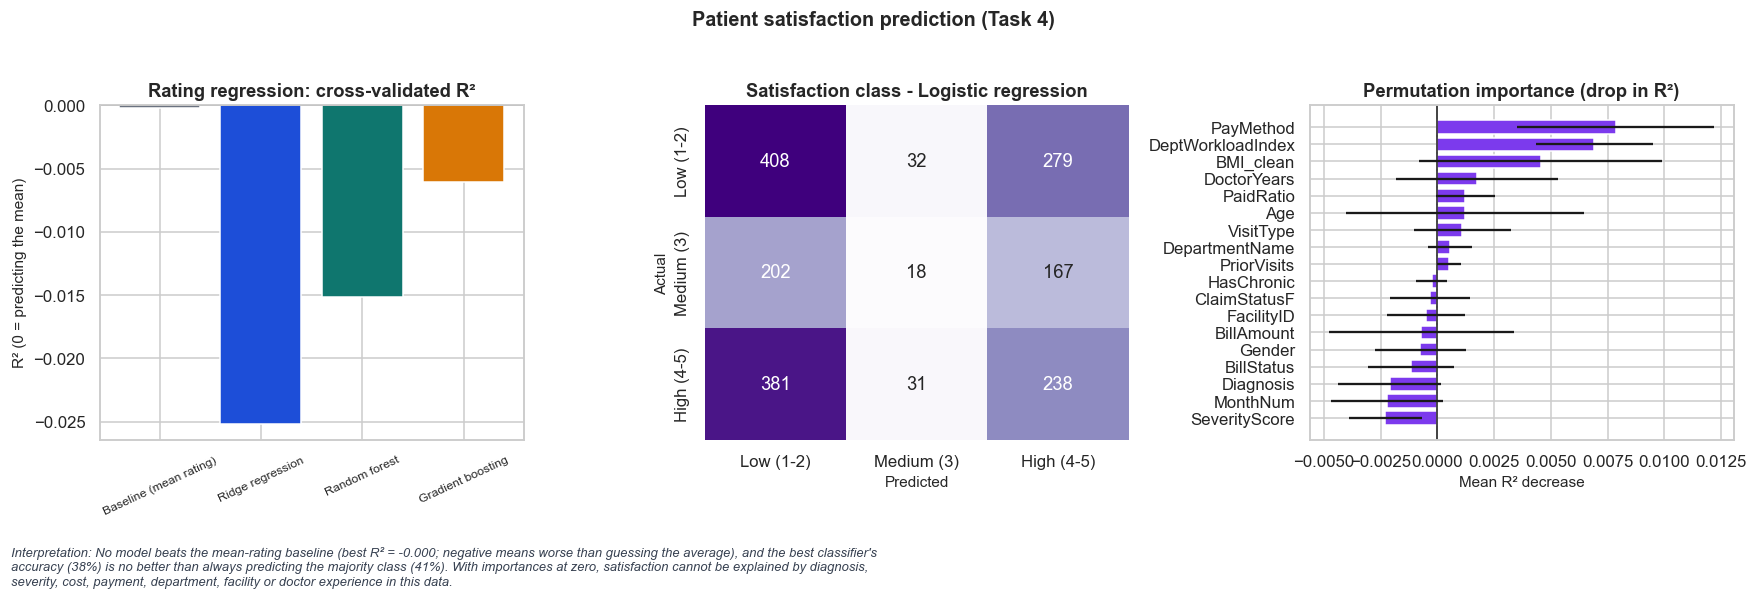

In [55]:
sat = df.dropna(subset=["Rating"]).copy(); sat["ClaimStatusF"] = sat.ClaimStatus.fillna("No claim")
num_s = ["Age","BMI_clean","SeverityScore","BillAmount","PaidRatio","DoctorYears","PriorVisits","DeptWorkloadIndex","MonthNum","HasChronic"]
cat_s = ["Gender","Diagnosis","VisitType","DepartmentName","FacilityID","PayMethod","ClaimStatusF","BillStatus"]
Xs, ys, ysc, gs = sat[num_s+cat_s], sat.Rating.values.astype(float), sat.SatisfactionCategory.astype(str).values, sat.PatientID.values
cvs = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
reg_models = {"Baseline (mean rating)": DummyRegressor(), "Ridge regression": Ridge(alpha=50), "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
              "Gradient boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03, max_iter=100, l2_regularization=10, random_state=SEED)}
rrows = []; oof_reg = {}
for name, est in reg_models.items():
    pipe = Pipeline([("prep", make_prep(num_s, cat_s)), ("m", est)]); fold = []
    pred = np.zeros(len(ys))
    for tr_, te_ in cvs.split(Xs, ysc, gs):
        pipe.fit(Xs.iloc[tr_], ys[tr_]); pred[te_] = pipe.predict(Xs.iloc[te_]); fold.append(r2_score(ys[te_], pred[te_]))
    oof_reg[name] = pred
    rrows.append(dict(Model=name, R2=r2_score(ys, pred), R2_fold_sd=np.std(fold), MAE=mean_absolute_error(ys, pred), RMSE=np.sqrt(mean_squared_error(ys, pred))))
reg_tbl = pd.DataFrame(rrows)
clf_models = {"Baseline (majority class)": DummyClassifier(strategy="most_frequent"), "Logistic regression": LogisticRegression(max_iter=3000, C=0.2),
              "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=15, n_jobs=-1, random_state=SEED)}
crows = []; oof_clf = {}
for name, est in clf_models.items():
    pipe = Pipeline([("prep", make_prep(num_s, cat_s)), ("m", est)]); pred = np.empty(len(ys), dtype=object)
    for tr_, te_ in cvs.split(Xs, ysc, gs): pipe.fit(Xs.iloc[tr_], ysc[tr_]); pred[te_] = pipe.predict(Xs.iloc[te_])
    oof_clf[name] = pred
    crows.append(dict(Model=name, Accuracy=accuracy_score(ysc, pred), Balanced_accuracy=balanced_accuracy_score(ysc, pred), Macro_F1=f1_score(ysc, pred, average="macro")))
clf_tbl = pd.DataFrame(crows)
best_clf = clf_tbl[clf_tbl.Model != "Baseline (majority class)"].sort_values("Macro_F1", ascending=False).iloc[0].Model
labels = ["Low (1-2)","Medium (3)","High (4-5)"]; cm_s = confusion_matrix(ysc, oof_clf[best_clf], labels=labels)
rf_s = Pipeline([("prep", make_prep(num_s, cat_s)), ("m", reg_models["Random forest"])]); tr_, te_ = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED).split(Xs, ysc, gs))
rf_s.fit(Xs.iloc[tr_], ys[tr_]); pis = permutation_importance(rf_s, Xs.iloc[te_], ys[te_], scoring="r2", n_repeats=15, random_state=SEED)
imp_s = pd.DataFrame({"feature": Xs.columns, "mean": pis.importances_mean, "sd": pis.importances_std}).sort_values("mean")
R["satisfaction_model"] = dict(n=len(sat), class_dist=pd.Series(ysc).value_counts(normalize=True).round(4).to_dict(), regression=reg_tbl.round(4).to_dict("records"), classification=clf_tbl.round(4).to_dict("records"),
                               best_clf=best_clf, confusion=cm_s.tolist(), labels=labels, perm_importance=imp_s.sort_values("mean", ascending=False).round(4).to_dict("records"))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].bar(reg_tbl.Model, reg_tbl.R2, color=[PAL["grey"], PAL["blue"], PAL["teal"], PAL["amber"]]); ax[0].axhline(0, color="k", lw=1); ax[0].tick_params(axis="x", rotation=25, labelsize=8); ax[0].set(title="Rating regression: cross-validated R²", ylabel="R² (0 = predicting the mean)")
sns.heatmap(cm_s, annot=True, fmt="d", cmap="Purples", cbar=False, ax=ax[1], xticklabels=labels, yticklabels=labels); ax[1].set(title=f"Satisfaction class - {best_clf}", xlabel="Predicted", ylabel="Actual")
ax[2].barh(imp_s.feature, imp_s["mean"], xerr=imp_s.sd, color=PAL["purple"]); ax[2].axvline(0, color="k", lw=1); ax[2].set(title="Permutation importance (drop in R²)", xlabel="Mean R² decrease")
savefig(fig, "fig19_satisfaction_model", "Patient satisfaction prediction (Task 4)",
    f"No model beats the mean-rating baseline (best R² = {reg_tbl.R2.max():.3f}; negative means worse than guessing the average), and the best classifier's accuracy ({clf_tbl.loc[clf_tbl.Model==best_clf,'Accuracy'].iloc[0]:.0%}) is no better than always predicting the majority class ({clf_tbl.loc[clf_tbl.Model.str.startswith('Baseline'),'Accuracy'].iloc[0]:.0%}). With importances at zero, satisfaction cannot be explained by diagnosis, severity, cost, payment, department, facility or doctor experience in this data.")

### 7.5 Chronic-condition risk screen ("which patient groups are most at risk?")
A cross-validated logistic regression predicts whether a patient has any chronic condition from age, sex, adult BMI, province and blood group (all 20,000 patients). If these factors carry real risk information, AUC will be clearly above 0.5.

In [56]:
Xc = p[["Age","Gender","BMI_clean","ProvinceName","BloodGroup"]].copy(); yc = p.HasChronic.values
prep_c = make_prep(["Age","BMI_clean"], ["Gender","ProvinceName","BloodGroup"])
pc = cross_val_predict(Pipeline([("prep", prep_c), ("m", LogisticRegression(max_iter=2000))]), Xc, yc, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), groups=p.PatientID, method="predict_proba")[:, 1]
auc_c = roc_auc_score(yc, pc); ci_c = boot_auc(yc, pc)
bmi_c = pd.cut(p.BMI_clean, [0, 18.5, 25, 30, 100], labels=["Underweight","Normal","Overweight","Obese"]); ct_b = pd.crosstab(bmi_c, p.HasChronic); chi_b = stats.chi2_contingency(ct_b)
R["chronic_screen"] = dict(auc=float(auc_c), ci=[float(ci_c[0]), float(ci_c[1])], bmi_chi_p=float(chi_b[1]), bmi_rates={str(k): float(v) for k, v in (ct_b[1]/ct_b.sum(axis=1)).items()})
print(f"Chronic-condition risk screen: AUC = {auc_c:.3f} (95% CI {ci_c[0]:.3f}-{ci_c[1]:.3f}); chronic prevalence by adult BMI band: " + ", ".join(f"{k} {100*v:.1f}%" for k, v in (ct_b[1]/ct_b.sum(axis=1)).items()) + f" (chi-square p={chi_b[1]:.2f})")

Chronic-condition risk screen: AUC = 0.516 (95% CI 0.507-0.526); chronic prevalence by adult BMI band: Underweight 74.7%, Normal 74.5%, Overweight 74.8%, Obese 74.6% (chi-square p=1.00)


## 8. Clustering analysis
K-Means on standardised features. For each segmentation: silhouette scores for k = 2-8, the chosen k (best silhouette within k = 3-6, since management wants actionable segments), a **null comparison** (silhouette after shuffling each feature independently, which destroys any real structure), and a **stability check** (agreement, via adjusted Rand index, between a full-data fit and fits on 80% subsamples). A segmentation is only trustworthy if it beats the null and is stable.

In [57]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

def cluster_study(X, ks=range(2, 9), pick=(3, 6), n_null=15, label=""):
    Z = StandardScaler().fit_transform(X); sil = {}
    for k in ks: sil[k] = silhouette_score(Z, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z))
    kbest = max([k for k in sil if pick[0] <= k <= pick[1]], key=lambda k: sil[k]); km = KMeans(kbest, n_init=20, random_state=SEED).fit(Z); lab = km.labels_
    r_ = np.random.default_rng(SEED); null = []
    for _ in range(n_null):
        Zn = np.column_stack([r_.permutation(Z[:, j]) for j in range(Z.shape[1])]); null.append(silhouette_score(Zn, KMeans(kbest, n_init=5, random_state=SEED).fit_predict(Zn)))
    ari = []
    for i in range(10):
        idx = r_.choice(len(Z), int(.8*len(Z)), replace=False); kmi = KMeans(kbest, n_init=5, random_state=i).fit(Z[idx]); ari.append(adjusted_rand_score(lab, kmi.predict(Z)))
    return dict(Z=Z, sil=sil, k=kbest, labels=lab, null_mean=float(np.mean(null)), null_hi=float(np.percentile(null, 95)), ari=float(np.mean(ari)), sil_k=sil[kbest])

def auto_label(prof_z, cols):
    out = {}
    for c in prof_z.index:
        top = prof_z.loc[c].abs().sort_values(ascending=False).index[:2]
        out[c] = " / ".join(("High " if prof_z.loc[c, t] > 0 else "Low ") + t for t in top)
    return out

# ---- 8.1 Patients (4,443 patients with at least one appointment)
pt = df.groupby("PatientID").agg(Age=("Age","first"), HasChronic=("HasChronic","first"), Visits=("AppointmentID","size"), MeanBill=("BillAmount","mean"),
        MeanSeverity=("SeverityScore","mean"), ClaimShare=("HasClaim","mean"), EmergencyShare=("VisitType", lambda s: (s=="Emergency").mean())).reset_index()
pt["HighRisk"] = pt.PatientID.map(p.set_index("PatientID").HighRisk)
pcl = cluster_study(pt[["Age","HasChronic","Visits","MeanBill","MeanSeverity","ClaimShare","EmergencyShare"]]); pt["Cluster"] = pcl["labels"]
feat_p = ["Age","HasChronic","Visits","MeanBill","MeanSeverity","ClaimShare","EmergencyShare"]
prof = pt.groupby("Cluster")[feat_p+["HighRisk"]].mean(); prof["Patients"] = pt.groupby("Cluster").size(); prof_z = (prof[feat_p]-pt[feat_p].mean())/pt[feat_p].std()
names_p = auto_label(prof_z, feat_p); prof["Profile"] = pd.Series(names_p)
R["clusters_patients"] = dict(k=pcl["k"], silhouette=pcl["sil_k"], null_mean=pcl["null_mean"], null_p95=pcl["null_hi"], stability_ari=pcl["ari"], sil_by_k={str(k): float(v) for k, v in pcl["sil"].items()}, profile=prof.round(3).reset_index().to_dict("records"), n=len(pt))
prof.round(2)

,Age,HasChronic,Visits,MeanBill,MeanSeverity,ClaimShare,EmergencyShare,HighRisk,Patients,Profile
Cluster,,,,,,,,,,
0,46.49,0.77,2.09,154420.78,1.97,0.7,0.33,0.54,510,High Visits / High HasChronic
1,45.76,0.75,1.00,153635.58,1.99,1.0,0.00,0.39,1873,Low EmergencyShare / High ClaimShare
2,45.02,0.74,1.00,152897.71,2.00,1.0,1.00,0.40,902,High EmergencyShare / High ClaimShare
3,45.09,0.73,1.00,156006.02,2.00,0.0,0.34,0.36,1158,Low ClaimShare / Low Visits


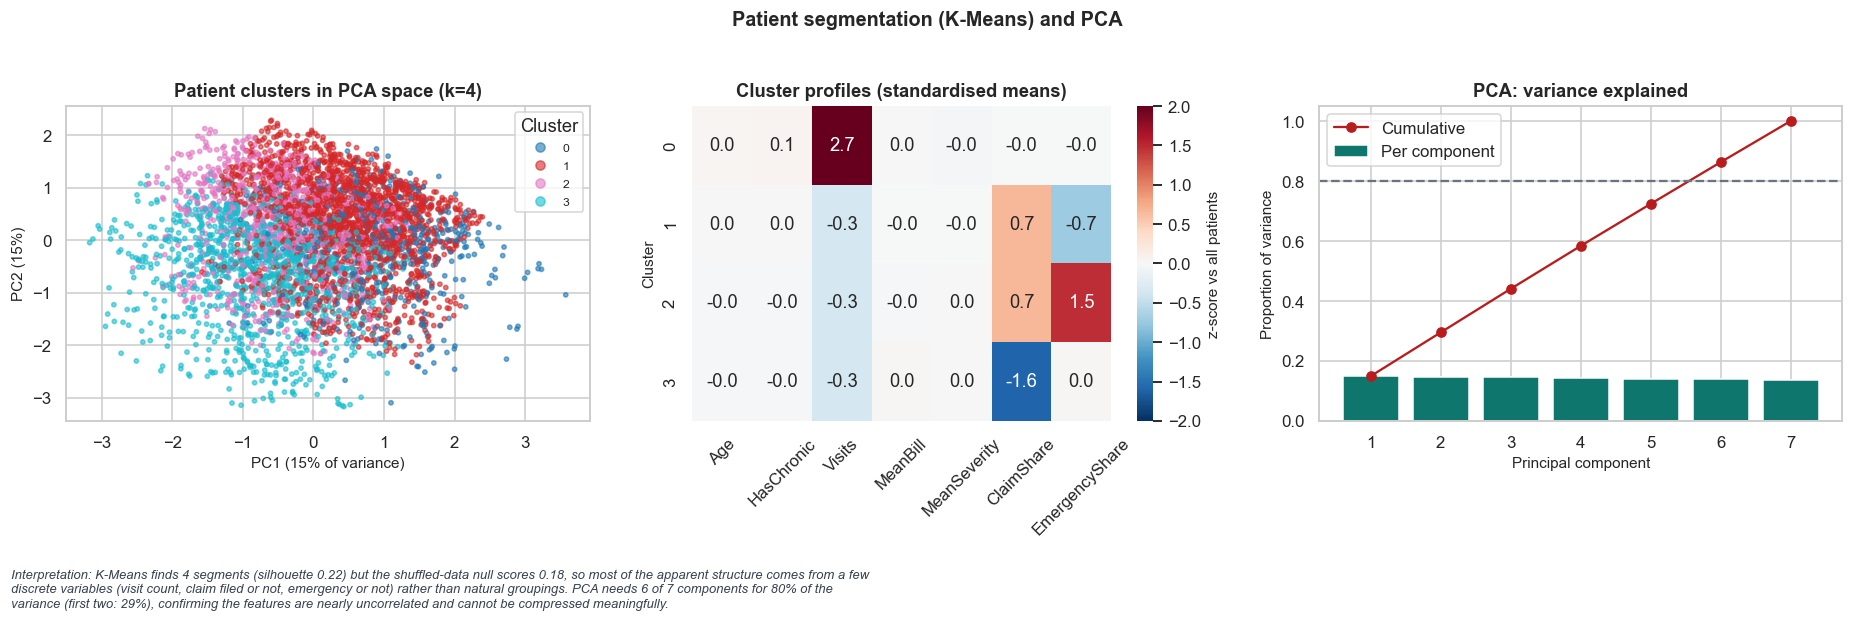

In [58]:
pca = PCA().fit(pcl["Z"]); evr = pca.explained_variance_ratio_; xy = PCA(2).fit_transform(pcl["Z"])
R["pca"] = dict(explained=[float(v) for v in evr], cumulative=[float(v) for v in np.cumsum(evr)], n_for_80=int(np.argmax(np.cumsum(evr) >= .8))+1, n_for_90=int(np.argmax(np.cumsum(evr) >= .9))+1, loadings=pd.DataFrame(pca.components_[:2].T, index=feat_p, columns=["PC1","PC2"]).round(3).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sc = ax[0].scatter(xy[:,0], xy[:,1], c=pt.Cluster, cmap="tab10", s=8, alpha=.6); ax[0].set(title=f"Patient clusters in PCA space (k={pcl['k']})", xlabel=f"PC1 ({evr[0]:.0%} of variance)", ylabel=f"PC2 ({evr[1]:.0%})")
ax[0].legend(*sc.legend_elements(), title="Cluster", fontsize=8)
sns.heatmap(prof_z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, ax=ax[1], cbar_kws=dict(label="z-score vs all patients")); ax[1].set(title="Cluster profiles (standardised means)", xlabel="", ylabel="Cluster"); ax[1].tick_params(axis="x", rotation=45)
ax[2].bar(range(1, len(evr)+1), evr, color=PAL["teal"], label="Per component"); ax[2].plot(range(1, len(evr)+1), np.cumsum(evr), marker="o", color=PAL["red"], label="Cumulative"); ax[2].axhline(.8, color=PAL["grey"], ls="--")
ax[2].set(title="PCA: variance explained", xlabel="Principal component", ylabel="Proportion of variance"); ax[2].legend()
savefig(fig, "fig20_patient_clusters_pca", "Patient segmentation (K-Means) and PCA",
    f"K-Means finds {pcl['k']} segments (silhouette {pcl['sil_k']:.2f}) but the shuffled-data null scores {pcl['null_mean']:.2f}, so most of the apparent structure comes from a few discrete variables (visit count, claim filed or not, emergency or not) rather than natural groupings. PCA needs {R['pca']['n_for_80']} of {len(evr)} components for 80% of the variance (first two: {evr[:2].sum():.0%}), confirming the features are nearly uncorrelated and cannot be compressed meaningfully.")

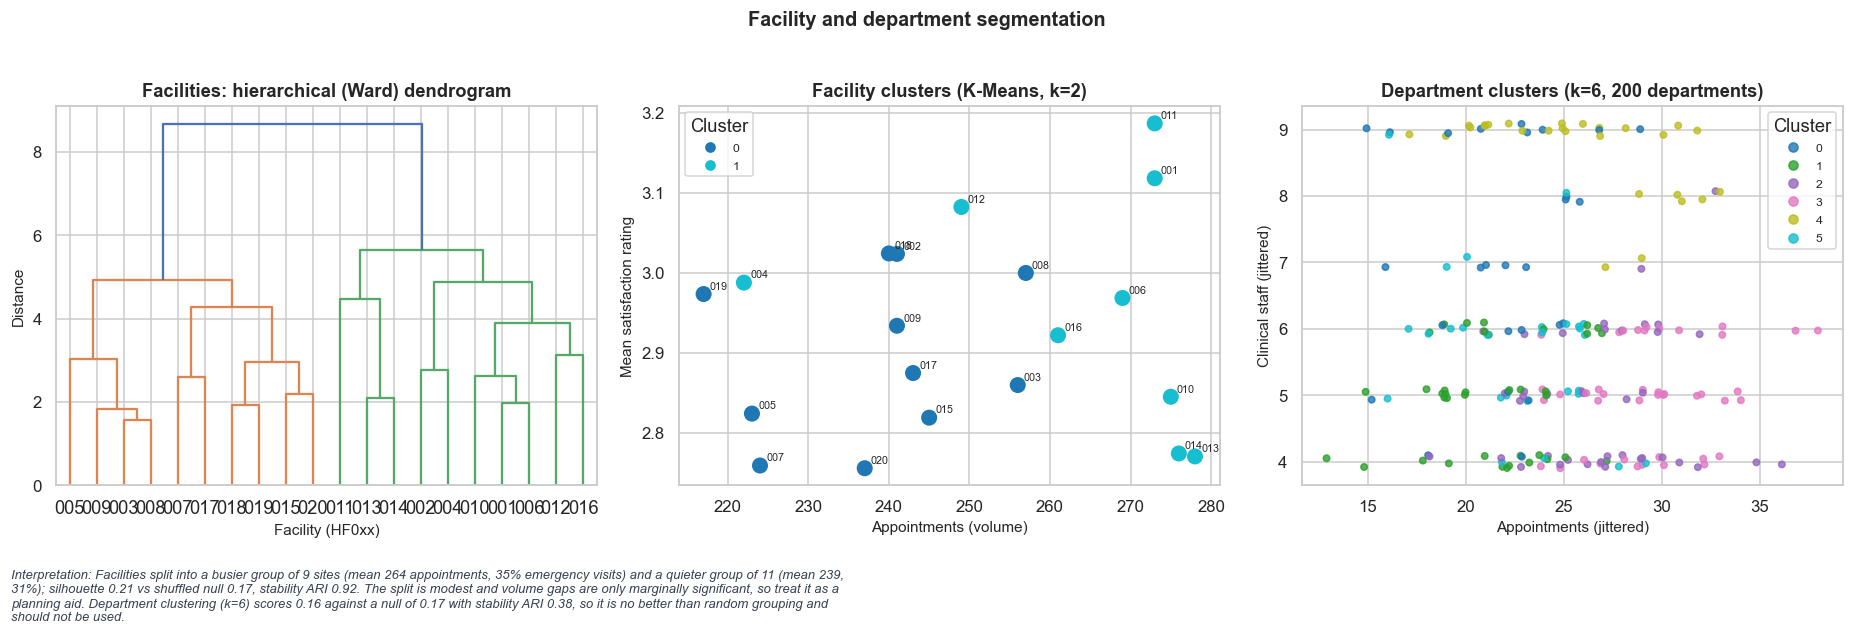

,Segmentation,k,Silhouette,Null silhouette (shuffled),Stability (ARI)
0,Patients,4,0.221,0.184,0.547
1,Facilities,2,0.213,0.165,0.920
2,Departments,6,0.163,0.170,0.382


In [59]:
# ---- 8.2 Facilities (20) and 8.3 Departments (200)
ffe = ["Appointments","MeanRating","CollectionRate","ClaimApprovalRate","EmergencyShare","SevereShare","ClinicalStaff"]
fcl = cluster_study(fac[ffe], ks=range(2, 7), pick=(2, 4), n_null=30); fac["Cluster"] = fcl["labels"]
fprof = fac.groupby("Cluster")[ffe+["PerformanceScore"]].mean(); fprof["Facilities"] = fac.groupby("Cluster").size(); fprof["Members"] = fac.groupby("Cluster").apply(lambda d: ", ".join(d.index.str[2:]))
fprof_z = (fprof[ffe]-fac[ffe].mean())/fac[ffe].std(); fprof["Profile"] = pd.Series(auto_label(fprof_z, ffe))
R["clusters_facilities"] = dict(k=fcl["k"], silhouette=fcl["sil_k"], null_mean=fcl["null_mean"], null_p95=fcl["null_hi"], stability_ari=fcl["ari"], profile=fprof.round(3).reset_index().to_dict("records"))
dfe = ["Appointments","ClinicalStaff","MeanBill","SevereShare","EmergencyShare"]
dd = df.groupby("DepartmentID").agg(MeanBill=("BillAmount","mean"), SevereShare=("Severity", lambda s: (s=="Severe").mean()), EmergencyShare=("VisitType", lambda s: (s=="Emergency").mean())); dd = dep.set_index("DepartmentID")[["DepartmentName","Appointments","ClinicalStaff","WorkloadIndex"]].join(dd).dropna()
dcl = cluster_study(dd[dfe], ks=range(2, 9), pick=(3, 6), n_null=15); dd["Cluster"] = dcl["labels"]
dprof = dd.groupby("Cluster")[dfe+["WorkloadIndex"]].mean(); dprof["Departments"] = dd.groupby("Cluster").size(); dprof_z = (dprof[dfe]-dd[dfe].mean())/dd[dfe].std(); dprof["Profile"] = pd.Series(auto_label(dprof_z, dfe))
R["clusters_departments"] = dict(k=dcl["k"], silhouette=dcl["sil_k"], null_mean=dcl["null_mean"], null_p95=dcl["null_hi"], stability_ari=dcl["ari"], profile=dprof.round(3).reset_index().to_dict("records"))
Zl = linkage(fcl["Z"], "ward")
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
dendrogram(Zl, labels=fac.index.str[2:].tolist(), ax=ax[0], color_threshold=0.7*Zl[-1, 2]); ax[0].set(title="Facilities: hierarchical (Ward) dendrogram", xlabel="Facility (HF0xx)", ylabel="Distance")
sc = ax[1].scatter(fac.Appointments, fac.MeanRating, c=fac.Cluster, cmap="tab10", s=90)
for fid, r_ in fac.iterrows(): ax[1].annotate(fid[2:], (r_.Appointments, r_.MeanRating), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax[1].set(title=f"Facility clusters (K-Means, k={fcl['k']})", xlabel="Appointments (volume)", ylabel="Mean satisfaction rating"); ax[1].legend(*sc.legend_elements(), title="Cluster", fontsize=8)
sc = ax[2].scatter(dd.Appointments + rng.uniform(-.25, .25, len(dd)), dd.ClinicalStaff + rng.uniform(-.1, .1, len(dd)), c=dd.Cluster, cmap="tab10", s=18, alpha=.8)
ax[2].set(title=f"Department clusters (k={dcl['k']}, 200 departments)", xlabel="Appointments (jittered)", ylabel="Clinical staff (jittered)"); ax[2].legend(*sc.legend_elements(), title="Cluster", fontsize=8)
_f = fprof.sort_values("Appointments", ascending=False); _fh, _fl = _f.iloc[0], _f.iloc[1]
_dep_ok = dcl["sil_k"] > dcl["null_hi"]
savefig(fig, "fig21_facility_dept_clusters", "Facility and department segmentation",
    f"Facilities split into a busier group of {int(_fh.Facilities)} sites (mean {_fh.Appointments:.0f} appointments, {_fh.EmergencyShare:.0%} emergency visits) and a quieter group of {int(_fl.Facilities)} (mean {_fl.Appointments:.0f}, {_fl.EmergencyShare:.0%}); silhouette {fcl['sil_k']:.2f} vs shuffled null {fcl['null_mean']:.2f}, stability ARI {fcl['ari']:.2f}. The split is modest and volume gaps are only marginally significant, so treat it as a planning aid. Department clustering (k={dcl['k']}) scores {dcl['sil_k']:.2f} against a null of {dcl['null_mean']:.2f} with stability ARI {dcl['ari']:.2f}, so " + ("it shows some structure." if _dep_ok else "it is no better than random grouping and should not be used."))
pd.DataFrame({"Segmentation": ["Patients","Facilities","Departments"], "k": [pcl["k"], fcl["k"], dcl["k"]], "Silhouette": [pcl["sil_k"], fcl["sil_k"], dcl["sil_k"]], "Null silhouette (shuffled)": [pcl["null_mean"], fcl["null_mean"], dcl["null_mean"]], "Stability (ARI)": [pcl["ari"], fcl["ari"], dcl["ari"]]}).round(3)

## 9. Business recommendations
Every recommendation is tied to evidence from the analysis above and carries an honest **confidence** rating. Because most relationships in this dataset are statistically null, the strongest recommendations concern **data capture, billing integrity and process**, not clinical targeting.

In [60]:
dwl = df.groupby("DoctorID").size(); p90_p10 = float(dwl.quantile(.9)/dwl.quantile(.1))
fa_hi = fac.sort_values("ApptPerClinicalStaff", ascending=False); fa_lo = fac.sort_values("ApptPerClinicalStaff")
spread = float(fa_hi.ApptPerClinicalStaff.iloc[0]/fa_lo.ApptPerClinicalStaff.iloc[0]-1)
low_share = float((T["feedback"].Rating <= 2).mean())
recs = pd.DataFrame([
 ("Operational challenges","The transaction chain is broken: only 5,000 of 60,000 bills, diagnoses and payments link to an appointment, and facility/doctor/department disagree on ~95% of appointments.",
  "Fix the data pipeline first: enforce appointment-ID foreign keys, derive facility from the department/doctor hierarchy, and add the missing admissions, lab, prescription, referral and facility-master tables before any further modelling.","Critical enabler for every other analysis","High"),
 ("Operational challenges","The brief's headline questions on admissions, length of stay, bed use and referrals cannot be answered: no admission data exist and all 2,000 beds are 'Available'.",
  "Record bed status in real time (occupied/cleaning/out of service) and capture admission and discharge timestamps.","Enables bed-utilisation and LOS models","High"),
 ("High-risk patient groups",f"{R['patients']['chronic_pct']:.0%} of patients carry a chronic condition with no gradient by age, sex or province (tests 5-7, all non-significant after correction); {R['child_chronic']['hypertension']:,} under-18s are recorded with hypertension. The rule-based flag marks {R['patients']['high_risk_n']:,} patients ({R['patients']['high_risk_n']/n_pat:.0%}) as high risk.",
  "Audit chronic-condition coding (especially for children). Until validated, use a universal chronic-care outreach for flagged high-risk patients (age 65+ with a chronic condition, or any chronic condition with a severe diagnosis) rather than age/sex/region targeting.","Reaches the 5,028 flagged patients; avoids mis-targeting","Medium"),
 ("Patient satisfaction",f"{low_share:.0%} of all 21,064 ratings are 1-2. No facility or department differs significantly (tests 2 and 4), and no clinical, financial or operational variable predicts rating (R² ≤ 0). Text comments contradict ratings in {R['experience']['contradiction_share']:.0%} of cases.",
  "Treat poor satisfaction as a network-wide service problem, not a site problem: run a network-wide patient-journey review (waiting, communication, billing). Link every survey to its appointment, and replace free-text comments with structured reason codes.","Targets the ~40% unhappy patients; makes future drivers measurable","Medium"),
 ("Resource optimisation",f"Doctor workload ranges {int(dwl.min())}-{int(dwl.max())} appointments (P90/P10 = {p90_p10:.1f}x); facility load per clinical staff member differs by {spread:.0%} ({fa_hi.index[0]} highest, {fa_lo.index[0]} lowest), while rosters are almost identical (57-60 staff). Facility volume gaps are marginal (p={chi_fac.pvalue:.3f}).",
  f"Pilot a scheduling rule that balances doctor panels, and move 2-3 clinical staff from the lowest-load sites ({', '.join(fa_lo.index[:3])}) to the highest-load sites ({', '.join(fa_hi.index[:3])}); re-measure after one quarter before a permanent change.","Narrows a ~"+f"{spread:.0%}"+" load gap at no extra headcount","Low-Medium"),
 ("Revenue improvement",f"{R['finance']['outstanding']/1e9:.2f}bn RWF ({1-R['finance']['collection_rate']:.1%} of billings) is unpaid across {int((bl.Outstanding>0).sum()):,} underpaid bills, yet Billing.Status is unrelated to what was paid (test 9). {R['finance']['claim_pending']:,} insurance claims ({R['finance']['pending_claim_amt']/1e9:.2f}bn RWF) are still pending, spread evenly over four insurers.",
  "Rebuild payment status from payment records (Amount - AmountPaid), start a collections list for the largest underpaid bills, and set a claim turnaround target for all four insurers (e.g. clear pending claims within 30 days).","Up to 0.92bn RWF of receivables and 2.44bn RWF of claims in play","High"),
 ("Revenue improvement","The management revenue summary (1.13bn RWF) does not reconcile with billing (9.31bn RWF) and swings 66M-146M a month independent of volume (rho = 0.33, p = 0.30).",
  "Reconcile finance reporting to the billing ledger monthly and explain the May, September and November spikes before using revenue forecasts for budgeting.","Reliable revenue baseline","High"),
 ("Expanding services",f"Demand is flat (no trend in monthly appointments, diagnoses or revenue; all p > 0.05) and no department, diagnosis or facility is growing. Cardiology ({int(dept_type.loc['Cardiology','Appointments'])}) and Radiology ({int(dept_type.loc['Radiology','Appointments'])}) are the busiest department types but not significantly so.",
  "Do not commit capital to expansion on this evidence. Re-run the demand forecast once 24+ months of complete data exist, and use Cardiology and Radiology as the first capacity-review candidates.","Avoids unsupported capex","Medium"),
], columns=["Area","Evidence from the analysis","Recommendation","Expected benefit","Confidence"])
R["recommendations"] = recs.to_dict("records")
pd.set_option("display.max_colwidth", 200); recs

,Area,Evidence from the analysis,Recommendation,Expected benefit,Confidence
0,Operational challenges,"The transaction chain is broken: only 5,000 of 60,000 bills, diagnoses and payments link to an appointment, and facility/doctor/department disagree on ~95% of appointments.","Fix the data pipeline first: enforce appointment-ID foreign keys, derive facility from the department/doctor hierarchy, and add the missing admissions, lab, prescription, referral and facility-mas...",Critical enabler for every other analysis,High
1,Operational challenges,"The brief's headline questions on admissions, length of stay, bed use and referrals cannot be answered: no admission data exist and all 2,000 beds are 'Available'.",Record bed status in real time (occupied/cleaning/out of service) and capture admission and discharge timestamps.,Enables bed-utilisation and LOS models,High
2,High-risk patient groups,"75% of patients carry a chronic condition with no gradient by age, sex or province (tests 5-7, all non-significant after correction); 1,005 under-18s are recorded with hypertension. The rule-based...","Audit chronic-condition coding (especially for children). Until validated, use a universal chronic-care outreach for flagged high-risk patients (age 65+ with a chronic condition, or any chronic co...","Reaches the 5,028 flagged patients; avoids mis-targeting",Medium
3,Patient satisfaction,"40% of all 21,064 ratings are 1-2. No facility or department differs significantly (tests 2 and 4), and no clinical, financial or operational variable predicts rating (R² ≤ 0). Text comments contr...","Treat poor satisfaction as a network-wide service problem, not a site problem: run a network-wide patient-journey review (waiting, communication, billing). Link every survey to its appointment, an...",Targets the ~40% unhappy patients; makes future drivers measurable,Medium
4,Resource optimisation,"Doctor workload ranges 5-28 appointments (P90/P10 = 1.9x); facility load per clinical staff member differs by 32% (HF013 highest, HF004 lowest), while rosters are almost identical (57-60 staff). F...","Pilot a scheduling rule that balances doctor panels, and move 2-3 clinical staff from the lowest-load sites (HF004, HF005, HF007) to the highest-load sites (HF013, HF014, HF011); re-measure after ...",Narrows a ~32% load gap at no extra headcount,Low-Medium
5,Revenue improvement,"0.92bn RWF (9.9% of billings) is unpaid across 11,887 underpaid bills, yet Billing.Status is unrelated to what was paid (test 9). 21,028 insurance claims (2.44bn RWF) are still pending, spread eve...","Rebuild payment status from payment records (Amount - AmountPaid), start a collections list for the largest underpaid bills, and set a claim turnaround target for all four insurers (e.g. clear pen...",Up to 0.92bn RWF of receivables and 2.44bn RWF of claims in play,High
6,Revenue improvement,"The management revenue summary (1.13bn RWF) does not reconcile with billing (9.31bn RWF) and swings 66M-146M a month independent of volume (rho = 0.33, p = 0.30).","Reconcile finance reporting to the billing ledger monthly and explain the May, September and November spikes before using revenue forecasts for budgeting.",Reliable revenue baseline,High
7,Expanding services,"Demand is flat (no trend in monthly appointments, diagnoses or revenue; all p > 0.05) and no department, diagnosis or facility is growing. Cardiology (544) and Radiology (525) are the busiest depa...","Do not commit capital to expansion on this evidence. Re-run the demand forecast once 24+ months of complete data exist, and use Cardiology and Radiology as the first capacity-review candidates.",Avoids unsupported capex,Medium


## 10. Limitations and next steps
* **Missing tables** (facility master, admissions, labs, prescriptions, referrals) block the clinical-outcome analyses the brief asks for; proxies are labelled as such.
* **Only 8.3% of billing/diagnosis/payment records link to an appointment**, so appointment-level findings rest on 5,000 rows and satisfaction findings on 1,756.
* **Twelve months of data** cannot support seasonality; forecasts are flat baselines with wide intervals.
* **The data look simulated** (uniform distributions, no age or sex gradients, children with adult biometrics). Real-world conclusions should not be drawn until the source systems are validated.
* Next steps: repair keys → obtain missing tables → rebuild risk and admission models on real outcomes → re-forecast with ≥24 months → add fairness checks (performance by sex, age band, province) before any deployment.

In [61]:
# Export results and figure registry for the written reports
def _clean(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp, pd.Period)): return str(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
R["figures"] = FIGS
(OUT_DIR/"results.json").write_text(json.dumps(R, default=_clean, indent=1).replace("NaN", "null"))
pt.assign(Cluster=pt.Cluster).to_csv(OUT_DIR/"HC_Patient_Segments.csv", index=False)
print(f"{len(FIGS)} figures saved to {FIG_DIR}/; results.json and {len(list(OUT_DIR.glob('*.csv')))} CSV files saved to {OUT_DIR}/")

20 figures saved to ..\figures/; results.json and 7 CSV files saved to ..\data\processed/
